#### **Quality Control (QC) of MRI processing pipelines.**

Quality control in neuroimaging is a mandatory steps before moving on to statistical analysis. The usual approach often relies on performing visual inspection of the pipeline's results. However, when dealing with big data studies (such as the present one), visually inspecting all the subject's results is simply not possible. Therefore, this notebook will perform automated QC of various pipeline results; notably the subcortical and cortical segmentations, the quality of the final tractogram, and functional connectivity matrices using statistical methods. 

As a general guideline, we opted for classic statistical removal of outliers. For each pipeline results we assessed, we computed the inter-quartile range (IQR), and systematically removed subjects with values over or under the 3 * IQR threshold. Modalities are processed in this order:

1. **sMRI** (Subcortical and cortical segmentations results)
2. **dMRI** (Quality of the final tractogram)
3. **fMRI** (Functional connectivity metric)

While cohorts are processed in this order:

1. **ABCD** (Adolescent Brain Cognitive Development)
2. **GESTE** (GESTation and Environment)
3. **BANDA** (Boston Adolescent Neuroimaging of Depression and Anxiety)

Running this notebook will output filtered dataframes as well as publication-ready figures showing the distribution, IQR, and outliers of the assessed metrics.

**Some cells contain long running processes, they will be identified by this commented line at the beginning of the cell:** \
`# ** This a long running process, got grab a coffee ! **`

In [81]:
# Imports
import os
import shutil

from adjustText import adjust_text
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from neurostatx.io.utils import load_df_in_any_format

In [47]:
# Setting up data and output paths.
repository_dir = "~/code/Gagnon_BrainProfilesAssociations/"
data_abcd = "/Volumes/T7/ABCD/output/"
data_geste = "/Volumes/T7/GESTE/"
data_banda = "/Volumes/T7/BANDA/"
output_folder = "/Volumes/T7/BrainProfilesAssociations/"

# Create output folder if it doesn't exist.
output_dir = f"{output_folder}/QC/"
os.makedirs(output_dir, exist_ok=True)

#### **ABCD Cohort: QC and visualization of anatomical metrics of cortical and sub-cortical ROIs.**

The following cells will inspect results from the subcortical and cortical segmentations performed using the Brainnetome Child Atlas [[1]](#1). Specifically, volume, area and cortical thickness distributions will be plotted and IQR extracted. Subjects with values over or under 3 * IQR will be systematically removed and append into a text file. The initial segmentation was performed using FastSurfer [[2]](#2) and Brainnetome child atlas [[1]](#1) was moved into subject's space using surface-based registration. The following cells assume the subcortical and cortical data have been gathered within a csv-like file. If not, please see the [asegstats2table](https://surfer.nmr.mgh.harvard.edu/fswiki/asegstats2table) and/or [aparcstats2table](https://surfer.nmr.mgh.harvard.edu/fswiki/aparcstats2table) from the FreeSurfer documentation to learn how to extract the values from raw FastSurfer/FreeSurfer outputs.

**Some variables name are reused between cohorts to avoid high memory consumption. Therefore, if you want to run only specific cell, it would be a good practice to run all the previous cells for this specific cohort.**

**References** \
<a id=#1>[1]</a> Li, W., Fan, L., Shi, W., Lu, Y., Li, J., Luo, N., Wang, H., Chu, C., Ma, L., Song, M., Li, K., Cheng, L., Cao, L., & Jiang, T. (2023). Brainnetome atlas of preadolescent children based on anatomical connectivity profiles. Cerebral Cortex, 33(9), 5264–5275. https://doi.org/10.1093/cercor/bhac415 \
<a id=#2>[2]</a> Henschel, L., Conjeti, S., Estrada, S., Diers, K., Fischl, B., & Reuter, M. (2020). FastSurfer—A fast and accurate deep learning based neuroimaging pipeline. NeuroImage, 219, 117012. https://doi.org/10.1016/j.neuroimage.2020.117012

In [48]:
# Load subcortical data.
subcortical_df = load_df_in_any_format(f"{data_abcd}/AnatomicalStats/ABCD_subcortical_volume.csv")

# Dropping brainstem, left and right cerebellum.
subcortical_df = subcortical_df.drop(["brainstem", "left_cerebellum_cortex", "right_cerebellum_cortex"], axis=1)

# Print the number of subjects and number of ROIs.
subs, rois = subcortical_df.shape
print(f"Number of subjects: {subs}")
print(f"Number of ROIs: {rois - 1}") # Excluding the subject ID column.

# Rename the subject ID column.
subcortical_df = subcortical_df.rename(columns={"Measure:volume": "subjectkey"})

# Filter out subjects with all 0 values for all ROIs and print their IDs.
zero_subs = subcortical_df[subcortical_df.iloc[:, 1:].sum(axis=1) == 0]
zero_subs_ids = zero_subs["subjectkey"].to_list()
print(f"Number of subjects with 0 values for all ROIs: {len(zero_subs_ids)}")
print(f"IDs of subjects with 0 values for all ROIs: {zero_subs_ids}")

# Drop subjects with all 0 values for all ROIs.
subcortical_df = subcortical_df[subcortical_df.iloc[:, 1:].sum(axis=1) != 0]
subcortical_df.reset_index(inplace=True, drop=True)

Number of subjects: 9282
Number of ROIs: 36
Number of subjects with 0 values for all ROIs: 2
IDs of subjects with 0 values for all ROIs: ['sub-NDARINV506NRV4C', 'sub-NDARINVPFB7Y8AM']


/var/folders/23/p0fh1nrd473dtfz3cx_4g0j00000gn/T/ipykernel_92011/1340240105.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[0].set_xticklabels([roi.replace("_L", "") for roi in left_hemisphere])
/var/folders/23/p0fh1nrd473dtfz3cx_4g0j00000gn/T/ipykernel_92011/1340240105.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[1].set_xticklabels([roi.replace("_R", "") for roi in right_hemisphere])


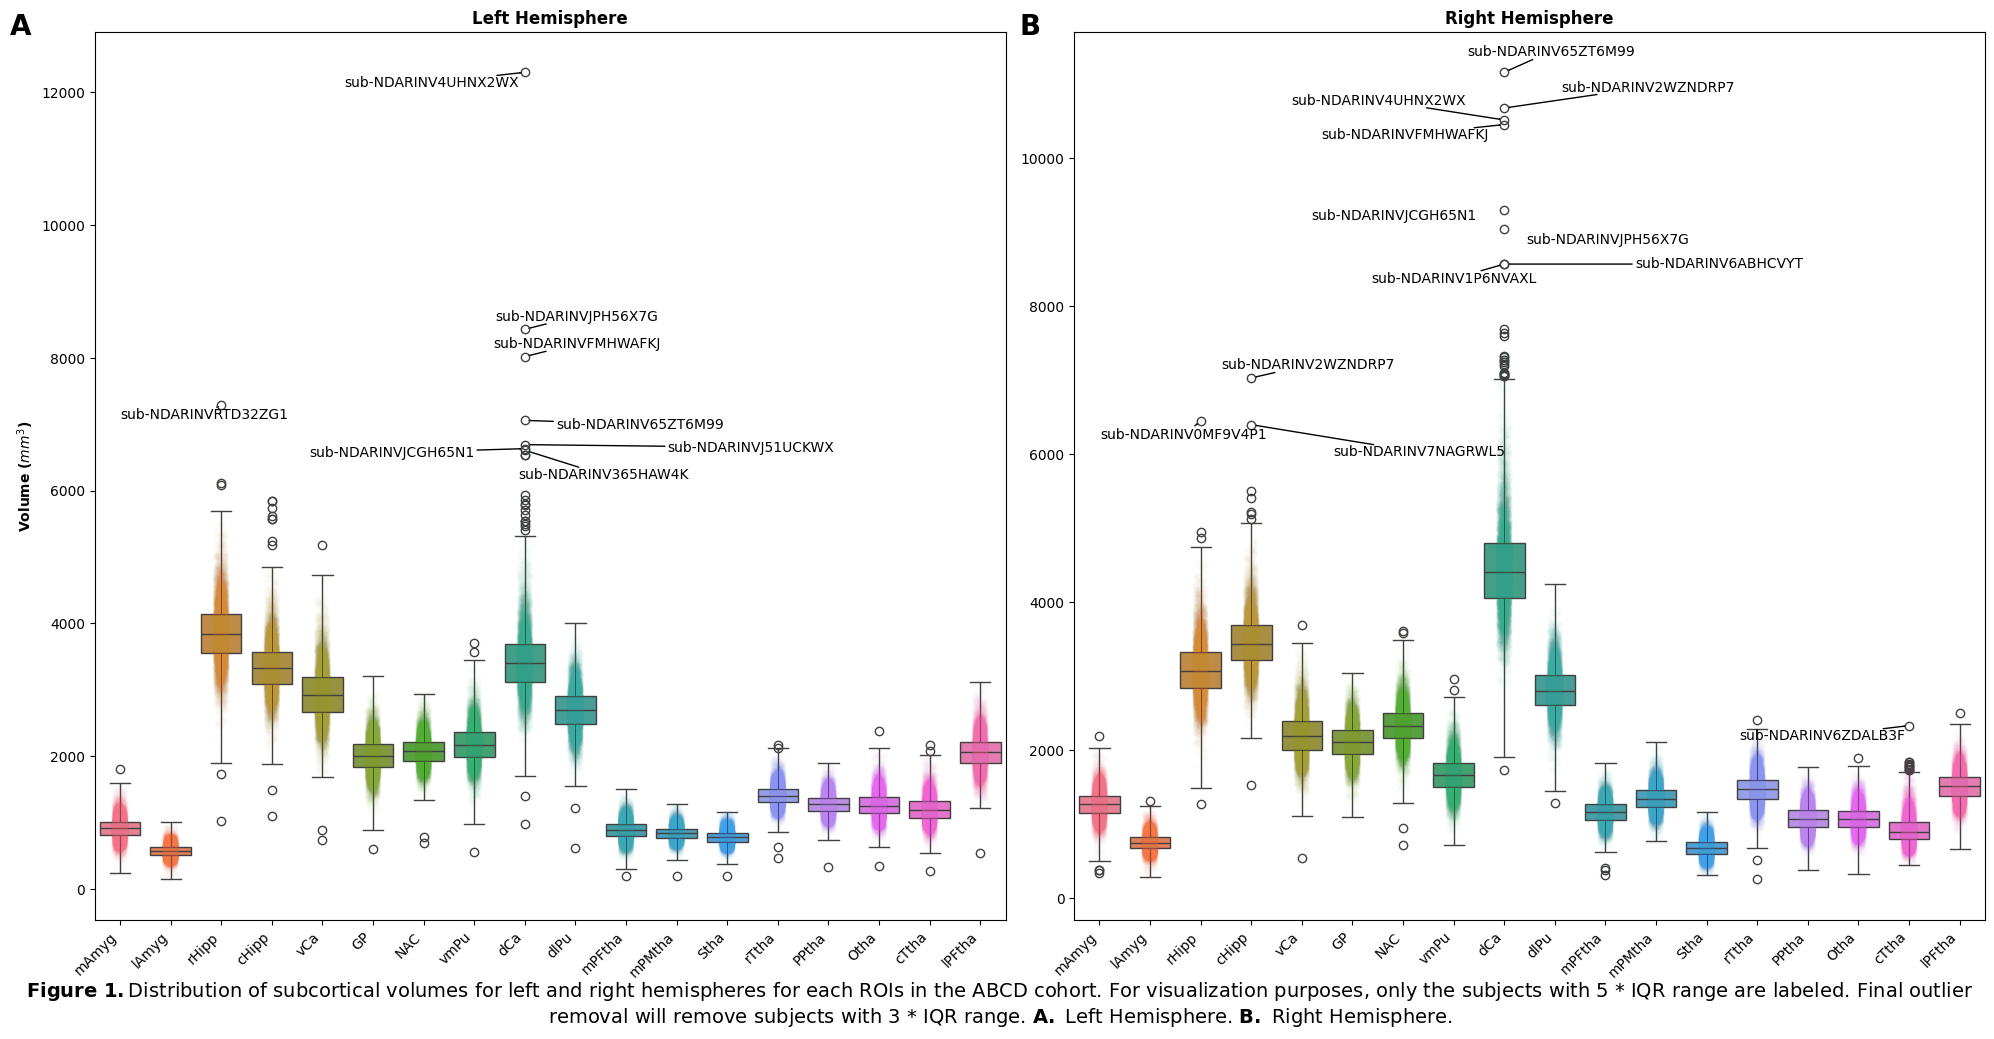

In [49]:
# Plotting the distribution of volumes for left and right hemispheres using a boxplot.
# Fetch left and right hemisphere ROIs.
left_hemisphere = [roi for roi in subcortical_df.columns if "L" in roi]
right_hemisphere = [roi for roi in subcortical_df.columns if "R" in roi]

# Plotting the distribution of volumes for left and right hemispheres using a boxplot.
fig, ax = plt.subplots(1, 2, figsize=(20, 10))

# Left hemisphere.
leftbox = sns.boxplot(data=subcortical_df[left_hemisphere], ax=ax[0], whis=3)
sns.stripplot(data=subcortical_df[left_hemisphere], ax=ax[0], alpha=0.01, palette="husl")
ax[0].set_title("Left Hemisphere", fontsize=12, fontweight='bold')
ax[0].set_ylabel("Volume ($mm^3$)", fontsize=10, fontweight='bold')
ax[0].set_xticklabels([roi.replace("_L", "") for roi in left_hemisphere])
ax[0].figure.autofmt_xdate(rotation=45, ha='right')

# Right hemisphere.
rightbox = sns.boxplot(data=subcortical_df[right_hemisphere], ax=ax[1], whis=3)
sns.stripplot(data=subcortical_df[right_hemisphere], ax=ax[1], alpha=0.01, palette="husl")
ax[1].set_title("Right Hemisphere", fontsize=12, fontweight='bold')
ax[1].set_xticklabels([roi.replace("_R", "") for roi in right_hemisphere])
ax[1].figure.autofmt_xdate(rotation=45, ha='right')

# Add subject id to points outside the 5 * IQR range for the left hemisphere.
iqr = []
for roi in left_hemisphere:
    q75, q25 = np.percentile(subcortical_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (5 * intr_qr)
    qmin = q25 - (5 * intr_qr)
    iqr.append([qmin, qmax])

text = []
for i, roi in enumerate(left_hemisphere):
    for j, val in enumerate(subcortical_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            text.append(ax[0].text(i, val, subcortical_df["subjectkey"][j], ha='center', va='center', fontsize=10, color='black'))
adjust_text(text, ax=ax[0], iter_lim=1000, arrowprops=dict(arrowstyle='->', color='black'))

# Add subject id to points outside the 5 * IQR range for the right hemisphere. (For visualization purposes)
iqr = []
for roi in right_hemisphere:
    q75, q25 = np.percentile(subcortical_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (5 * intr_qr)
    qmin = q25 - (5 * intr_qr)
    iqr.append([qmin, qmax])

text = []
for i, roi in enumerate(right_hemisphere):
    for j, val in enumerate(subcortical_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            text.append(ax[1].text(i, val, subcortical_df["subjectkey"][j], ha='center', va='center', fontsize=10, color='black'))
adjust_text(text, ax=ax[1], iter_lim=1000, arrowprops=dict(arrowstyle='->', color='black'))

txt = r"$\bf{"+str("Figure\ 1.")+"}$" + "Distribution of subcortical volumes for left and right hemispheres for each ROIs in the ABCD cohort. For visualization purposes, only the subjects with 5 * IQR range are labeled. Final outlier removal will remove subjects with 3 * IQR range. " + \
        r"$\bf{"+str("A.\ ")+"}$" + "Left Hemisphere. " + \
        r"$\bf{"+str("B.\ ")+"}$" + "Right Hemisphere."
plt.figtext(0.5, -0.025, txt, wrap=True, horizontalalignment='center', fontsize=14)

# Add label to subplots.
plt.gcf().text(0.005, 0.96, "A", fontsize=20, fontweight='bold')
plt.gcf().text(0.51, 0.96, "B", fontsize=20, fontweight='bold')

# Save the plot.
plt.tight_layout()
plt.savefig(f"{output_dir}/ABCD_subcortical_volumes_boxplot.png", dpi=600, bbox_inches='tight')

In [50]:
# Fetching the ID labels for the subjects with volumes outside the 3 * IQR range for all ROIs.
iqr = []
for roi in subcortical_df.columns[1:]:
    q75, q25 = np.percentile(subcortical_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

# Add subject id to points outside the 3 * IQR range for all ROIs.
ids = []
for i, roi in enumerate(subcortical_df.columns[1:]):
    for j, val in enumerate(subcortical_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            ids.append(subcortical_df["subjectkey"][j])

# Print the IDs of the subjects with volumes outside the 3 * IQR range for all ROIs.
print(f"Number of subjects with volumes outside the 3 * IQR range for all ROIs: {len(np.unique(ids))}")

# Remove subjects with volumes outside the 3 * IQR range for all ROIs.
subcortical_df_QCed = subcortical_df[~subcortical_df["subjectkey"].isin(ids)]
subcortical_df_QCed.reset_index(inplace=True, drop=True)
print(f"Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs: {subcortical_df_QCed.shape[0]}")

# Save the cleaned subcortical data.
subcortical_df_QCed.to_csv(f"{output_dir}/ABCD_subcortical_volumes_QCed.csv", index=False, header=True)

Number of subjects with volumes outside the 3 * IQR range for all ROIs: 74
Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs: 9206


/var/folders/23/p0fh1nrd473dtfz3cx_4g0j00000gn/T/ipykernel_92011/3910759949.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[0].set_xticklabels([roi.replace("_L", "") for roi in left_hemisphere])
/var/folders/23/p0fh1nrd473dtfz3cx_4g0j00000gn/T/ipykernel_92011/3910759949.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[1].set_xticklabels([roi.replace("_R", "") for roi in right_hemisphere])


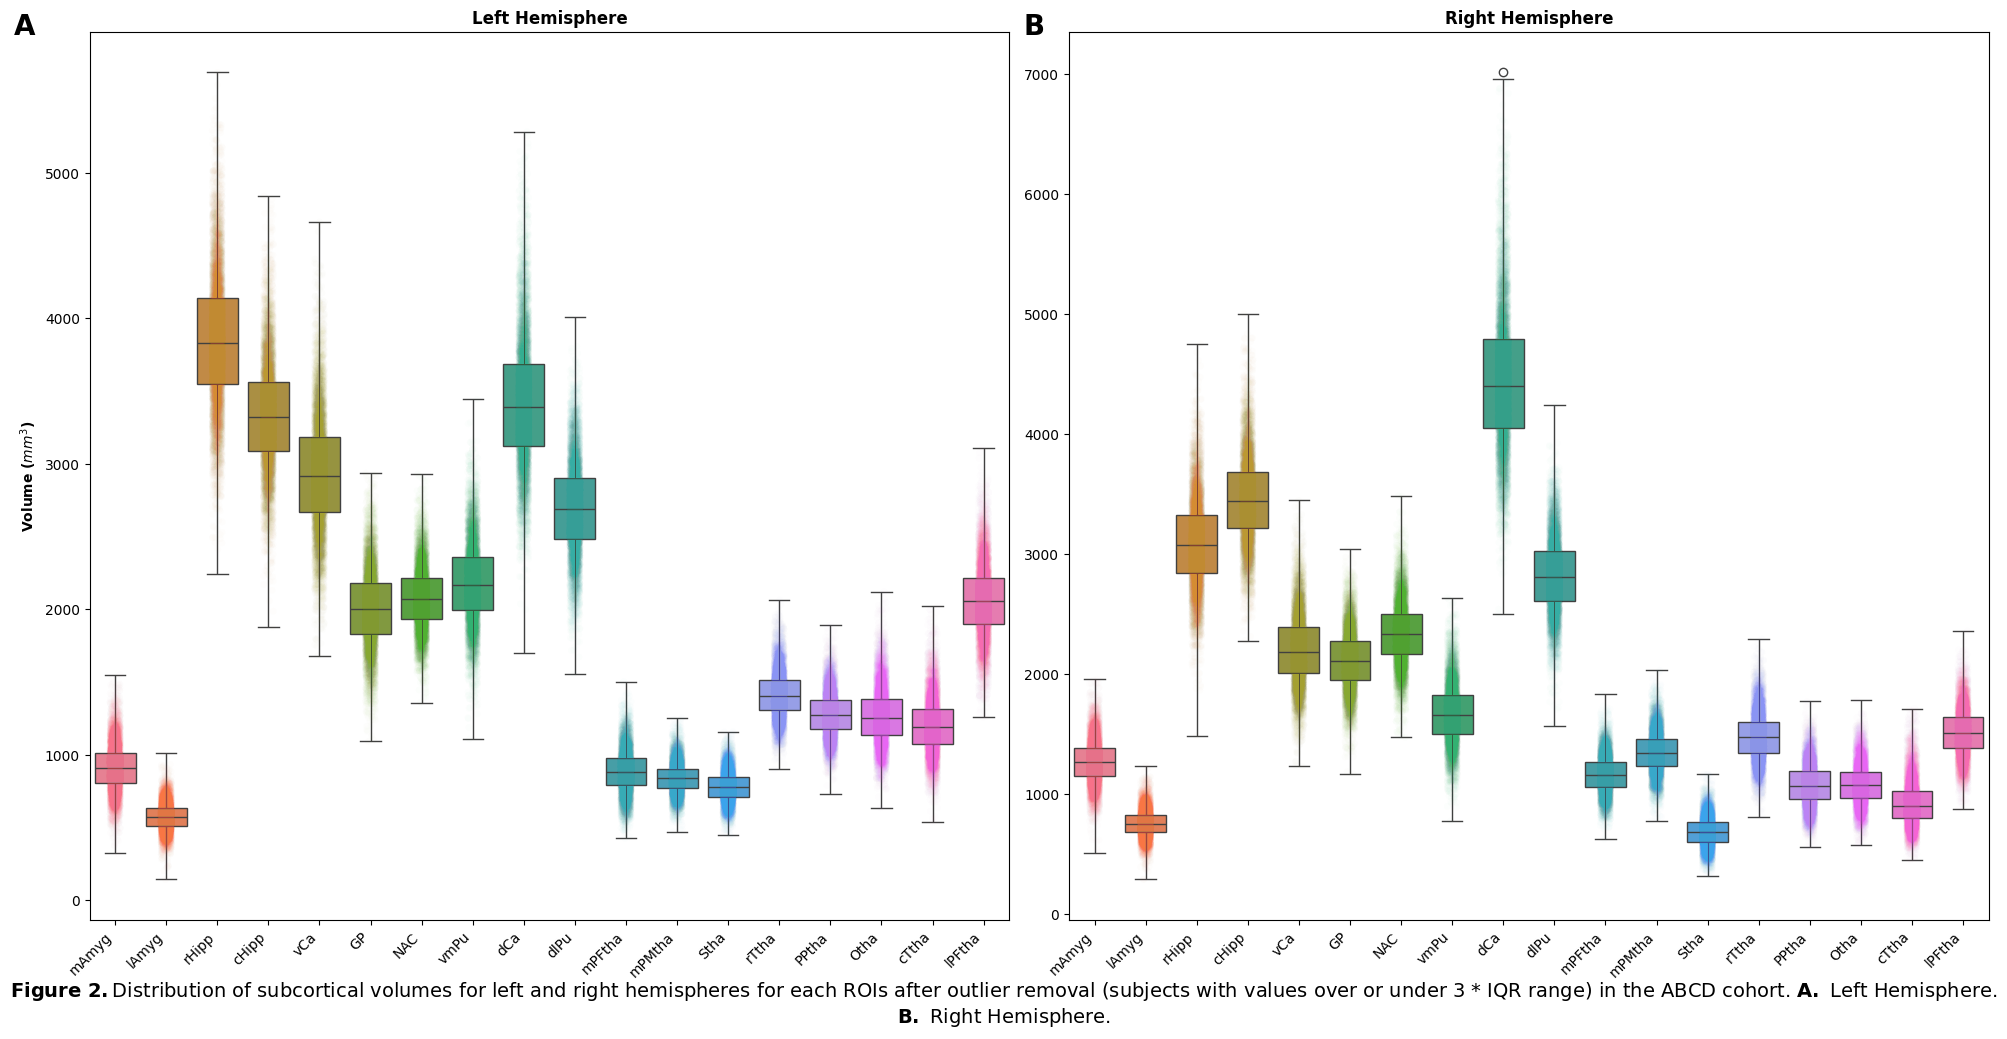

In [52]:
# Plotting the distribution of volumes for left and right hemispheres using a boxplot.

fig, ax = plt.subplots(1, 2, figsize=(20, 10))

# Left hemisphere.
leftbox = sns.boxplot(data=subcortical_df_QCed[left_hemisphere], ax=ax[0], whis=3)
sns.stripplot(data=subcortical_df_QCed[left_hemisphere], ax=ax[0], alpha=0.01, palette="husl")
ax[0].set_title("Left Hemisphere", fontsize=12, fontweight='bold')
ax[0].set_ylabel("Volume ($mm^3$)", fontsize=10, fontweight='bold')
ax[0].set_xticklabels([roi.replace("_L", "") for roi in left_hemisphere])
ax[0].figure.autofmt_xdate(rotation=45, ha='right')

# Right hemisphere.
rightbox = sns.boxplot(data=subcortical_df_QCed[right_hemisphere], ax=ax[1], whis=3)
sns.stripplot(data=subcortical_df_QCed[right_hemisphere], ax=ax[1], alpha=0.01, palette="husl")
ax[1].set_title("Right Hemisphere", fontsize=12, fontweight='bold')
ax[1].set_xticklabels([roi.replace("_R", "") for roi in right_hemisphere])
ax[1].figure.autofmt_xdate(rotation=45, ha='right')

txt = r"$\bf{"+str("Figure\ 2.")+"}$" + "Distribution of subcortical volumes for left and right hemispheres for each ROIs after outlier removal (subjects with values over or under 3 * IQR range) in the ABCD cohort. " + \
        r"$\bf{"+str("A.\ ")+"}$" + "Left Hemisphere. " + \
        r"$\bf{"+str("B.\ ")+"}$" + "Right Hemisphere."
plt.figtext(0.5, -0.025, txt, wrap=True, horizontalalignment='center', fontsize=14)

# Add label to subplots.
plt.gcf().text(0.005, 0.96, "A", fontsize=20, fontweight='bold')
plt.gcf().text(0.51, 0.96, "B", fontsize=20, fontweight='bold')

# Save the plot.
plt.tight_layout()
plt.savefig(f"{output_dir}/ABCD_subcortical_volumes_boxplot_QCed.png", dpi=600, bbox_inches='tight')

In [53]:
# Load cortical data.
thickness_df = load_df_in_any_format(f"{data_abcd}/AnatomicalStats/ABCD_left_cortical_thickness.csv")
volume_df = load_df_in_any_format(f"{data_abcd}/AnatomicalStats/ABCD_left_cortical_volume.csv")
area_df = load_df_in_any_format(f"{data_abcd}/AnatomicalStats/ABCD_left_cortical_area.csv")

# Rename the subject ID column.
thickness_df = thickness_df.rename(columns={"lh.BN_child.thickness": "subjectkey"})
volume_df = volume_df.rename(columns={"lh.BN_child.volume": "subjectkey"})
area_df = area_df.rename(columns={"lh.BN_child.area": "subjectkey"})

# Dropping eTIV, cluster94, mean, brainsegnotvent.
thickness_df = thickness_df.drop(["eTIV", "lh_cluster94_thickness", "lh_MeanThickness_thickness", "BrainSegVolNotVent"], axis=1)
volume_df = volume_df.drop(["eTIV", "lh_cluster94_volume", "BrainSegVolNotVent"], axis=1)
area_df = area_df.drop(["eTIV", "lh_cluster94_area", "lh_WhiteSurfArea_area", "BrainSegVolNotVent"], axis=1)

# Filter out subjects with all 0 values for all ROIs and print their IDs.
zero_subs = thickness_df[thickness_df.iloc[:, 1:].sum(axis=1) == 0]
zero_subs_ids = zero_subs["subjectkey"].to_list()
print(f"Number of subjects with 0 values for all ROIs in thickness data: {len(zero_subs_ids)}")
print(f"IDs of subjects with 0 values for all ROIs in thickness data: {zero_subs_ids}")

zero_subs = volume_df[volume_df.iloc[:, 1:].sum(axis=1) == 0]
zero_subs_ids = zero_subs["subjectkey"].to_list()
print(f"Number of subjects with 0 values for all ROIs in volume data: {len(zero_subs_ids)}")
print(f"IDs of subjects with 0 values for all ROIs in volume data: {zero_subs_ids}")

zero_subs = area_df[area_df.iloc[:, 1:].sum(axis=1) == 0]
zero_subs_ids = zero_subs["subjectkey"].to_list()
print(f"Number of subjects with 0 values for all ROIs in area data: {len(zero_subs_ids)}")
print(f"IDs of subjects with 0 values for all ROIs in area data: {zero_subs_ids}")

# Drop subjects with all 0 values for all ROIs.
thickness_df = thickness_df[thickness_df.iloc[:, 1:].sum(axis=1) != 0]
thickness_df.reset_index(inplace=True, drop=True)

volume_df = volume_df[volume_df.iloc[:, 1:].sum(axis=1) != 0]
volume_df.reset_index(inplace=True, drop=True)

area_df = area_df[area_df.iloc[:, 1:].sum(axis=1) != 0]
area_df.reset_index(inplace=True, drop=True)

# Replace column names with clean ROI names.
rois = [roi.replace("lh_", "") for roi in thickness_df.columns[1:]]
rois = [roi.replace("_thickness", "") for roi in rois]

thickness_df.columns = ["subjectkey"] + rois
volume_df.columns = ["subjectkey"] + rois
area_df.columns = ["subjectkey"] + rois

# Print the number of subjects and number of ROIs.
subs, rois = thickness_df.shape
print(f"Number of subjects in thickness data: {subs}")
print(f"Number of ROIs in thickness data: {rois - 1}") # Excluding the subject ID column.

subs, rois = volume_df.shape
print(f"Number of subjects in volume data: {subs}")
print(f"Number of ROIs in volume data: {rois - 1}") # Excluding the subject ID column.

subs, rois = area_df.shape
print(f"Number of subjects in area data: {subs}")
print(f"Number of ROIs in area data: {rois - 1}") # Excluding the subject ID column.

Number of subjects with 0 values for all ROIs in thickness data: 0
IDs of subjects with 0 values for all ROIs in thickness data: []
Number of subjects with 0 values for all ROIs in volume data: 0
IDs of subjects with 0 values for all ROIs in volume data: []
Number of subjects with 0 values for all ROIs in area data: 0
IDs of subjects with 0 values for all ROIs in area data: []
Number of subjects in thickness data: 9281
Number of ROIs in thickness data: 94
Number of subjects in volume data: 9281
Number of ROIs in volume data: 94
Number of subjects in area data: 9281
Number of ROIs in area data: 94


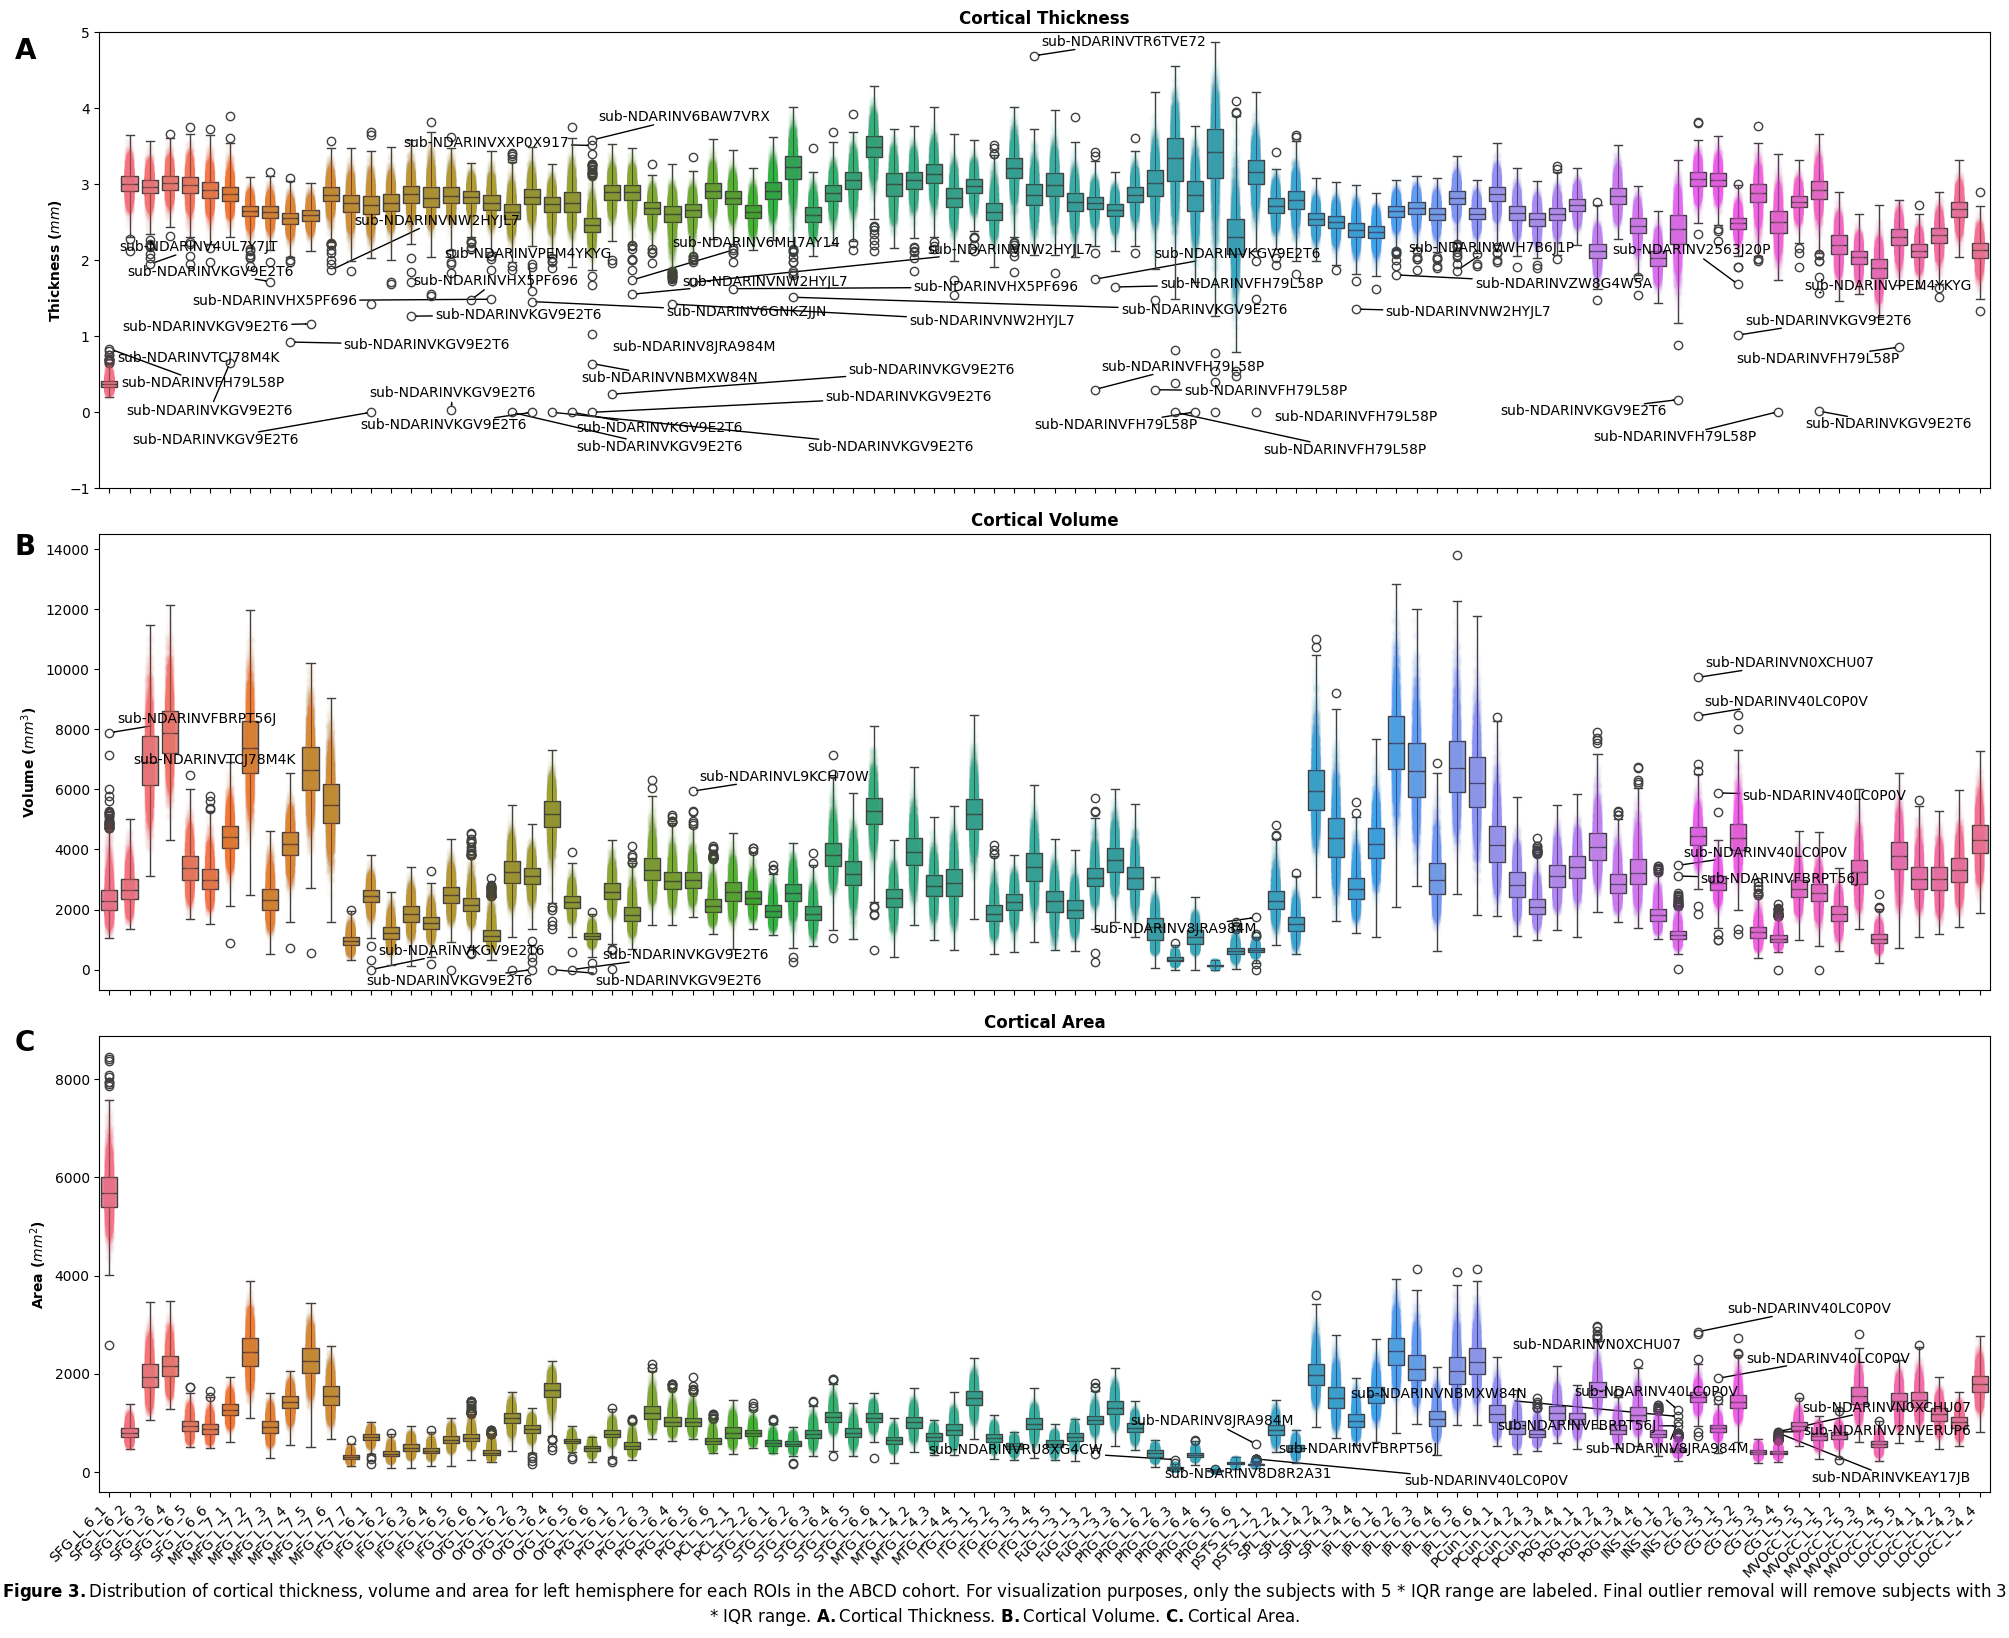

In [54]:
# Plotting the distribution of thickness, volume and area for left hemisphere using a boxplot.

fig, ax = plt.subplots(3, 1, figsize=(20, 16))

# Thickness.
thicknessbox = sns.boxplot(data=thickness_df.iloc[:, 1:], ax=ax[0], whis=3)
sns.stripplot(data=thickness_df.iloc[:, 1:], ax=ax[0], alpha=0.01, palette="husl")
ax[0].set_title("Cortical Thickness", fontsize=12, fontweight='bold')
ax[0].set_ylabel("Thickness ($mm$)", fontsize=10, fontweight='bold')
ax[0].figure.autofmt_xdate(rotation=45, ha='right')
ax[0].set_ylim(-1, 5)

# Add subject id to points outside the 5 * IQR range for the thickness data.
iqr = []
for roi in thickness_df.columns[1:]:
    q75, q25 = np.percentile(thickness_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (5 * intr_qr)
    qmin = q25 - (5 * intr_qr)
    iqr.append([qmin, qmax])

text = []
for i, roi in enumerate(thickness_df.columns[1:]):
    for j, val in enumerate(thickness_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            text.append(ax[0].text(i, val, thickness_df["subjectkey"][j], ha='center', va='center', fontsize=10, color='black'))
adjust_text(text, ax=ax[0], iter_lim=1000, arrowprops=dict(arrowstyle='->', color='black'))

# Volume.
volumebox = sns.boxplot(data=volume_df.iloc[:, 1:], ax=ax[1], whis=3)
sns.stripplot(data=volume_df.iloc[:, 1:], ax=ax[1], alpha=0.01, palette="husl")
ax[1].set_title("Cortical Volume", fontsize=12, fontweight='bold')
ax[1].set_ylabel("Volume ($mm^3$)", fontsize=10, fontweight='bold')
ax[1].figure.autofmt_xdate(rotation=45, ha='right')

# Add subject id to points outside the 5 * IQR range for the volume data.
iqr = []
for roi in volume_df.columns[1:]:
    q75, q25 = np.percentile(volume_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (5 * intr_qr)
    qmin = q25 - (5 * intr_qr)
    iqr.append([qmin, qmax])

text = []
for i, roi in enumerate(volume_df.columns[1:]):
    for j, val in enumerate(volume_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            text.append(ax[1].text(i, val, volume_df["subjectkey"][j], ha='center', va='center', fontsize=10, color='black'))
adjust_text(text, ax=ax[1], iter_lim=1000, arrowprops=dict(arrowstyle='->', color='black'))

# Area.
areabox = sns.boxplot(data=area_df.iloc[:, 1:], ax=ax[2], whis=3)
sns.stripplot(data=area_df.iloc[:, 1:], ax=ax[2], alpha=0.01, palette="husl")
ax[2].set_title("Cortical Area", fontsize=12, fontweight='bold')
ax[2].set_ylabel("Area ($mm^2$)", fontsize=10, fontweight='bold')
ax[2].figure.autofmt_xdate(rotation=45, ha='right')

# Add subject id to points outside the 5 * IQR range for the area data.
iqr = []
for roi in area_df.columns[1:]:
    q75, q25 = np.percentile(area_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (5 * intr_qr)
    qmin = q25 - (5 * intr_qr)
    iqr.append([qmin, qmax])

text = []
for i, roi in enumerate(area_df.columns[1:]):
    for j, val in enumerate(area_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            text.append(ax[2].text(i, val, area_df["subjectkey"][j], ha='center', va='center', fontsize=10, color='black'))
adjust_text(text, ax=ax[2], iter_lim=1000, arrowprops=dict(arrowstyle='->', color='black'))

txt = r"$\bf{"+str("Figure\ 3.")+"}$" + "Distribution of cortical thickness, volume and area for left hemisphere for each ROIs in the ABCD cohort. " + \
        "For visualization purposes, only the subjects with 5 * IQR range are labeled. Final outlier removal will remove subjects with 3 * IQR range. " + \
        r"$\bf{"+"A."+"}$" + "Cortical Thickness. " + r"$\bf{"+"B."+"}$" + "Cortical Volume. " + r"$\bf{"+"C."+"}$" + "Cortical Area."

plt.figtext(0.5, -0.015, txt, wrap=True, horizontalalignment='center', fontsize=12)

# Add label to subplots.
plt.gcf().text(0.005, 0.96, "A", fontsize=20, fontweight='bold')
plt.gcf().text(0.005, 0.65, "B", fontsize=20, fontweight='bold')
plt.gcf().text(0.005, 0.34, "C", fontsize=20, fontweight='bold')

# Save the plot.
plt.tight_layout()
plt.savefig(f"{output_dir}/ABCD_cortical_thickness_volume_area_boxplot_left_hemi.png", dpi=900, bbox_inches='tight')


In [55]:
# Fetching the ID labels for the subjects with volumes outside the 3 * IQR range for all ROIs.
iqr = []
for roi in thickness_df.columns[1:]:
    q75, q25 = np.percentile(thickness_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

# Add subject id to points outside the 3 * IQR range for all ROIs.
thick_ids = []
for i, roi in enumerate(thickness_df.columns[1:]):
    for j, val in enumerate(thickness_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            thick_ids.append(thickness_df["subjectkey"][j])

# Print the IDs of the subjects with volumes outside the 3 * IQR range for all ROIs.
print(f"Number of subjects with volumes outside the 3 * IQR range for all ROIs in thickness data: {len(np.unique(thick_ids))}")

# Remove subjects with volumes outside the 3 * IQR range for all ROIs.
thickness_df_QCed = thickness_df[~thickness_df["subjectkey"].isin(thick_ids)]
thickness_df_QCed.reset_index(inplace=True, drop=True)
print(f"Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs in thickness data: {thickness_df_QCed.shape[0]}")

# Save the cleaned thickness data.
thickness_df_QCed.to_csv(f"{output_dir}/ABCD_left_cortical_thickness_QCed.csv", index=False, header=True)

# Fetching the ID labels for the subjects with volumes outside the 3 * IQR range for all ROIs.  
iqr = []
for roi in volume_df.columns[1:]:
    q75, q25 = np.percentile(volume_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

# Add subject id to points outside the 3 * IQR range for all ROIs.
vol_ids = []
for i, roi in enumerate(volume_df.columns[1:]):
    for j, val in enumerate(volume_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            vol_ids.append(volume_df["subjectkey"][j])

# Print the IDs of the subjects with volumes outside the 3 * IQR range for all ROIs.
print(f"Number of subjects with volumes outside the 3 * IQR range for all ROIs in volume data: {len(np.unique(vol_ids))}")

# Remove subjects with volumes outside the 3 * IQR range for all ROIs.
volume_df_QCed = volume_df[~volume_df["subjectkey"].isin(vol_ids)]
volume_df_QCed.reset_index(inplace=True, drop=True)
print(f"Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs in volume data: {volume_df_QCed.shape[0]}")

# Save the cleaned volume data.
volume_df_QCed.to_csv(f"{output_dir}/ABCD_left_cortical_volume_QCed.csv", index=False, header=True)

# Fetching the ID labels for the subjects with volumes outside the 3 * IQR range for all ROIs.
iqr = []
for roi in area_df.columns[1:]:
    q75, q25 = np.percentile(area_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

# Add subject id to points outside the 3 * IQR range for all ROIs.
area_ids = []
for i, roi in enumerate(area_df.columns[1:]):
    for j, val in enumerate(area_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            area_ids.append(area_df["subjectkey"][j])

# Print the IDs of the subjects with volumes outside the 3 * IQR range for all ROIs.
print(f"Number of subjects with volumes outside the 3 * IQR range for all ROIs in area data: {len(np.unique(area_ids))}")

# Remove subjects with volumes outside the 3 * IQR range for all ROIs.
area_df_QCed = area_df[~area_df["subjectkey"].isin(area_ids)]
area_df_QCed.reset_index(inplace=True, drop=True)
print(f"Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs in area data: {area_df_QCed.shape[0]}")

# Save the cleaned area data.
area_df_QCed.to_csv(f"{output_dir}/ABCD_left_cortical_area_QCed.csv", index=False, header=True)

# Looking at similarities between the excluded subjects in thickness, volume and area data.
excluded_subs_left = set(thick_ids).union(set(vol_ids)).union(set(area_ids))
print(f"Number of subjects excluded in thickness, volume and area data: {len(excluded_subs_left)}")


Number of subjects with volumes outside the 3 * IQR range for all ROIs in thickness data: 154
Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs in thickness data: 9127
Number of subjects with volumes outside the 3 * IQR range for all ROIs in volume data: 222
Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs in volume data: 9059
Number of subjects with volumes outside the 3 * IQR range for all ROIs in area data: 227
Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs in area data: 9054
Number of subjects excluded in thickness, volume and area data: 458


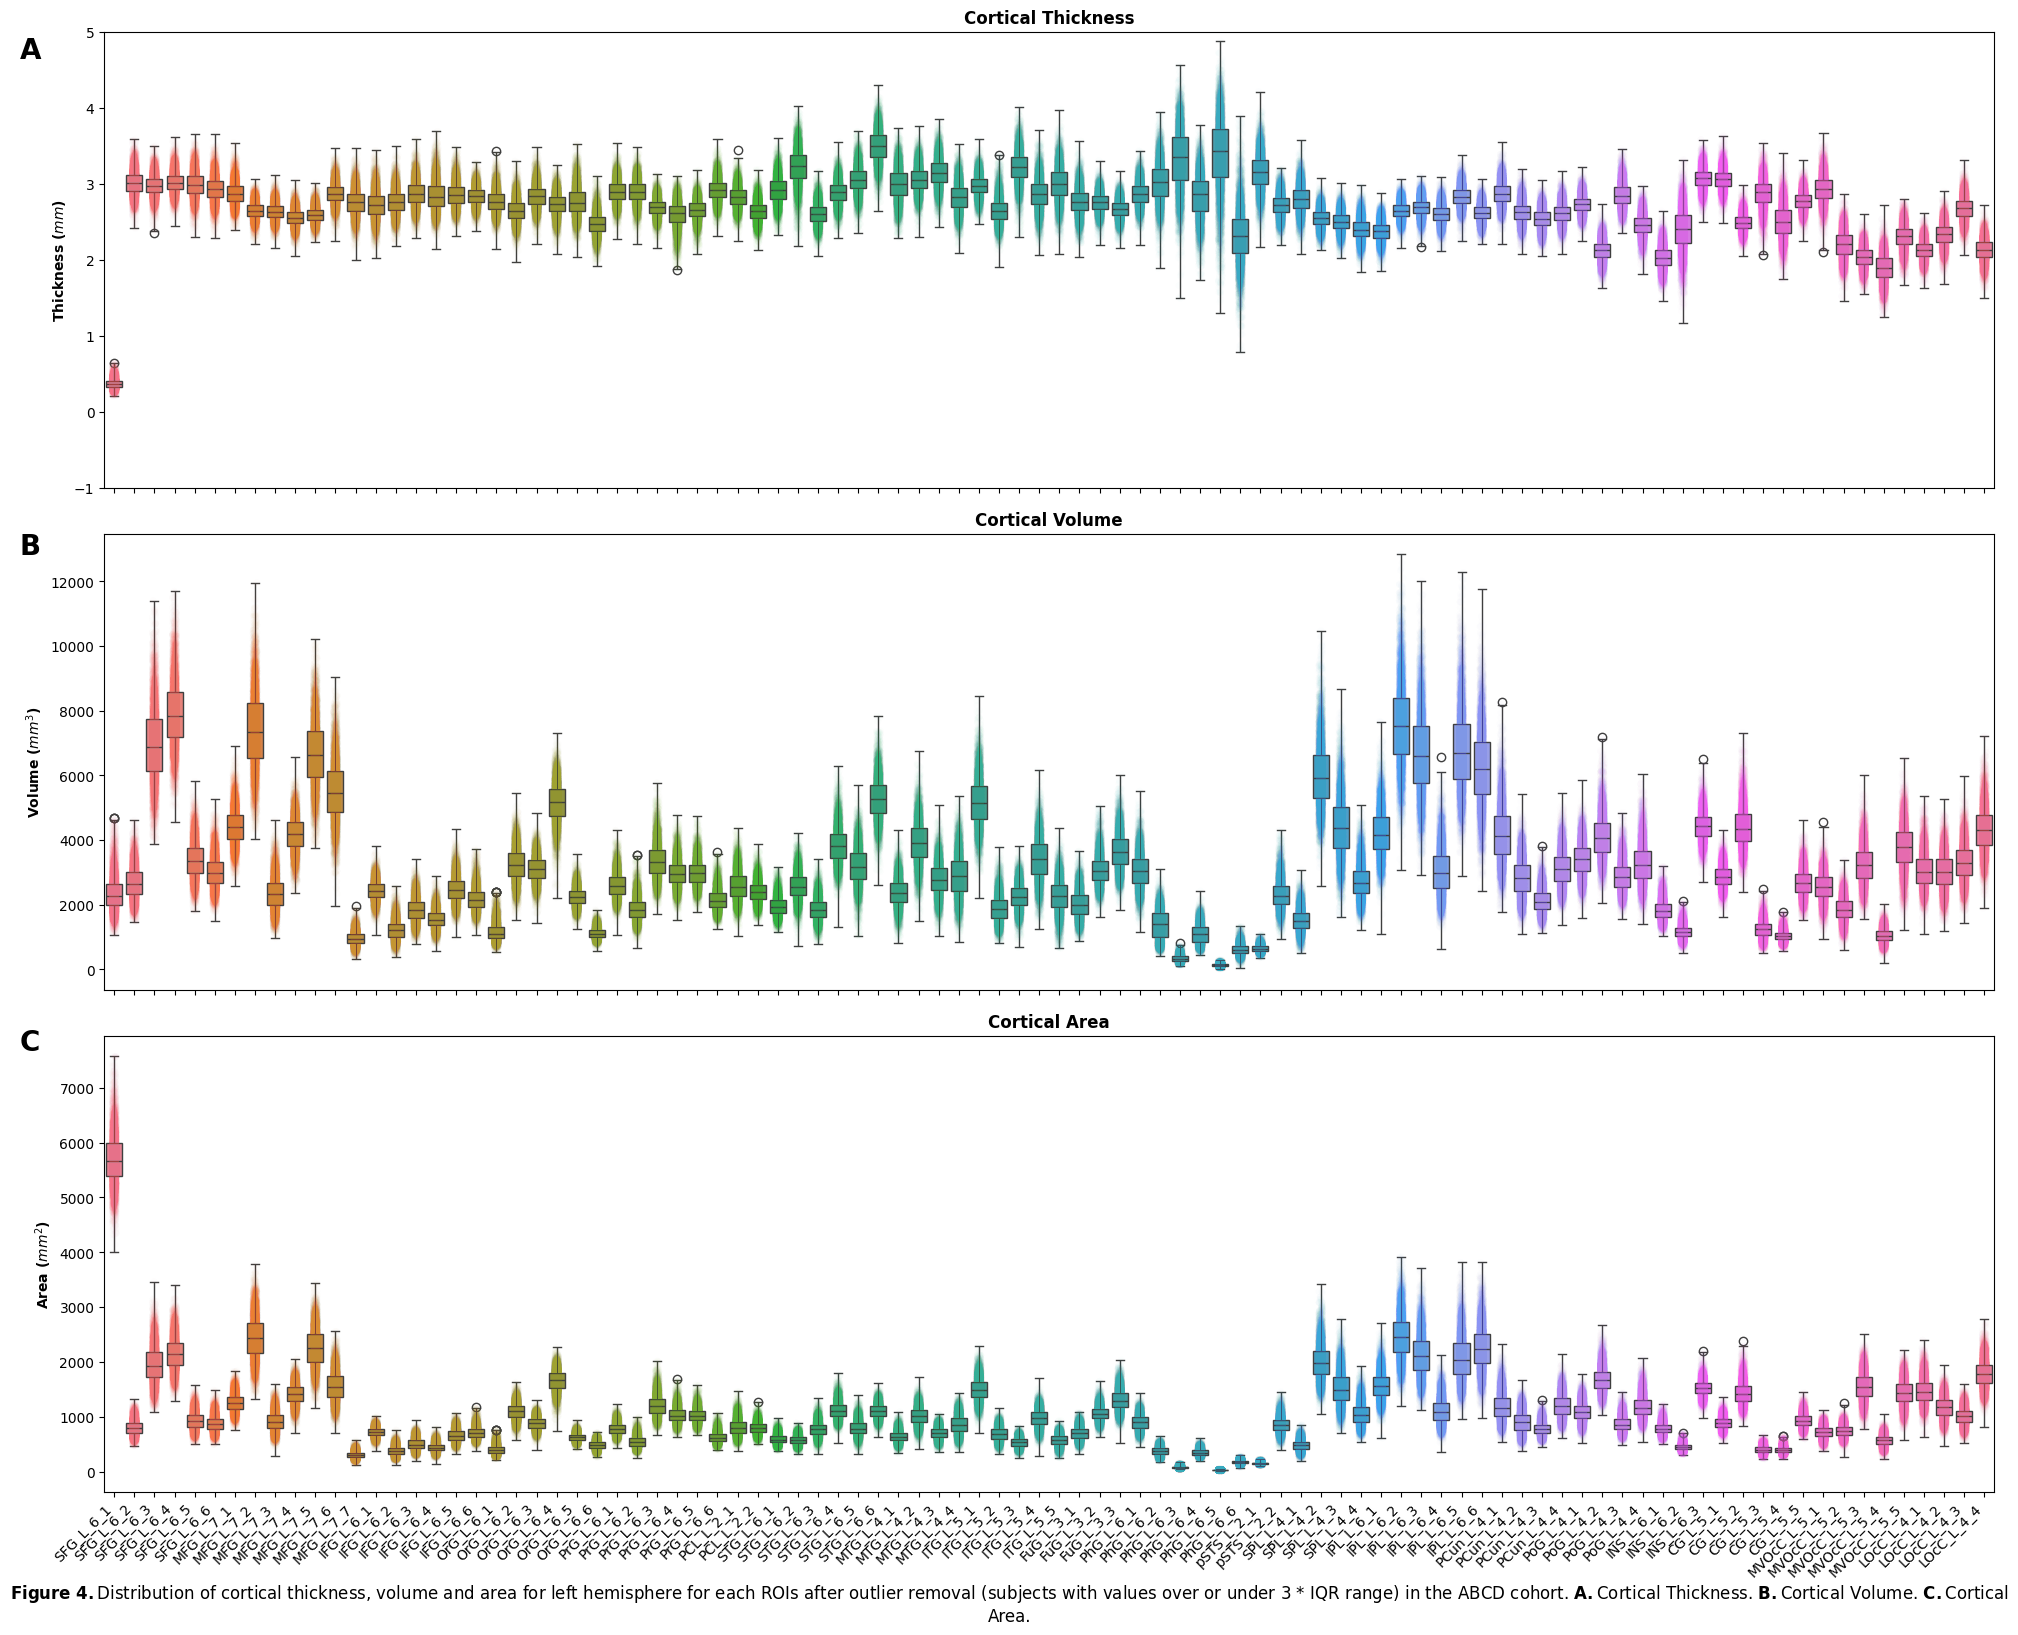

In [56]:
# Plotting the distribution of thickness, volume and area for left hemisphere using a boxplot after QC.

fig, ax = plt.subplots(3, 1, figsize=(20, 16))

# Thickness.
thicknessbox = sns.boxplot(data=thickness_df_QCed.iloc[:, 1:], ax=ax[0], whis=3)
sns.stripplot(data=thickness_df_QCed.iloc[:, 1:], ax=ax[0], alpha=0.01, palette="husl")
ax[0].set_title("Cortical Thickness", fontsize=12, fontweight='bold')
ax[0].set_ylabel("Thickness ($mm$)", fontsize=10, fontweight='bold')
ax[0].figure.autofmt_xdate(rotation=45, ha='right')
ax[0].set_ylim(-1, 5)

# Volume.
volumebox = sns.boxplot(data=volume_df_QCed.iloc[:, 1:], ax=ax[1], whis=3)
sns.stripplot(data=volume_df_QCed.iloc[:, 1:], ax=ax[1], alpha=0.01, palette="husl")
ax[1].set_title("Cortical Volume", fontsize=12, fontweight='bold')
ax[1].set_ylabel("Volume ($mm^3$)", fontsize=10, fontweight='bold')
ax[1].figure.autofmt_xdate(rotation=45, ha='right')

# Area.
areabox = sns.boxplot(data=area_df_QCed.iloc[:, 1:], ax=ax[2], whis=3)
sns.stripplot(data=area_df_QCed.iloc[:, 1:], ax=ax[2], alpha=0.01, palette="husl")
ax[2].set_title("Cortical Area", fontsize=12, fontweight='bold')
ax[2].set_ylabel("Area ($mm^2$)", fontsize=10, fontweight='bold')
ax[2].figure.autofmt_xdate(rotation=45, ha='right')

txt = r"$\bf{"+str("Figure\ 4.")+"}$" + "Distribution of cortical thickness, volume and area for left hemisphere for each ROIs after outlier removal (subjects with values over or under 3 * IQR range) in the ABCD cohort. " + \
        r"$\bf{"+"A."+"}$" + "Cortical Thickness. " + r"$\bf{"+"B."+"}$" + "Cortical Volume. " + r"$\bf{"+"C."+"}$" + "Cortical Area."

plt.figtext(0.5, -0.015, txt, wrap=True, horizontalalignment='center', fontsize=12)

# Add label to subplots.
plt.gcf().text(0.005, 0.96, "A", fontsize=20, fontweight='bold')
plt.gcf().text(0.005, 0.65, "B", fontsize=20, fontweight='bold')
plt.gcf().text(0.005, 0.34, "C", fontsize=20, fontweight='bold')

# Save the plot.
plt.tight_layout()
plt.savefig(f"{output_dir}/ABCD_cortical_thickness_volume_area_boxplot_left_hemi_QCed.png", dpi=900, bbox_inches='tight')

In [57]:
# Load cortical data for the right hemisphere.
thickness_df = load_df_in_any_format(f"{data_abcd}/AnatomicalStats/ABCD_right_cortical_thickness.csv")
volume_df = load_df_in_any_format(f"{data_abcd}/AnatomicalStats/ABCD_right_cortical_volume.csv")
area_df = load_df_in_any_format(f"{data_abcd}/AnatomicalStats/ABCD_right_cortical_area.csv")

# Rename the subject ID column.
thickness_df = thickness_df.rename(columns={"rh.BN_child.thickness": "subjectkey"})
volume_df = volume_df.rename(columns={"rh.BN_child.volume": "subjectkey"})
area_df = area_df.rename(columns={"rh.BN_child.area": "subjectkey"})
thickness_df = thickness_df.drop(["eTIV", "rh_cluster94_thickness", "rh_MeanThickness_thickness", "BrainSegVolNotVent"], axis=1)
volume_df = volume_df.drop(["eTIV", "rh_cluster94_volume", "BrainSegVolNotVent"], axis=1)
area_df = area_df.drop(["eTIV", "rh_cluster94_area", "rh_WhiteSurfArea_area", "BrainSegVolNotVent"], axis=1)

# Filter out subjects with all 0 values for all ROIs and print their IDs.
zero_subs = thickness_df[thickness_df.iloc[:, 1:].sum(axis=1) == 0]
zero_subs_ids = zero_subs["subjectkey"].to_list()
print(f"Number of subjects with 0 values for all ROIs in thickness data: {len(zero_subs_ids)}")
print(f"IDs of subjects with 0 values for all ROIs in thickness data: {zero_subs_ids}")

zero_subs = volume_df[volume_df.iloc[:, 1:].sum(axis=1) == 0]
zero_subs_ids = zero_subs["subjectkey"].to_list()
print(f"Number of subjects with 0 values for all ROIs in volume data: {len(zero_subs_ids)}")
print(f"IDs of subjects with 0 values for all ROIs in volume data: {zero_subs_ids}")

zero_subs = area_df[area_df.iloc[:, 1:].sum(axis=1) == 0]
zero_subs_ids = zero_subs["subjectkey"].to_list()
print(f"Number of subjects with 0 values for all ROIs in area data: {len(zero_subs_ids)}")
print(f"IDs of subjects with 0 values for all ROIs in area data: {zero_subs_ids}")

# Drop subjects with all 0 values for all ROIs.
thickness_df = thickness_df[thickness_df.iloc[:, 1:].sum(axis=1) != 0]
thickness_df.reset_index(inplace=True, drop=True)

volume_df = volume_df[volume_df.iloc[:, 1:].sum(axis=1) != 0]
volume_df.reset_index(inplace=True, drop=True)

area_df = area_df[area_df.iloc[:, 1:].sum(axis=1) != 0]
area_df.reset_index(inplace=True, drop=True)

# Replace column names with clean ROI names.
rois = [roi.replace("rh_", "") for roi in thickness_df.columns[1:]]
rois = [roi.replace("_thickness", "") for roi in rois]

thickness_df.columns = ["subjectkey"] + rois
volume_df.columns = ["subjectkey"] + rois
area_df.columns = ["subjectkey"] + rois

# Print the number of subjects and number of ROIs.
subs, rois = thickness_df.shape
print(f"Number of subjects in thickness data: {subs}")
print(f"Number of ROIs in thickness data: {rois - 1}") # Excluding the subject ID column.

subs, rois = volume_df.shape
print(f"Number of subjects in volume data: {subs}")
print(f"Number of ROIs in volume data: {rois - 1}") # Excluding the subject ID column.

subs, rois = area_df.shape
print(f"Number of subjects in area data: {subs}")
print(f"Number of ROIs in area data: {rois - 1}") # Excluding the subject ID column.


Number of subjects with 0 values for all ROIs in thickness data: 0
IDs of subjects with 0 values for all ROIs in thickness data: []
Number of subjects with 0 values for all ROIs in volume data: 0
IDs of subjects with 0 values for all ROIs in volume data: []
Number of subjects with 0 values for all ROIs in area data: 0
IDs of subjects with 0 values for all ROIs in area data: []
Number of subjects in thickness data: 9281
Number of ROIs in thickness data: 94
Number of subjects in volume data: 9281
Number of ROIs in volume data: 94
Number of subjects in area data: 9281
Number of ROIs in area data: 94


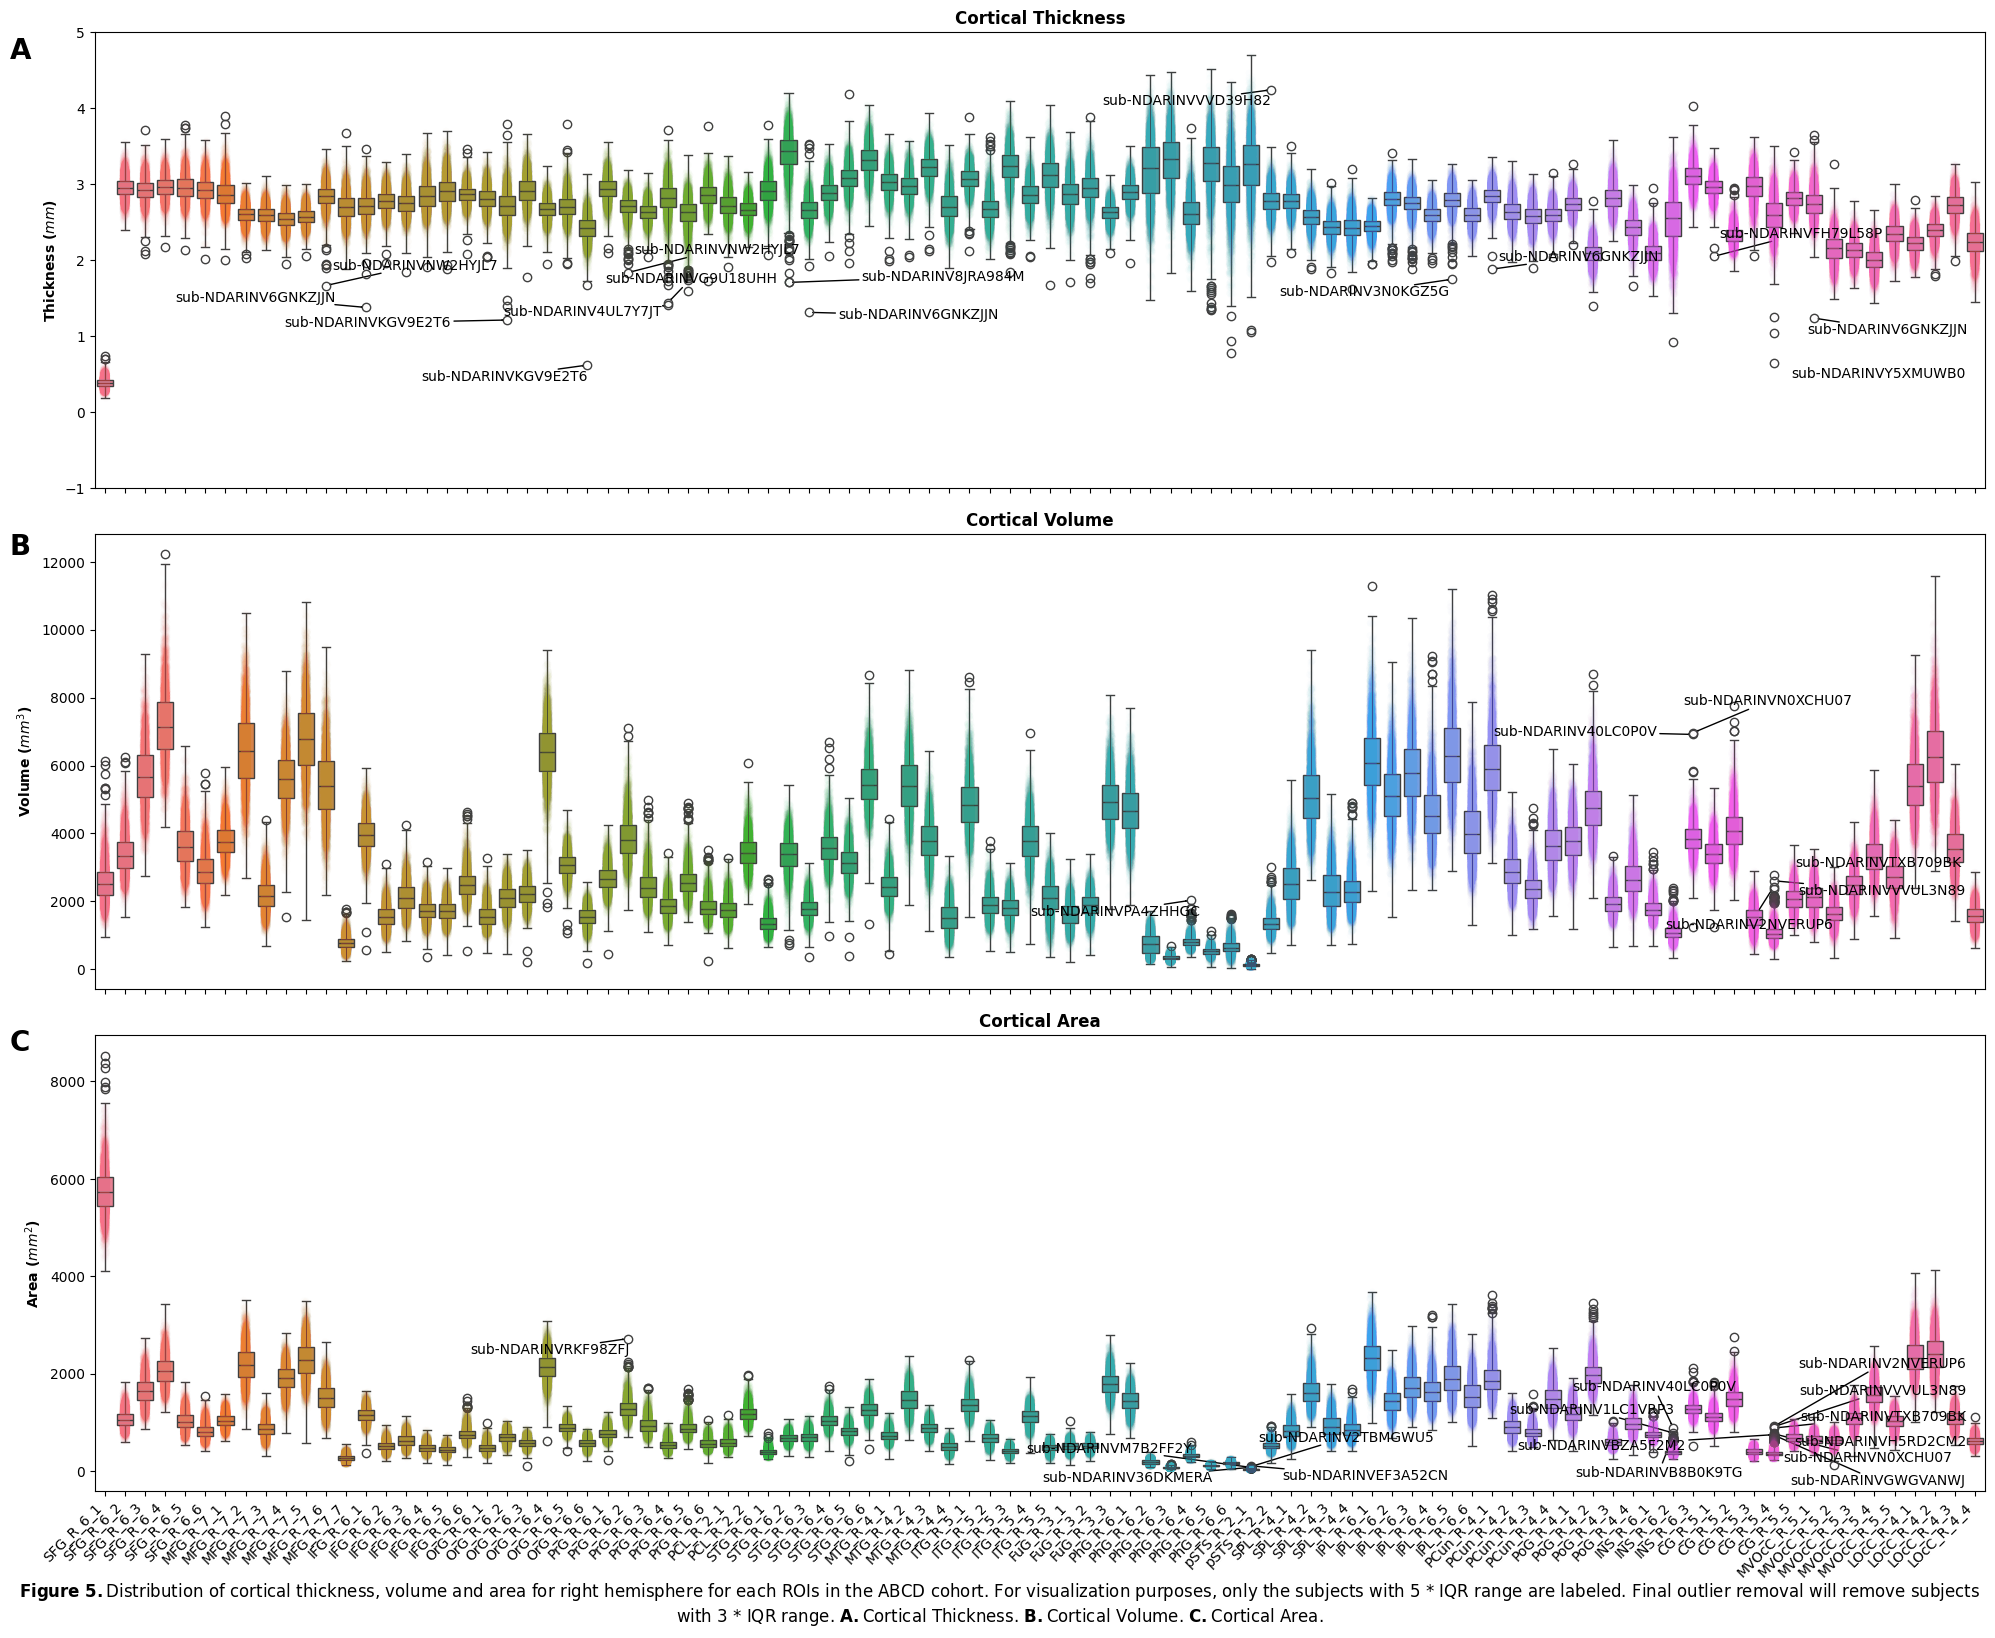

In [58]:
# Plotting the distribution of thickness, volume and area for right hemisphere using a boxplot.

fig, ax = plt.subplots(3, 1, figsize=(20, 16))

# Thickness.
thicknessbox = sns.boxplot(data=thickness_df.iloc[:, 1:], ax=ax[0], whis=3)
sns.stripplot(data=thickness_df.iloc[:, 1:], ax=ax[0], alpha=0.01, palette="husl")
ax[0].set_title("Cortical Thickness", fontsize=12, fontweight='bold')
ax[0].set_ylabel("Thickness ($mm$)", fontsize=10, fontweight='bold')
ax[0].figure.autofmt_xdate(rotation=45, ha='right')
ax[0].set_ylim(-1, 5)

# Add subject id to points outside the 5 * IQR range for the thickness data.
iqr = []
for roi in thickness_df.columns[1:]:
    q75, q25 = np.percentile(thickness_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (5 * intr_qr)
    qmin = q25 - (5 * intr_qr)
    iqr.append([qmin, qmax])

text = []
for i, roi in enumerate(thickness_df.columns[1:]):
    for j, val in enumerate(thickness_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            text.append(ax[0].text(i, val, thickness_df["subjectkey"][j], ha='center', va='center', fontsize=10, color='black'))
adjust_text(text, ax=ax[0], iter_lim=1000, arrowprops=dict(arrowstyle='->', color='black'))

# Volume.
volumebox = sns.boxplot(data=volume_df.iloc[:, 1:], ax=ax[1], whis=3)
sns.stripplot(data=volume_df.iloc[:, 1:], ax=ax[1], alpha=0.01, palette="husl")
ax[1].set_title("Cortical Volume", fontsize=12, fontweight='bold')
ax[1].set_ylabel("Volume ($mm^3$)", fontsize=10, fontweight='bold')
ax[1].figure.autofmt_xdate(rotation=45, ha='right')

# Add subject id to points outside the 5 * IQR range for the volume data.
iqr = []
for roi in volume_df.columns[1:]:
    q75, q25 = np.percentile(volume_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (5 * intr_qr)
    qmin = q25 - (5 * intr_qr)
    iqr.append([qmin, qmax])

text = []
for i, roi in enumerate(volume_df.columns[1:]):
    for j, val in enumerate(volume_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            text.append(ax[1].text(i, val, volume_df["subjectkey"][j], ha='center', va='center', fontsize=10, color='black'))
adjust_text(text, ax=ax[1], iter_lim=1000, arrowprops=dict(arrowstyle='->', color='black'))

# Area.
areabox = sns.boxplot(data=area_df.iloc[:, 1:], ax=ax[2], whis=3)
sns.stripplot(data=area_df.iloc[:, 1:], ax=ax[2], alpha=0.01, palette="husl")
ax[2].set_title("Cortical Area", fontsize=12, fontweight='bold')
ax[2].set_ylabel("Area ($mm^2$)", fontsize=10, fontweight='bold')
ax[2].figure.autofmt_xdate(rotation=45, ha='right')

# Add subject id to points outside the 5 * IQR range for the area data.
iqr = []
for roi in area_df.columns[1:]:
    q75, q25 = np.percentile(area_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (5 * intr_qr)
    qmin = q25 - (5 * intr_qr)
    iqr.append([qmin, qmax])

text = []
for i, roi in enumerate(area_df.columns[1:]):
    for j, val in enumerate(area_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            text.append(ax[2].text(i, val, area_df["subjectkey"][j], ha='center', va='center', fontsize=10, color='black'))
adjust_text(text, ax=ax[2], iter_lim=1000, arrowprops=dict(arrowstyle='->', color='black'))

txt = r"$\bf{"+str("Figure\ 5.")+"}$" + "Distribution of cortical thickness, volume and area for right hemisphere for each ROIs in the ABCD cohort. " + \
        "For visualization purposes, only the subjects with 5 * IQR range are labeled. Final outlier removal will remove subjects with 3 * IQR range. " + \
        r"$\bf{"+"A."+"}$" + "Cortical Thickness. " + r"$\bf{"+"B."+"}$" + "Cortical Volume. " + r"$\bf{"+"C."+"}$" + "Cortical Area."

plt.figtext(0.5, -0.015, txt, wrap=True, horizontalalignment='center', fontsize=12)

# Add label to subplots.
plt.gcf().text(0.005, 0.96, "A", fontsize=20, fontweight='bold')
plt.gcf().text(0.005, 0.65, "B", fontsize=20, fontweight='bold')
plt.gcf().text(0.005, 0.34, "C", fontsize=20, fontweight='bold')

# Save the plot.
plt.tight_layout()
plt.savefig(f"{output_dir}/ABCD_cortical_thickness_volume_area_boxplot_right_hemi.png", dpi=900, bbox_inches='tight')

In [59]:
# Fetching the ID labels for the subjects with volumes outside the 3 * IQR range for all ROIs.
iqr = []
for roi in thickness_df.columns[1:]:
    q75, q25 = np.percentile(thickness_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

# Add subject id to points outside the 3 * IQR range for all ROIs.
thick_ids = []
for i, roi in enumerate(thickness_df.columns[1:]):
    for j, val in enumerate(thickness_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            thick_ids.append(thickness_df["subjectkey"][j])

# Print the IDs of the subjects with volumes outside the 3 * IQR range for all ROIs.
print(f"Number of subjects with volumes outside the 3 * IQR range for all ROIs in thickness data: {len(np.unique(thick_ids))}")

# Remove subjects with volumes outside the 3 * IQR range for all ROIs.
thickness_df_QCed = thickness_df[~thickness_df["subjectkey"].isin(thick_ids)]
thickness_df_QCed.reset_index(inplace=True, drop=True)
print(f"Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs in thickness data: {thickness_df_QCed.shape[0]}")

# Save the cleaned thickness data.
thickness_df_QCed.to_csv(f"{output_dir}/ABCD_right_cortical_thickness_QCed.csv", index=False, header=True)

# Fetching the ID labels for the subjects with volumes outside the 3 * IQR range for all ROIs.
iqr = []
for roi in volume_df.columns[1:]:
    q75, q25 = np.percentile(volume_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

# Add subject id to points outside the 3 * IQR range for all ROIs.
vol_ids = []
for i, roi in enumerate(volume_df.columns[1:]):
    for j, val in enumerate(volume_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            vol_ids.append(volume_df["subjectkey"][j])

# Print the IDs of the subjects with volumes outside the 3 * IQR range for all ROIs.
print(f"Number of subjects with volumes outside the 3 * IQR range for all ROIs in volume data: {len(np.unique(vol_ids))}")

# Remove subjects with volumes outside the 3 * IQR range for all ROIs.
volume_df_QCed = volume_df[~volume_df["subjectkey"].isin(vol_ids)]
volume_df_QCed.reset_index(inplace=True, drop=True)
print(f"Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs in volume data: {volume_df_QCed.shape[0]}")

# Save the cleaned volume data.
volume_df_QCed.to_csv(f"{output_dir}/ABCD_right_cortical_volume_QCed.csv", index=False, header=True)

# Fetching the ID labels for the subjects with volumes outside the 3 * IQR range for all ROIs.
iqr = []
for roi in area_df.columns[1:]:
    q75, q25 = np.percentile(area_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

# Add subject id to points outside the 3 * IQR range for all ROIs.
area_ids = []
for i, roi in enumerate(area_df.columns[1:]):
    for j, val in enumerate(area_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            area_ids.append(area_df["subjectkey"][j])

# Print the IDs of the subjects with volumes outside the 3 * IQR range for all ROIs.
print(f"Number of subjects with volumes outside the 3 * IQR range for all ROIs in area data: {len(np.unique(area_ids))}")

# Remove subjects with volumes outside the 3 * IQR range for all ROIs.
area_df_QCed = area_df[~area_df["subjectkey"].isin(area_ids)]
area_df_QCed.reset_index(inplace=True, drop=True)
print(f"Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs in area data: {area_df_QCed.shape[0]}")

# Save the cleaned area data.
area_df_QCed.to_csv(f"{output_dir}/ABCD_right_cortical_area_QCed.csv", index=False, header=True)

# Looking at similarities between the excluded subjects in thickness, volume and area data.
excluded_subs_right = set(thick_ids).union(set(vol_ids)).union(set(area_ids))
print(f"Number of subjects excluded in thickness, volume and area data: {len(excluded_subs_right)}")

Number of subjects with volumes outside the 3 * IQR range for all ROIs in thickness data: 143
Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs in thickness data: 9138
Number of subjects with volumes outside the 3 * IQR range for all ROIs in volume data: 166
Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs in volume data: 9115
Number of subjects with volumes outside the 3 * IQR range for all ROIs in area data: 214
Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs in area data: 9067
Number of subjects excluded in thickness, volume and area data: 426


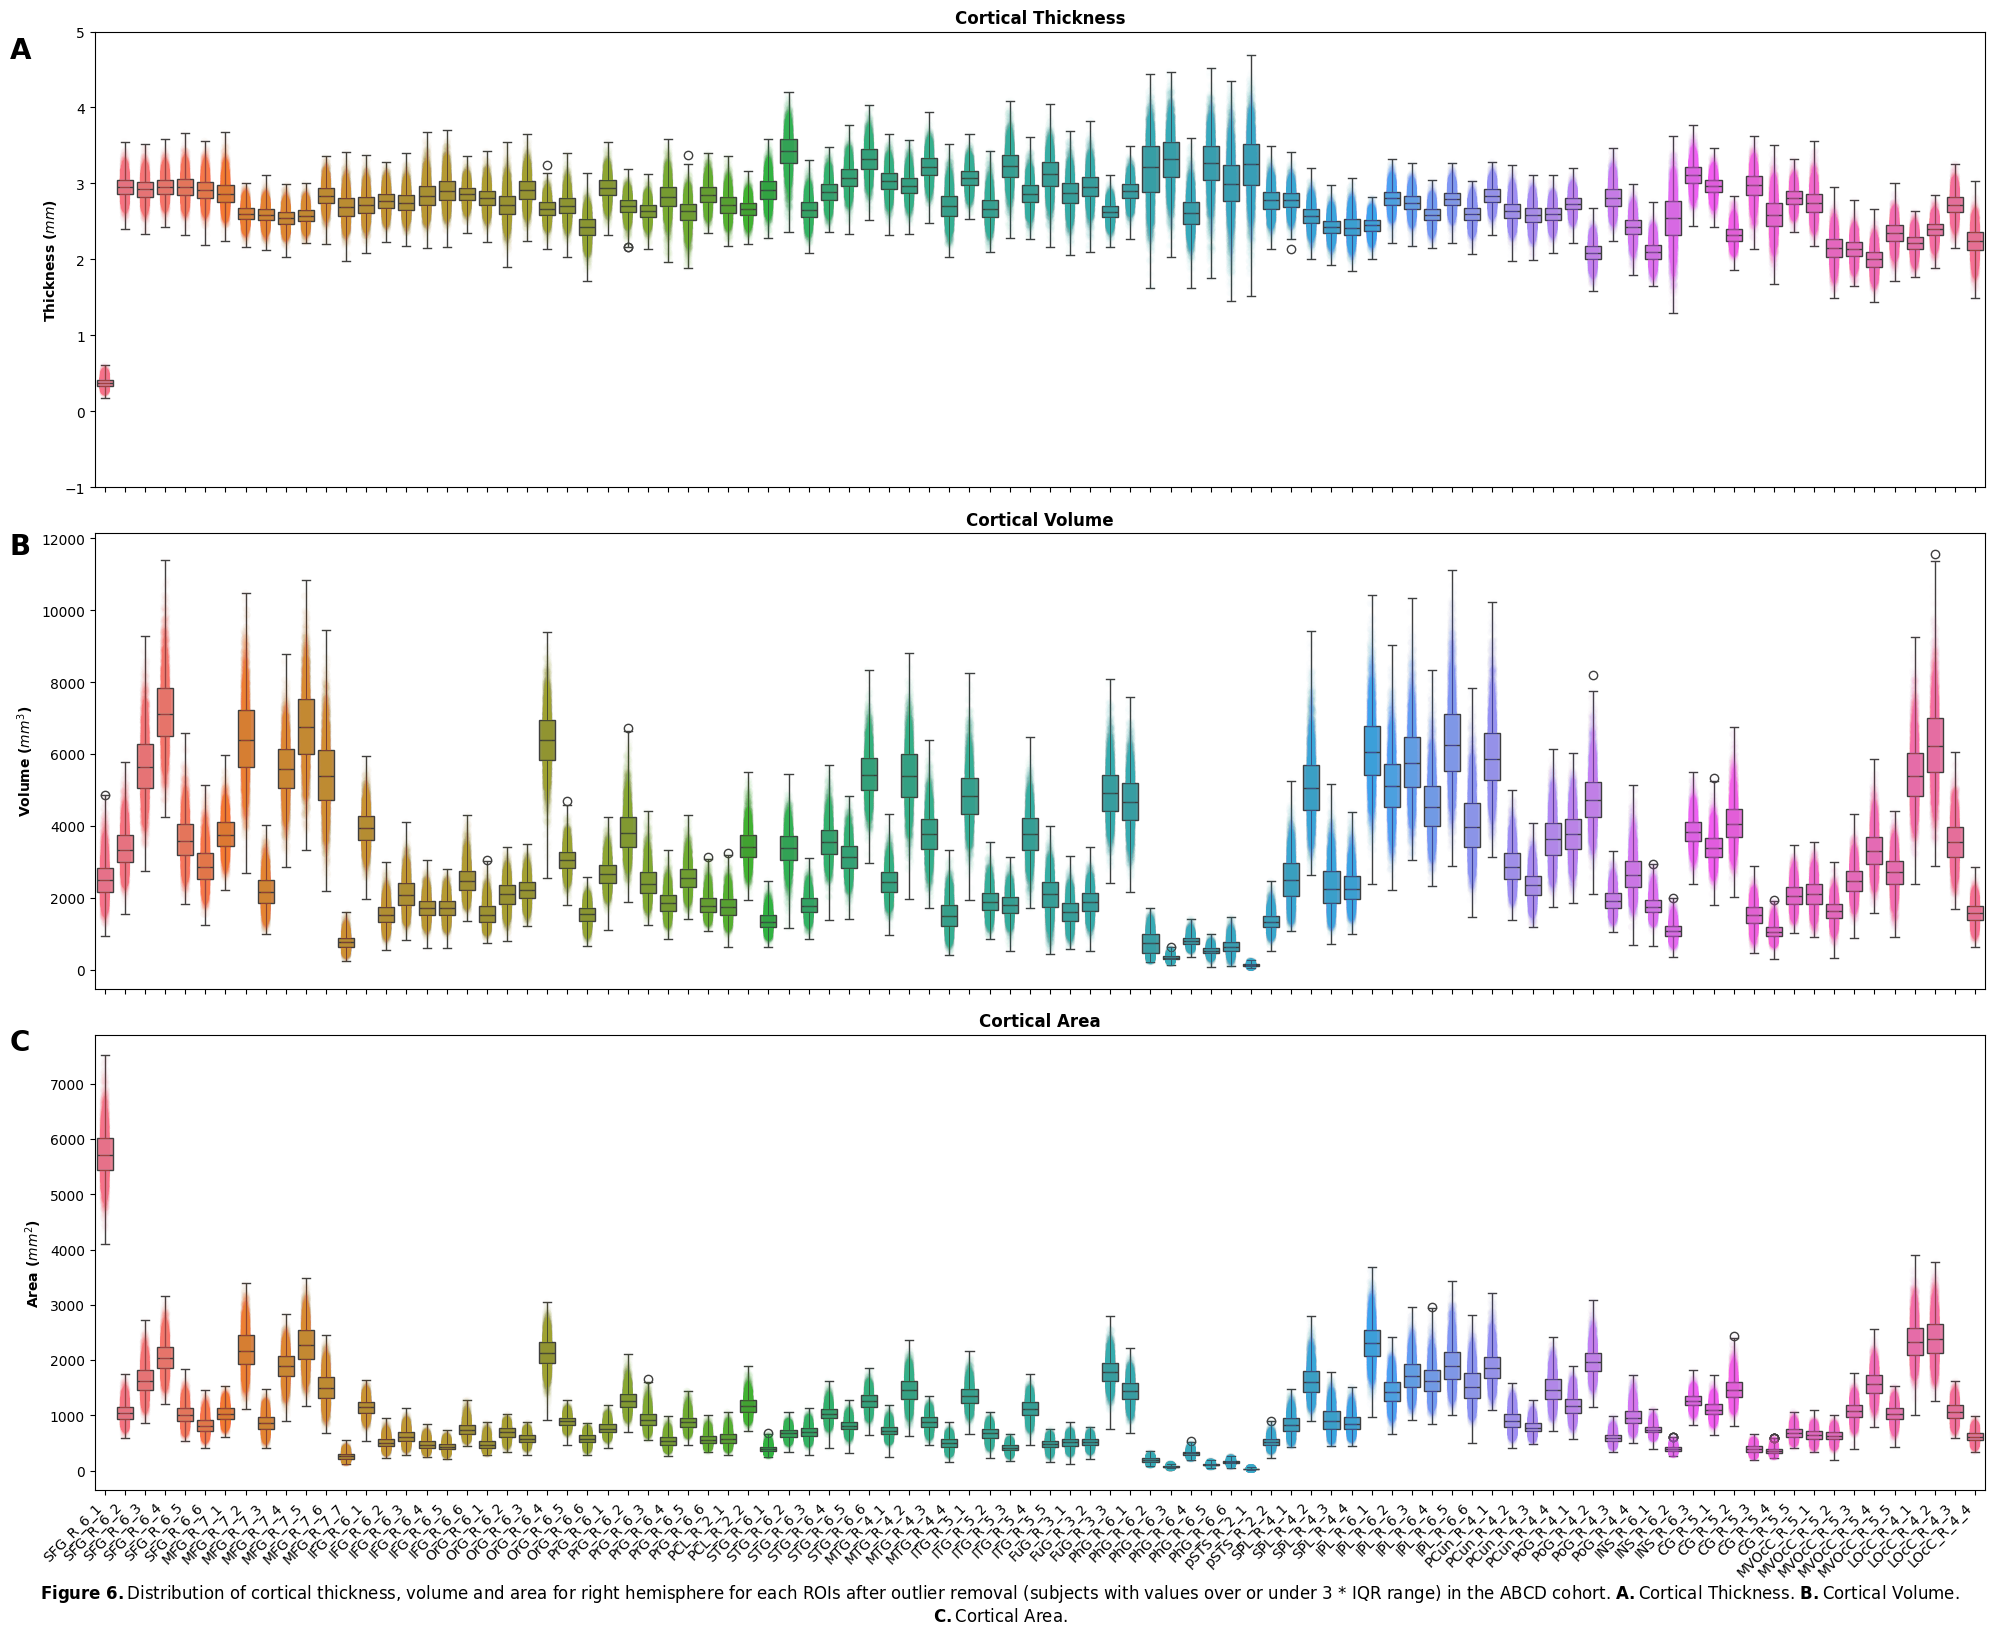

In [60]:
# Plotting the distribution of thickness, volume and area for right hemisphere using a boxplot after QC.

fig, ax = plt.subplots(3, 1, figsize=(20, 16))

# Thickness.
thicknessbox = sns.boxplot(data=thickness_df_QCed.iloc[:, 1:], ax=ax[0], whis=3)
sns.stripplot(data=thickness_df_QCed.iloc[:, 1:], ax=ax[0], alpha=0.01, palette="husl")
ax[0].set_title("Cortical Thickness", fontsize=12, fontweight='bold')
ax[0].set_ylabel("Thickness ($mm$)", fontsize=10, fontweight='bold')
ax[0].figure.autofmt_xdate(rotation=45, ha='right')
ax[0].set_ylim(-1, 5)

# Volume.
volumebox = sns.boxplot(data=volume_df_QCed.iloc[:, 1:], ax=ax[1], whis=3)
sns.stripplot(data=volume_df_QCed.iloc[:, 1:], ax=ax[1], alpha=0.01, palette="husl")
ax[1].set_title("Cortical Volume", fontsize=12, fontweight='bold')
ax[1].set_ylabel("Volume ($mm^3$)", fontsize=10, fontweight='bold')
ax[1].figure.autofmt_xdate(rotation=45, ha='right')

# Area.
areabox = sns.boxplot(data=area_df_QCed.iloc[:, 1:], ax=ax[2], whis=3)
sns.stripplot(data=area_df_QCed.iloc[:, 1:], ax=ax[2], alpha=0.01, palette="husl")
ax[2].set_title("Cortical Area", fontsize=12, fontweight='bold')
ax[2].set_ylabel("Area ($mm^2$)", fontsize=10, fontweight='bold')
ax[2].figure.autofmt_xdate(rotation=45, ha='right')

txt = r"$\bf{"+str("Figure\ 6.")+"}$" + "Distribution of cortical thickness, volume and area for right hemisphere for each ROIs after outlier removal (subjects with values over or under 3 * IQR range) in the ABCD cohort. " + \
        r"$\bf{"+"A."+"}$" + "Cortical Thickness. " + r"$\bf{"+"B."+"}$" + "Cortical Volume. " + r"$\bf{"+"C."+"}$" + "Cortical Area."

plt.figtext(0.5, -0.015, txt, wrap=True, horizontalalignment='center', fontsize=12)

# Add label to subplots.
plt.gcf().text(0.005, 0.96, "A", fontsize=20, fontweight='bold')
plt.gcf().text(0.005, 0.65, "B", fontsize=20, fontweight='bold')
plt.gcf().text(0.005, 0.34, "C", fontsize=20, fontweight='bold')

# Save the plot.
plt.tight_layout()
plt.savefig(f"{output_dir}/ABCD_cortical_thickness_volume_area_boxplot_right_hemi_QCed.png", dpi=900, bbox_inches='tight')

In [61]:
# Fetch all subjects that were excluded in both hemispheres and in subcortical data.
excluded_subs = excluded_subs_left.union(excluded_subs_right).union(ids)
print(f"Number of subjects excluded in both hemispheres and subcortical data: {len(excluded_subs)}")

Number of subjects excluded in both hemispheres and subcortical data: 778


#### **ABCD Cohort: QC and visualization of the streamline counts distribution and white matter (WM) coverage of the final filtered tractogram.**

The following cells will perform QC assessing the results of the dMRI processing. Since the obtained diffusion acquisition were already processed [[1]](#1), we assessed the streamline count and its distribution as well as the WM coverage of the final tractogram. To quantitatively measure the coverage, we computed the DICE scores between a density mask of the tractogram (obtained by computing a tract density image, then binarizing the image by replacing all values > 0 by 1.) and the WM mask used as tracking mask. As higher coverage is better and desired, we only removed subject with values lower than 3 * IQR. However, we removed subjects with values over or under 3 * IQR for the streamline count.

Since the raw streamline count or DICE score are not in a dataframe, we provide helper scripts for an easy conversion into a usable format for subsequent QC analysis. You can find those script in the `scripts/` folder of this repository.

**References** \
<a id=#1>[1]</a> Cetin-Karayumak, S., Zhang, F., Zurrin, R., Billah, T., Zekelman, L., Makris, N., Pieper, S., O’Donnell, L. J., & Rathi, Y. (2024). Harmonized diffusion MRI data and white matter measures from the Adolescent Brain Cognitive Development Study. Scientific Data, 11(1), 249. https://doi.org/10.1038/s41597-024-03058-w

In [62]:
# Convert DICE scores from JSON files to a dataframe.
!python {repository_dir}/scripts/extract_dice_from_json.py --in-directory {data_abcd}/DiceStats/RawJSONs \
    --out-file {data_abcd}/DiceStats/ABCD_dice_stats.tar.gz -v -f

2024-10-08 11:42:50 Anthonys-MacBook-Pro.local root[52824] INFO Reading JSON files from /Volumes/T7/ABCD/output//DiceStats/RawJSONs
2024-10-08 11:42:50 Anthonys-MacBook-Pro.local root[52824] INFO Processing JSON files...
Processing JSON files: 100%|███████████████| 9282/9282 [00:11<00:00, 782.26it/s]
2024-10-08 11:43:02 Anthonys-MacBook-Pro.local root[52824] INFO Saving dataframe to /Volumes/T7/ABCD/output//DiceStats/ABCD_dice_stats.tar.gz


In [88]:
# Converting streamline counts to a dataframe
os.makedirs(f"{data_abcd}/ConnectivityStatsDirs/SC", exist_ok=True)

# Moving arrays to a new directory.
for sub in os.listdir(f"{data_abcd}/ConnectivityStatsDirs/RawDirs"):
    shutil.copy(f"{data_abcd}/ConnectivityStatsDirs/RawDirs/{sub}/CONNECTOMICS-COMPUTE_CONNECTIVITY/{sub}__sc.npy", f"{data_abcd}/ConnectivityStatsDirs/SC/{sub}__sc.npy")

In [91]:
# ** This is a long running process, go grab a coffee! **

# Convert into a dataframe (using CLI scripts)
!python {repository_dir}/scripts/convert_matrices_to_df.py --in-directory {data_abcd}/ConnectivityStatsDirs/SC --out-file {data_abcd}/ConnectivityStatsDirs/ABCD_sc_raw.tar.gz -v -f

2024-10-08 13:39:06 Anthonys-MacBook-Pro.local root[90433] INFO Loading matrices...
2024-10-08 13:39:07 Anthonys-MacBook-Pro.local root[90433] INFO Setting up dataframe...
2024-10-08 13:39:07 Anthonys-MacBook-Pro.local root[90433] INFO Converting...
100%|██████████████████████████████████████| 9264/9264 [01:27<00:00, 105.62it/s]
2024-10-08 13:41:31 Anthonys-MacBook-Pro.local root[90433] INFO Writing to file...


In [92]:
# Computing the total streamline count for each subject, append it to a dataframe, and plot the distribution in a boxplot.
sc_df = pd.read_csv(f"{data_abcd}/ConnectivityStatsDirs/ABCD_sc_raw.tar.gz")

# Create total streamline count.
total_sc_count = pd.DataFrame()
total_sc_count["subjectkey"] = sc_df["subjectkey"]
total_sc_count["Total SC"] = sc_df.iloc[:, 1:].sum(axis=1)

# Fetch DICE scores.
dice_df = pd.read_csv(f"{data_abcd}/DiceStats/ABCD_dice_stats.tar.gz")

Number of subjects with total streamline count outside the 3 * IQR range: 8
Number of subjects with DICE score under the 3 * IQR range: 81


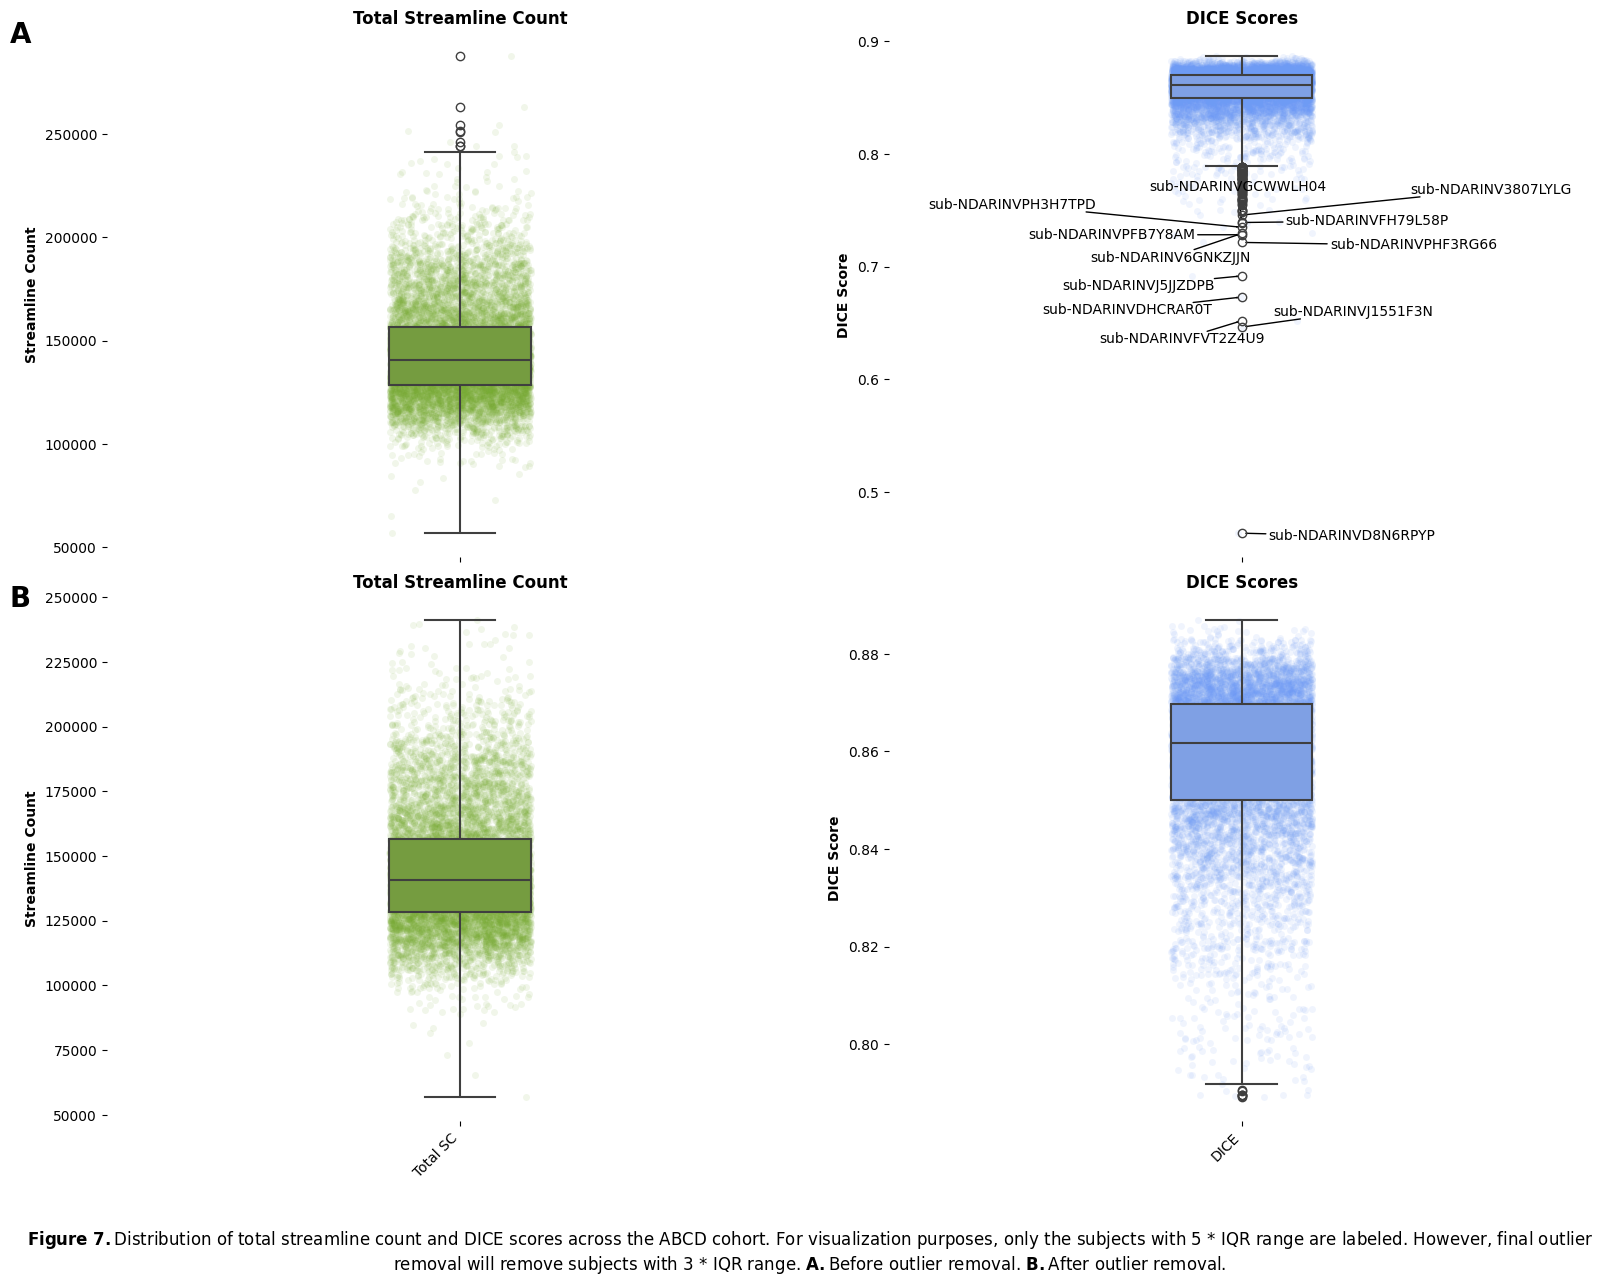

In [94]:
# Set color palette.
colors = sns.color_palette("husl", n_colors=10)

# Plot the distribution of total streamline count.
fig, ax = plt.subplots(2, 2, figsize=(16, 12))
sc_box = sns.boxplot(data=total_sc_count.iloc[:, 1:], ax=ax[0, 0], whis=3, color=colors[3],
                     width=0.2, linewidth=1.5, zorder=2)
sns.stripplot(data=total_sc_count.iloc[:, 1:], ax=ax[0, 0], alpha=0.1, color=colors[3],
              zorder=1)
ax[0, 0].set_title("Total Streamline Count", fontsize=12, fontweight='bold')
ax[0, 0].set_ylabel("Streamline Count", fontsize=10, fontweight='bold')
ax[0, 0].figure.autofmt_xdate(rotation=45, ha='right')
ax[0, 0].spines[["top", "right", "left", "bottom"]].set_visible(False)

# Add subject id to points outside the 3 * IQR range for the total streamline count data.
iqr = []
for roi in total_sc_count.columns[1:]:
    q75, q25 = np.percentile(total_sc_count[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (5 * intr_qr)
    qmin = q25 - (5 * intr_qr)
    iqr.append([qmin, qmax])

text = []
for i, roi in enumerate(total_sc_count.columns[1:]):
    for j, val in enumerate(total_sc_count[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            text.append(ax[0, 0].text(i, val, total_sc_count["subjectkey"][j], ha='center', va='center', fontsize=10, color='black'))
adjust_text(text, ax=ax[0, 0], iter_lim=1000, arrowprops=dict(arrowstyle='->', color='black'))

# Plot the distribution of DICE scores.
dice_box = sns.boxplot(data=dice_df.iloc[:, 1:], ax=ax[0, 1], whis=3, color=colors[7],
                       width=0.2, linewidth=1.5, zorder=2)
sns.stripplot(data=dice_df.iloc[:, 1:], ax=ax[0, 1], alpha=0.1, color=colors[7],
              zorder=1)
ax[0, 1].set_title("DICE Scores", fontsize=12, fontweight='bold')
ax[0, 1].set_ylabel("DICE Score", fontsize=10, fontweight='bold')
ax[0, 1].figure.autofmt_xdate(rotation=45, ha='right')
ax[0, 1].spines[["top", "right", "left", "bottom"]].set_visible(False)

# Add subject id to points outside the 3 * IQR range for the DICE score data.
iqr = []
for roi in dice_df.columns[1:]:
    q75, q25 = np.percentile(dice_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (5 * intr_qr)
    qmin = q25 - (5 * intr_qr)
    iqr.append([qmin, qmax])

text = []
for i, roi in enumerate(dice_df.columns[1:]):
    for j, val in enumerate(dice_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            text.append(ax[0, 1].text(i, val, dice_df["subjectkey"][j], ha='center', va='center', fontsize=10, color='black'))
adjust_text(text, ax=ax[0, 1], iter_lim=1000, arrowprops=dict(arrowstyle='->', color='black'))

# Removing subjects with total streamline count outside the 3 * IQR range.
iqr = []
for roi in total_sc_count.columns[1:]:
    q75, q25 = np.percentile(total_sc_count[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

# Removing subjects with total streamline count outside the 3 * IQR range.
sc_ids = []
for i, roi in enumerate(total_sc_count.columns[1:]):
    for j, val in enumerate(total_sc_count[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            sc_ids.append(total_sc_count["subjectkey"][j])

# Print the IDs of the subjects with total streamline count outside the 3 * IQR range.
print(f"Number of subjects with total streamline count outside the 3 * IQR range: {len(np.unique(sc_ids))}")

# Remove subjects with total streamline count outside the 3 * IQR range.
total_sc_count_QCed = total_sc_count[~total_sc_count["subjectkey"].isin(sc_ids)]
total_sc_count_QCed.reset_index(inplace=True, drop=True)

# Remove subjects with DICE score under the 3 * IQR range.
iqr = []
for roi in dice_df.columns[1:]:
    q75, q25 = np.percentile(dice_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

# Removing subjects with DICE score outside the 3 * IQR range.
dice_ids = []
for i, roi in enumerate(dice_df.columns[1:]):
    for j, val in enumerate(dice_df[roi]):
        if val < iqr[i][0]: # ONLY UNDER THE 3 * IQR RANGE.
            dice_ids.append(dice_df["subjectkey"][j])

# Print the IDs of the subjects with DICE score under the 3 * IQR range.
print(f"Number of subjects with DICE score under the 3 * IQR range: {len(np.unique(dice_ids))}")

# Remove subjects with DICE score under the 3 * IQR range.
dice_df_QCed = dice_df[~dice_df["subjectkey"].isin(dice_ids)]
dice_df_QCed.reset_index(inplace=True, drop=True)

# Add QC distribution to the plot.
sc_box_QCed = sns.boxplot(data=total_sc_count_QCed.iloc[:, 1:], ax=ax[1, 0], whis=3, color=colors[3],
                          width=0.2, linewidth=1.5, zorder=2)
sns.stripplot(data=total_sc_count_QCed.iloc[:, 1:], ax=ax[1, 0], alpha=0.1, color=colors[3],
              zorder=1)
ax[1, 0].set_title("Total Streamline Count", fontsize=12, fontweight='bold')
ax[1, 0].set_ylabel("Streamline Count", fontsize=10, fontweight='bold')
ax[1, 0].figure.autofmt_xdate(rotation=45, ha='right')
ax[1, 0].spines[["top", "right", "left", "bottom"]].set_visible(False)

# Add DICE QCed distribution to the plot.
dice_box_QCed = sns.boxplot(data=dice_df_QCed.iloc[:, 1:], ax=ax[1, 1], whis=3, color=colors[7],
                            width=0.2, linewidth=1.5, zorder=2)
sns.stripplot(data=dice_df_QCed.iloc[:, 1:], ax=ax[1, 1], alpha=0.1, color=colors[7],
              zorder=1)
ax[1, 1].set_title("DICE Scores", fontsize=12, fontweight='bold')
ax[1, 1].set_ylabel("DICE Score", fontsize=10, fontweight='bold')
ax[1, 1].figure.autofmt_xdate(rotation=45, ha='right')
ax[1, 1].spines[["top", "right", "left", "bottom"]].set_visible(False)

# Add labels for upper and lower rows.
plt.gcf().text(0, 0.96, "A", fontsize=20, fontweight='bold')
plt.gcf().text(0, 0.49, "B", fontsize=20, fontweight='bold')

txt = r"$\bf{"+str("Figure\ 7.")+"}$" + "Distribution of total streamline count and DICE scores across the ABCD cohort. " + \
        "For visualization purposes, only the subjects with 5 * IQR range are labeled. However, final outlier removal will remove subjects with 3 * IQR range. " + \
        r"$\bf{"+"A."+"}$" + "Before outlier removal. " + r"$\bf{"+"B."+"}$" + "After outlier removal."

plt.figtext(0.5, -0.06, txt, wrap=True, horizontalalignment='center', fontsize=12)

# Save the plot.
plt.tight_layout()
plt.savefig(f"{output_dir}/ABCD_total_sc_DICE_score.png", dpi=900, bbox_inches='tight')

In [95]:
# Saving the QCed total streamline count and DICE scores.
total_sc_count_QCed.to_csv(f"{output_dir}/ABCD_total_sc_QCed.csv", index=False, header=True)
dice_df_QCed.to_csv(f"{output_dir}/ABCD_dice_scores_QCed.csv", index=False, header=True)

# Merging the removed subids from thickness, volume, area, total streamline count and DICE scores.
excluded_subs = excluded_subs.union(sc_ids).union(dice_ids)
print(f"Total number of subjects excluded from all data: {len(excluded_subs)}")

# Save the excluded subjects.
with open(f"{output_dir}/ABCD_excluded_subjects.txt", "w") as f:
    for sub in excluded_subs:
        f.write(f"{sub}\n")

Total number of subjects excluded from all data: 839


#### **GESTE Cohort: QC and visualization of anatomical metrics of cortical and sub-cortical ROIs.**

The following cells will inspect results from the subcortical and cortical segmentations performed using the Brainnetome Child Atlas [[1]](#1). Specifically, volume, area and cortical thickness distributions will be plotted and IQR extracted. Subjects with values over or under 3 * IQR will be systematically removed and append into a text file. The initial segmentation was performed using FastSurfer [[2]](#2) and Brainnetome child atlas [[1]](#1) was moved into subject's space using surface-based registration. The following cells assume the subcortical and cortical data have been gathered within a csv-like file. If not, please see the [asegstats2table](https://surfer.nmr.mgh.harvard.edu/fswiki/asegstats2table) and/or [aparcstats2table](https://surfer.nmr.mgh.harvard.edu/fswiki/aparcstats2table) from the FreeSurfer documentation to learn how to extract the values from raw FastSurfer/FreeSurfer outputs.

**Some variables name are reused between cohorts to avoid high memory consumption. Therefore, if you want to run only specific cell, it would be a good practice to run all the previous cells for this specific cohort.**

**References** \
<a id=#1>[1]</a> Li, W., Fan, L., Shi, W., Lu, Y., Li, J., Luo, N., Wang, H., Chu, C., Ma, L., Song, M., Li, K., Cheng, L., Cao, L., & Jiang, T. (2023). Brainnetome atlas of preadolescent children based on anatomical connectivity profiles. Cerebral Cortex, 33(9), 5264–5275. https://doi.org/10.1093/cercor/bhac415 \
<a id=#2>[2]</a> Henschel, L., Conjeti, S., Estrada, S., Diers, K., Fischl, B., & Reuter, M. (2020). FastSurfer—A fast and accurate deep learning based neuroimaging pipeline. NeuroImage, 219, 117012. https://doi.org/10.1016/j.neuroimage.2020.117012

In [96]:
# Load subcortical data.
subcortical_df = load_df_in_any_format(f"{data_geste}/AnatomicalStats/GESTE_subcortical_volume.csv")

# Dropping brainstem, left and right cerebellum.
subcortical_df = subcortical_df.drop(["brainstem", "left_cerebellum_cortex", "right_cerebellum_cortex"], axis=1)

# Print the number of subjects and number of ROIs.
subs, rois = subcortical_df.shape
print(f"Number of subjects: {subs}")
print(f"Number of ROIs: {rois - 1}") # Excluding the subject ID column.

# Rename the subject ID column.
subcortical_df = subcortical_df.rename(columns={"Measure:volume": "subjectkey"})

# Filter out subjects with all 0 values for all ROIs and print their IDs.
zero_subs = subcortical_df[subcortical_df.iloc[:, 1:].sum(axis=1) == 0]
zero_subs_ids = zero_subs["subjectkey"].to_list()
print(f"Number of subjects with 0 values for all ROIs: {len(zero_subs_ids)}")
print(f"IDs of subjects with 0 values for all ROIs: {zero_subs_ids}")

# Drop subjects with all 0 values for all ROIs.
subcortical_df = subcortical_df[subcortical_df.iloc[:, 1:].sum(axis=1) != 0]
subcortical_df.reset_index(inplace=True, drop=True)

Number of subjects: 198
Number of ROIs: 36
Number of subjects with 0 values for all ROIs: 0
IDs of subjects with 0 values for all ROIs: []


/var/folders/23/p0fh1nrd473dtfz3cx_4g0j00000gn/T/ipykernel_92011/1606104303.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[0].set_xticklabels([roi.replace("_L", "") for roi in left_hemisphere])
/var/folders/23/p0fh1nrd473dtfz3cx_4g0j00000gn/T/ipykernel_92011/1606104303.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[1].set_xticklabels([roi.replace("_R", "") for roi in right_hemisphere])


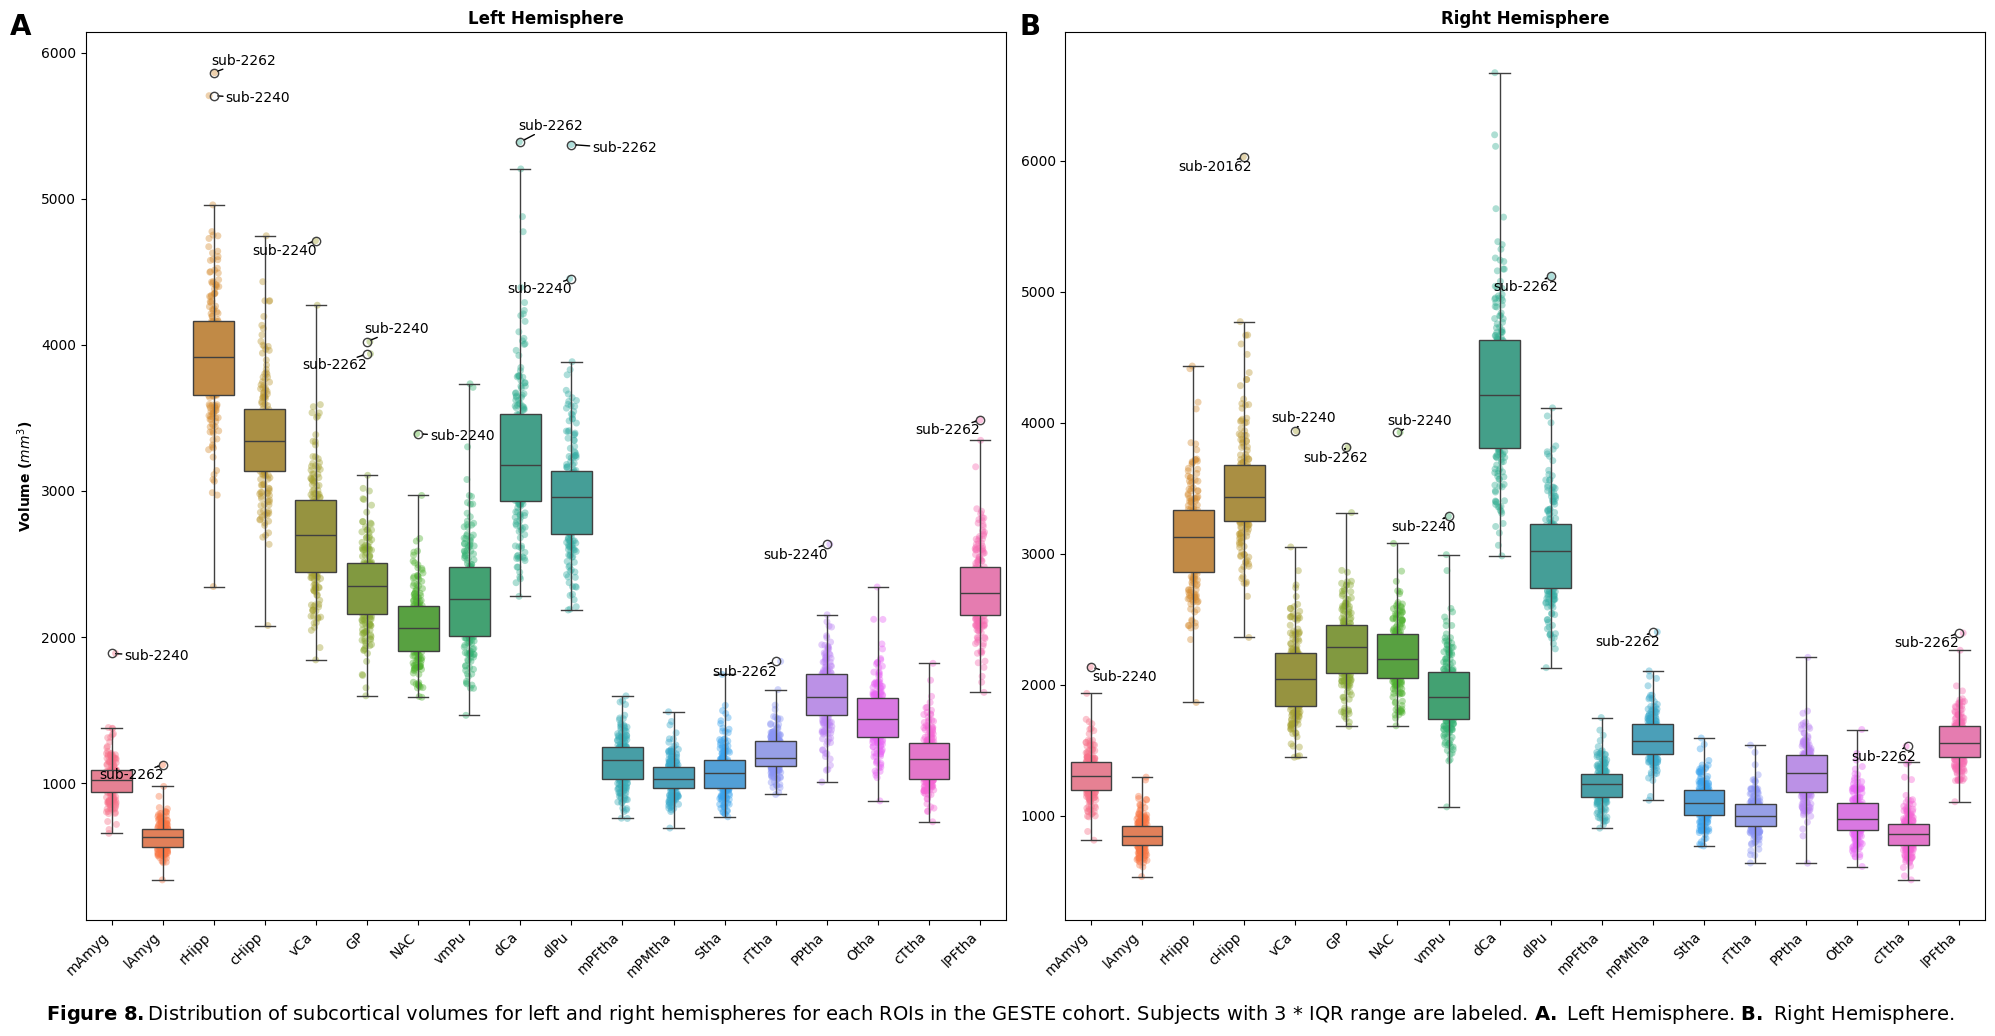

In [106]:
# Plotting the distribution of volumes for left and right hemispheres using a boxplot.
# Fetch left and right hemisphere ROIs.
left_hemisphere = [roi for roi in subcortical_df.columns if "L" in roi]
right_hemisphere = [roi for roi in subcortical_df.columns if "R" in roi]

# Plotting the distribution of volumes for left and right hemispheres using a boxplot.
fig, ax = plt.subplots(1, 2, figsize=(20, 10))

# Left hemisphere.
leftbox = sns.boxplot(data=subcortical_df[left_hemisphere], ax=ax[0], whis=3, zorder=2)
sns.stripplot(data=subcortical_df[left_hemisphere], ax=ax[0], alpha=0.4, palette="husl", zorder=1)
ax[0].set_title("Left Hemisphere", fontsize=12, fontweight='bold')
ax[0].set_ylabel("Volume ($mm^3$)", fontsize=10, fontweight='bold')
ax[0].set_xticklabels([roi.replace("_L", "") for roi in left_hemisphere])
ax[0].figure.autofmt_xdate(rotation=45, ha='right')

# Right hemisphere.
rightbox = sns.boxplot(data=subcortical_df[right_hemisphere], ax=ax[1], whis=3, zorder=2)
sns.stripplot(data=subcortical_df[right_hemisphere], ax=ax[1], alpha=0.4, palette="husl", zorder=1)
ax[1].set_title("Right Hemisphere", fontsize=12, fontweight='bold')
ax[1].set_xticklabels([roi.replace("_R", "") for roi in right_hemisphere])
ax[1].figure.autofmt_xdate(rotation=45, ha='right')

# Add subject id to points outside the 5 * IQR range for the left hemisphere.
iqr = []
for roi in left_hemisphere:
    q75, q25 = np.percentile(subcortical_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

text = []
for i, roi in enumerate(left_hemisphere):
    for j, val in enumerate(subcortical_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            text.append(ax[0].text(i, val, subcortical_df["subjectkey"][j], ha='center', va='center', fontsize=10, color='black'))
adjust_text(text, ax=ax[0], iter_lim=1000, arrowprops=dict(arrowstyle='->', color='black'))

# Add subject id to points outside the 5 * IQR range for the right hemisphere. (For visualization purposes)
iqr = []
for roi in right_hemisphere:
    q75, q25 = np.percentile(subcortical_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

text = []
for i, roi in enumerate(right_hemisphere):
    for j, val in enumerate(subcortical_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            text.append(ax[1].text(i, val, subcortical_df["subjectkey"][j], ha='center', va='center', fontsize=10, color='black'))
adjust_text(text, ax=ax[1], iter_lim=1000, arrowprops=dict(arrowstyle='->', color='black'))

txt = r"$\bf{"+str("Figure\ 8.")+"}$" + "Distribution of subcortical volumes for left and right hemispheres for each ROIs in the GESTE cohort. Subjects with 3 * IQR range are labeled. " + \
        r"$\bf{"+str("A.\ ")+"}$" + "Left Hemisphere. " + \
        r"$\bf{"+str("B.\ ")+"}$" + "Right Hemisphere."
plt.figtext(0.5, -0.025, txt, wrap=True, horizontalalignment='center', fontsize=14)

# Add label to subplots.
plt.gcf().text(0.005, 0.96, "A", fontsize=20, fontweight='bold')
plt.gcf().text(0.51, 0.96, "B", fontsize=20, fontweight='bold')

# Save the plot.
plt.tight_layout()
plt.savefig(f"{output_dir}/GESTE_subcortical_volumes_boxplot.png", dpi=600, bbox_inches='tight')

In [99]:
# Fetching the ID labels for the subjects with volumes outside the 3 * IQR range for all ROIs.
iqr = []
for roi in subcortical_df.columns[1:]:
    q75, q25 = np.percentile(subcortical_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

# Add subject id to points outside the 3 * IQR range for all ROIs.
ids = []
for i, roi in enumerate(subcortical_df.columns[1:]):
    for j, val in enumerate(subcortical_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            ids.append(subcortical_df["subjectkey"][j])

# Print the IDs of the subjects with volumes outside the 3 * IQR range for all ROIs.
print(f"Number of subjects with volumes outside the 3 * IQR range for all ROIs: {len(np.unique(ids))}")

# Remove subjects with volumes outside the 3 * IQR range for all ROIs.
subcortical_df_QCed = subcortical_df[~subcortical_df["subjectkey"].isin(ids)]
subcortical_df_QCed.reset_index(inplace=True, drop=True)
print(f"Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs: {subcortical_df_QCed.shape[0]}")

# Save the cleaned subcortical data.
subcortical_df_QCed.to_csv(f"{output_dir}/GESTE_subcortical_volumes_QCed.csv", index=False, header=True)

Number of subjects with volumes outside the 3 * IQR range for all ROIs: 3
Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs: 195


/var/folders/23/p0fh1nrd473dtfz3cx_4g0j00000gn/T/ipykernel_92011/2601532497.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[0].set_xticklabels([roi.replace("_L", "") for roi in left_hemisphere])
/var/folders/23/p0fh1nrd473dtfz3cx_4g0j00000gn/T/ipykernel_92011/2601532497.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[1].set_xticklabels([roi.replace("_R", "") for roi in right_hemisphere])


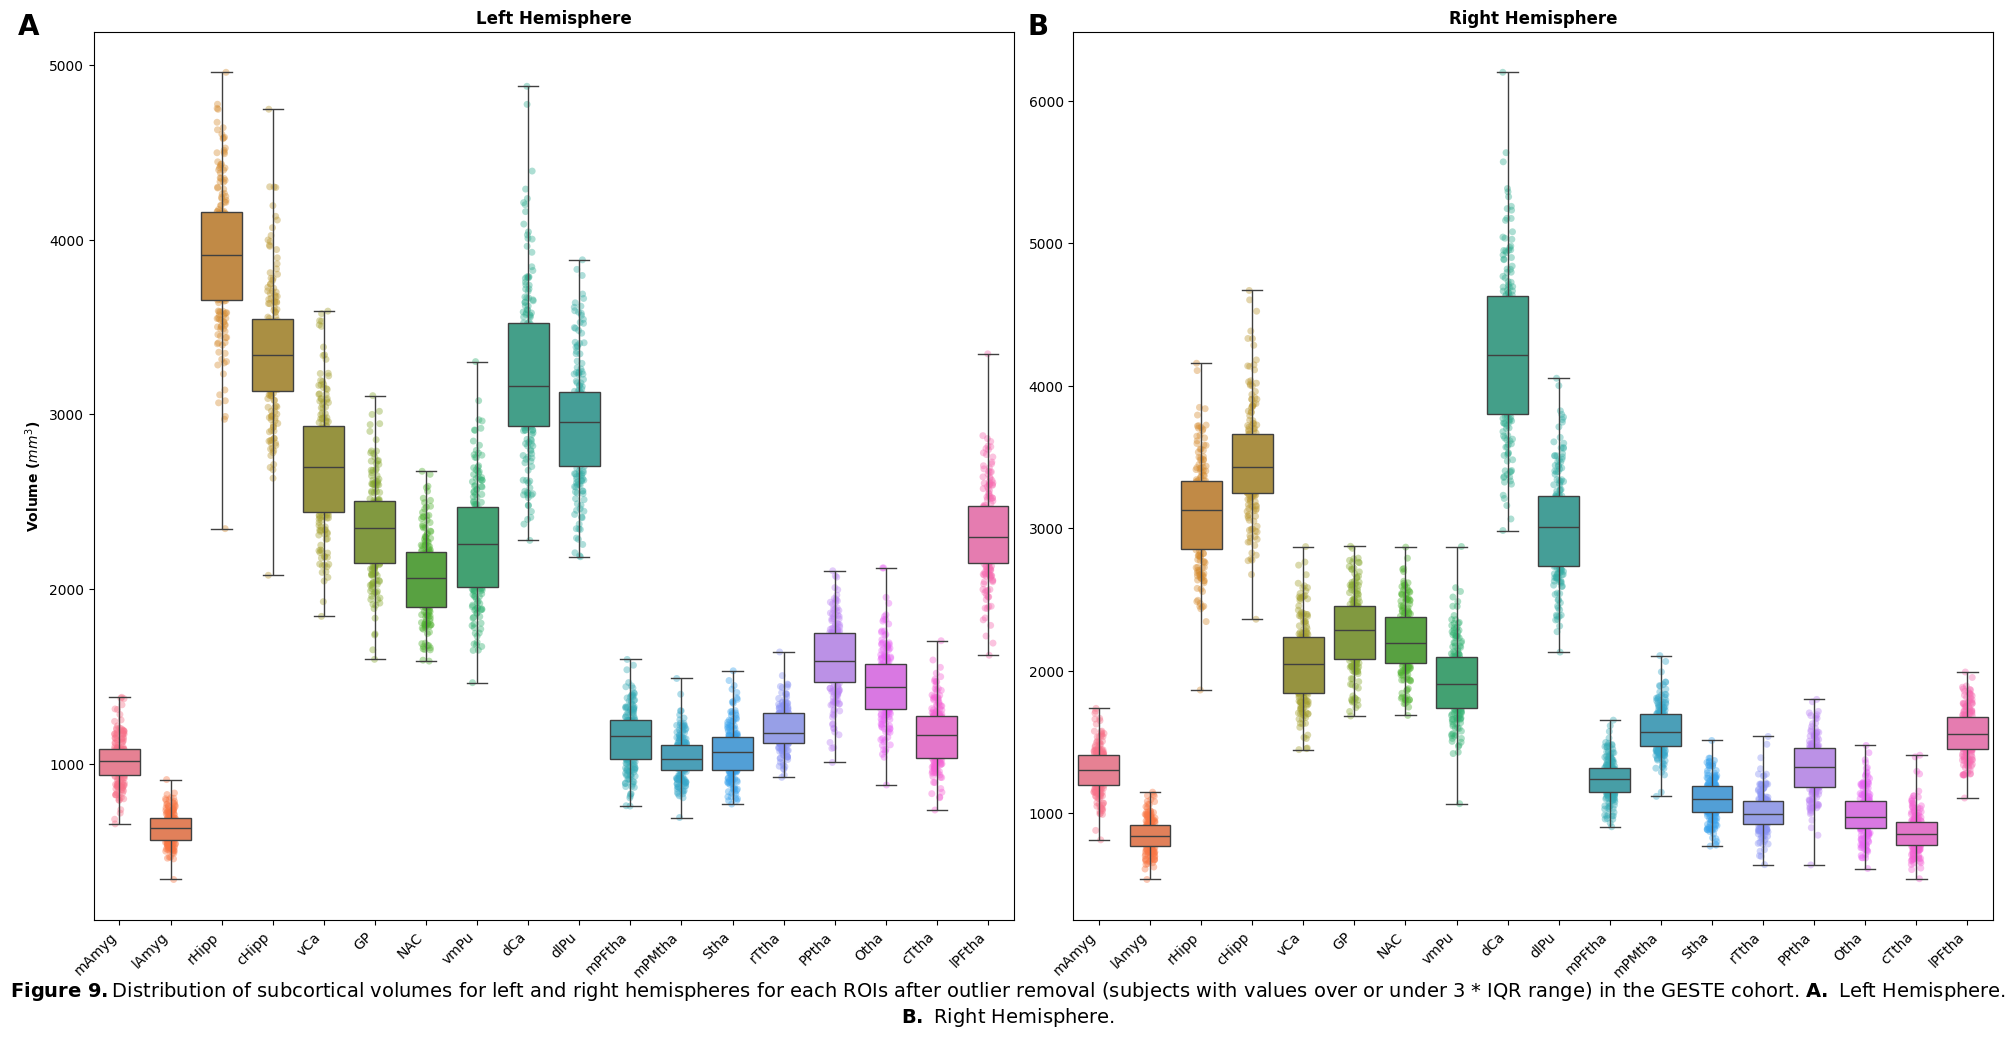

In [104]:
# Plotting the distribution of volumes for left and right hemispheres using a boxplot.

fig, ax = plt.subplots(1, 2, figsize=(20, 10))

# Left hemisphere.
leftbox = sns.boxplot(data=subcortical_df_QCed[left_hemisphere], ax=ax[0], whis=3, zorder=2)
sns.stripplot(data=subcortical_df_QCed[left_hemisphere], ax=ax[0], alpha=0.4, palette="husl", zorder=1)
ax[0].set_title("Left Hemisphere", fontsize=12, fontweight='bold')
ax[0].set_ylabel("Volume ($mm^3$)", fontsize=10, fontweight='bold')
ax[0].set_xticklabels([roi.replace("_L", "") for roi in left_hemisphere])
ax[0].figure.autofmt_xdate(rotation=45, ha='right')

# Right hemisphere.
rightbox = sns.boxplot(data=subcortical_df_QCed[right_hemisphere], ax=ax[1], whis=3, zorder=2)
sns.stripplot(data=subcortical_df_QCed[right_hemisphere], ax=ax[1], alpha=0.4, palette="husl", zorder=1)
ax[1].set_title("Right Hemisphere", fontsize=12, fontweight='bold')
ax[1].set_xticklabels([roi.replace("_R", "") for roi in right_hemisphere])
ax[1].figure.autofmt_xdate(rotation=45, ha='right')

txt = r"$\bf{"+str("Figure\ 9.")+"}$" + "Distribution of subcortical volumes for left and right hemispheres for each ROIs after outlier removal (subjects with values over or under 3 * IQR range) in the GESTE cohort. " + \
        r"$\bf{"+str("A.\ ")+"}$" + "Left Hemisphere. " + \
        r"$\bf{"+str("B.\ ")+"}$" + "Right Hemisphere."
plt.figtext(0.5, -0.025, txt, wrap=True, horizontalalignment='center', fontsize=14)

# Add label to subplots.
plt.gcf().text(0.005, 0.96, "A", fontsize=20, fontweight='bold')
plt.gcf().text(0.51, 0.96, "B", fontsize=20, fontweight='bold')

# Save the plot.
plt.tight_layout()
plt.savefig(f"{output_dir}/GESTE_subcortical_volumes_boxplot_QCed.png", dpi=600, bbox_inches='tight')

In [105]:
# Load cortical data.
thickness_df = load_df_in_any_format(f"{data_geste}/AnatomicalStats/GESTE_left_cortical_thickness.csv")
volume_df = load_df_in_any_format(f"{data_geste}/AnatomicalStats/GESTE_left_cortical_volume.csv")
area_df = load_df_in_any_format(f"{data_geste}/AnatomicalStats/GESTE_left_cortical_area.csv")

# Rename the subject ID column.
thickness_df = thickness_df.rename(columns={"lh.BN_child.thickness": "subjectkey"})
volume_df = volume_df.rename(columns={"lh.BN_child.volume": "subjectkey"})
area_df = area_df.rename(columns={"lh.BN_child.area": "subjectkey"})

# Dropping eTIV, cluster94, mean, brainsegnotvent.
thickness_df = thickness_df.drop(["eTIV", "lh_cluster94_thickness", "lh_MeanThickness_thickness", "BrainSegVolNotVent"], axis=1)
volume_df = volume_df.drop(["eTIV", "lh_cluster94_volume", "BrainSegVolNotVent"], axis=1)
area_df = area_df.drop(["eTIV", "lh_cluster94_area", "lh_WhiteSurfArea_area", "BrainSegVolNotVent"], axis=1)

# Filter out subjects with all 0 values for all ROIs and print their IDs.
zero_subs = thickness_df[thickness_df.iloc[:, 1:].sum(axis=1) == 0]
zero_subs_ids = zero_subs["subjectkey"].to_list()
print(f"Number of subjects with 0 values for all ROIs in thickness data: {len(zero_subs_ids)}")
print(f"IDs of subjects with 0 values for all ROIs in thickness data: {zero_subs_ids}")

zero_subs = volume_df[volume_df.iloc[:, 1:].sum(axis=1) == 0]
zero_subs_ids = zero_subs["subjectkey"].to_list()
print(f"Number of subjects with 0 values for all ROIs in volume data: {len(zero_subs_ids)}")
print(f"IDs of subjects with 0 values for all ROIs in volume data: {zero_subs_ids}")

zero_subs = area_df[area_df.iloc[:, 1:].sum(axis=1) == 0]
zero_subs_ids = zero_subs["subjectkey"].to_list()
print(f"Number of subjects with 0 values for all ROIs in area data: {len(zero_subs_ids)}")
print(f"IDs of subjects with 0 values for all ROIs in area data: {zero_subs_ids}")

# Drop subjects with all 0 values for all ROIs.
thickness_df = thickness_df[thickness_df.iloc[:, 1:].sum(axis=1) != 0]
thickness_df.reset_index(inplace=True, drop=True)

volume_df = volume_df[volume_df.iloc[:, 1:].sum(axis=1) != 0]
volume_df.reset_index(inplace=True, drop=True)

area_df = area_df[area_df.iloc[:, 1:].sum(axis=1) != 0]
area_df.reset_index(inplace=True, drop=True)

# Replace column names with clean ROI names.
rois = [roi.replace("lh_", "") for roi in thickness_df.columns[1:]]
rois = [roi.replace("_thickness", "") for roi in rois]

thickness_df.columns = ["subjectkey"] + rois
volume_df.columns = ["subjectkey"] + rois
area_df.columns = ["subjectkey"] + rois

# Print the number of subjects and number of ROIs.
subs, rois = thickness_df.shape
print(f"Number of subjects in thickness data: {subs}")
print(f"Number of ROIs in thickness data: {rois - 1}") # Excluding the subject ID column.

subs, rois = volume_df.shape
print(f"Number of subjects in volume data: {subs}")
print(f"Number of ROIs in volume data: {rois - 1}") # Excluding the subject ID column.

subs, rois = area_df.shape
print(f"Number of subjects in area data: {subs}")
print(f"Number of ROIs in area data: {rois - 1}") # Excluding the subject ID column.

Number of subjects with 0 values for all ROIs in thickness data: 0
IDs of subjects with 0 values for all ROIs in thickness data: []
Number of subjects with 0 values for all ROIs in volume data: 0
IDs of subjects with 0 values for all ROIs in volume data: []
Number of subjects with 0 values for all ROIs in area data: 0
IDs of subjects with 0 values for all ROIs in area data: []
Number of subjects in thickness data: 198
Number of ROIs in thickness data: 94
Number of subjects in volume data: 198
Number of ROIs in volume data: 94
Number of subjects in area data: 198
Number of ROIs in area data: 94


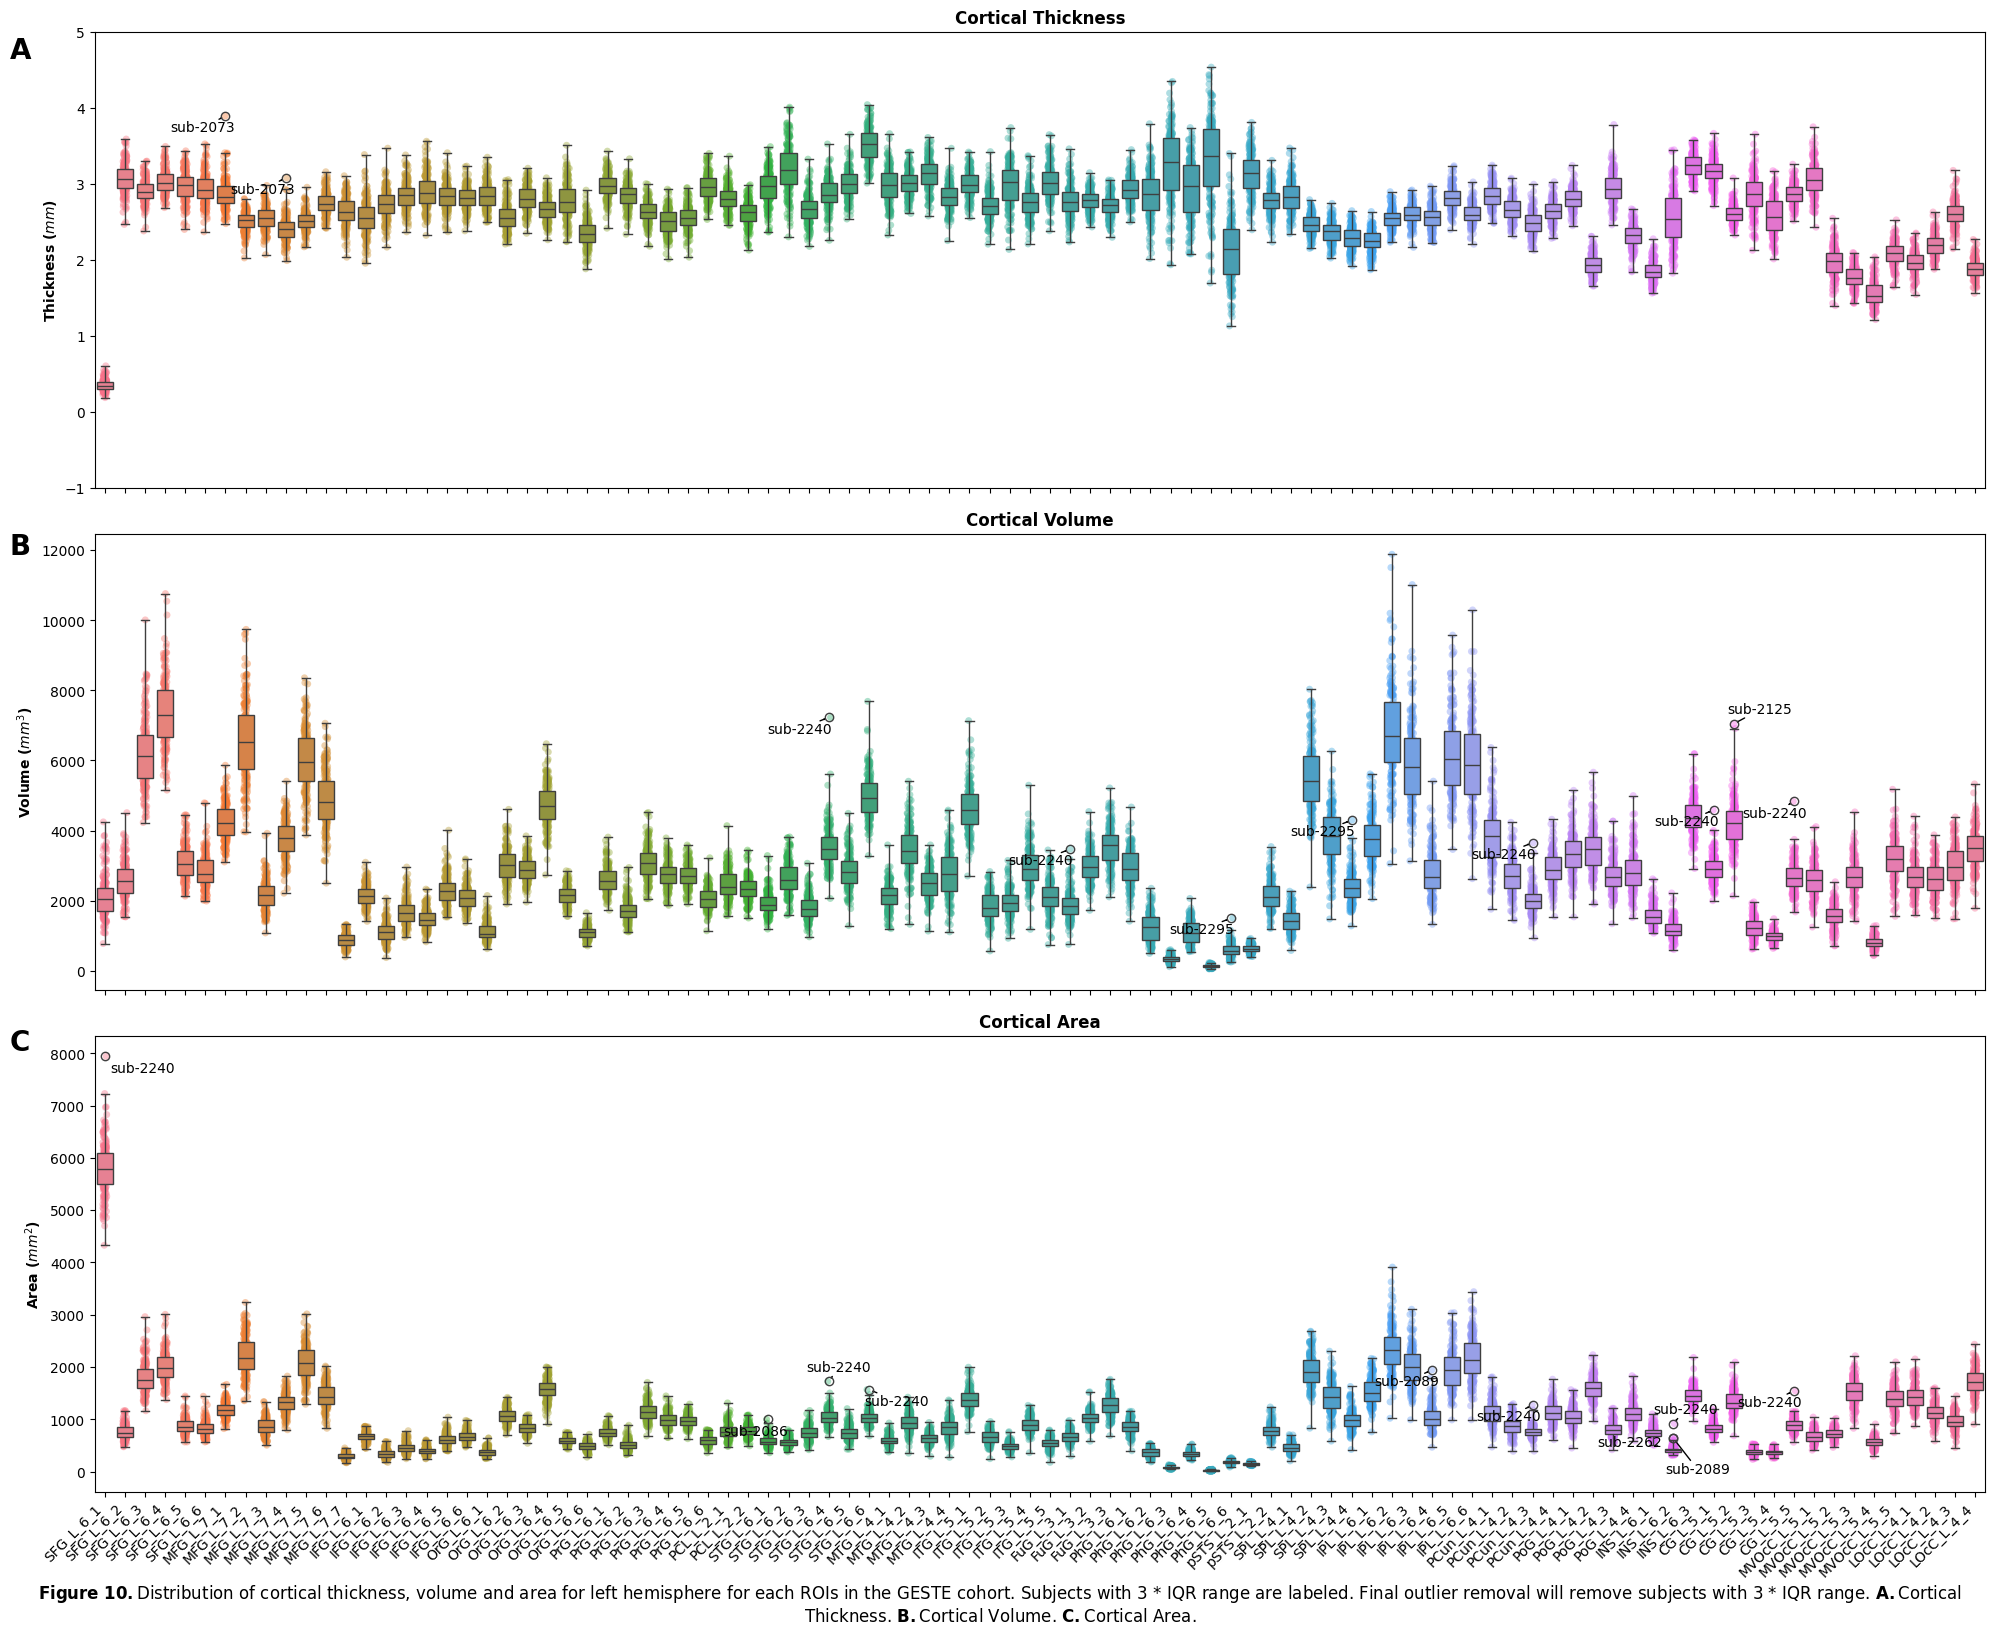

In [107]:
# Plotting the distribution of thickness, volume and area for left hemisphere using a boxplot.

fig, ax = plt.subplots(3, 1, figsize=(20, 16))

# Thickness.
thicknessbox = sns.boxplot(data=thickness_df.iloc[:, 1:], ax=ax[0], whis=3, zorder=2)
sns.stripplot(data=thickness_df.iloc[:, 1:], ax=ax[0], alpha=0.4, palette="husl", zorder=1)
ax[0].set_title("Cortical Thickness", fontsize=12, fontweight='bold')
ax[0].set_ylabel("Thickness ($mm$)", fontsize=10, fontweight='bold')
ax[0].figure.autofmt_xdate(rotation=45, ha='right')
ax[0].set_ylim(-1, 5)

# Add subject id to points outside the 5 * IQR range for the thickness data.
iqr = []
for roi in thickness_df.columns[1:]:
    q75, q25 = np.percentile(thickness_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

text = []
for i, roi in enumerate(thickness_df.columns[1:]):
    for j, val in enumerate(thickness_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            text.append(ax[0].text(i, val, thickness_df["subjectkey"][j], ha='center', va='center', fontsize=10, color='black'))
adjust_text(text, ax=ax[0], iter_lim=1000, arrowprops=dict(arrowstyle='->', color='black'))

# Volume.
volumebox = sns.boxplot(data=volume_df.iloc[:, 1:], ax=ax[1], whis=3, zorder=2)
sns.stripplot(data=volume_df.iloc[:, 1:], ax=ax[1], alpha=0.4, palette="husl", zorder=1)
ax[1].set_title("Cortical Volume", fontsize=12, fontweight='bold')
ax[1].set_ylabel("Volume ($mm^3$)", fontsize=10, fontweight='bold')
ax[1].figure.autofmt_xdate(rotation=45, ha='right')

# Add subject id to points outside the 5 * IQR range for the volume data.
iqr = []
for roi in volume_df.columns[1:]:
    q75, q25 = np.percentile(volume_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

text = []
for i, roi in enumerate(volume_df.columns[1:]):
    for j, val in enumerate(volume_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            text.append(ax[1].text(i, val, volume_df["subjectkey"][j], ha='center', va='center', fontsize=10, color='black'))
adjust_text(text, ax=ax[1], iter_lim=1000, arrowprops=dict(arrowstyle='->', color='black'))

# Area.
areabox = sns.boxplot(data=area_df.iloc[:, 1:], ax=ax[2], whis=3, zorder=2)
sns.stripplot(data=area_df.iloc[:, 1:], ax=ax[2], alpha=0.4, palette="husl", zorder=1)
ax[2].set_title("Cortical Area", fontsize=12, fontweight='bold')
ax[2].set_ylabel("Area ($mm^2$)", fontsize=10, fontweight='bold')
ax[2].figure.autofmt_xdate(rotation=45, ha='right')

# Add subject id to points outside the 5 * IQR range for the area data.
iqr = []
for roi in area_df.columns[1:]:
    q75, q25 = np.percentile(area_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

text = []
for i, roi in enumerate(area_df.columns[1:]):
    for j, val in enumerate(area_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            text.append(ax[2].text(i, val, area_df["subjectkey"][j], ha='center', va='center', fontsize=10, color='black'))
adjust_text(text, ax=ax[2], iter_lim=1000, arrowprops=dict(arrowstyle='->', color='black'))

txt = r"$\bf{"+str("Figure\ 10.")+"}$" + "Distribution of cortical thickness, volume and area for left hemisphere for each ROIs in the GESTE cohort. " + \
        "Subjects with 3 * IQR range are labeled. Final outlier removal will remove subjects with 3 * IQR range. " + \
        r"$\bf{"+"A."+"}$" + "Cortical Thickness. " + r"$\bf{"+"B."+"}$" + "Cortical Volume. " + r"$\bf{"+"C."+"}$" + "Cortical Area."

plt.figtext(0.5, -0.015, txt, wrap=True, horizontalalignment='center', fontsize=12)

# Add label to subplots.
plt.gcf().text(0.005, 0.96, "A", fontsize=20, fontweight='bold')
plt.gcf().text(0.005, 0.65, "B", fontsize=20, fontweight='bold')
plt.gcf().text(0.005, 0.34, "C", fontsize=20, fontweight='bold')

# Save the plot.
plt.tight_layout()
plt.savefig(f"{output_dir}/GESTE_cortical_thickness_volume_area_boxplot_left_hemi.png", dpi=900, bbox_inches='tight')


In [108]:
# Fetching the ID labels for the subjects with volumes outside the 3 * IQR range for all ROIs.
iqr = []
for roi in thickness_df.columns[1:]:
    q75, q25 = np.percentile(thickness_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

# Add subject id to points outside the 3 * IQR range for all ROIs.
thick_ids = []
for i, roi in enumerate(thickness_df.columns[1:]):
    for j, val in enumerate(thickness_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            thick_ids.append(thickness_df["subjectkey"][j])

# Print the IDs of the subjects with volumes outside the 3 * IQR range for all ROIs.
print(f"Number of subjects with volumes outside the 3 * IQR range for all ROIs in thickness data: {len(np.unique(thick_ids))}")

# Remove subjects with volumes outside the 3 * IQR range for all ROIs.
thickness_df_QCed = thickness_df[~thickness_df["subjectkey"].isin(thick_ids)]
thickness_df_QCed.reset_index(inplace=True, drop=True)
print(f"Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs in thickness data: {thickness_df_QCed.shape[0]}")

# Save the cleaned thickness data.
thickness_df_QCed.to_csv(f"{output_dir}/GESTE_left_cortical_thickness_QCed.csv", index=False, header=True)

# Fetching the ID labels for the subjects with volumes outside the 3 * IQR range for all ROIs.  
iqr = []
for roi in volume_df.columns[1:]:
    q75, q25 = np.percentile(volume_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

# Add subject id to points outside the 3 * IQR range for all ROIs.
vol_ids = []
for i, roi in enumerate(volume_df.columns[1:]):
    for j, val in enumerate(volume_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            vol_ids.append(volume_df["subjectkey"][j])

# Print the IDs of the subjects with volumes outside the 3 * IQR range for all ROIs.
print(f"Number of subjects with volumes outside the 3 * IQR range for all ROIs in volume data: {len(np.unique(vol_ids))}")

# Remove subjects with volumes outside the 3 * IQR range for all ROIs.
volume_df_QCed = volume_df[~volume_df["subjectkey"].isin(vol_ids)]
volume_df_QCed.reset_index(inplace=True, drop=True)
print(f"Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs in volume data: {volume_df_QCed.shape[0]}")

# Save the cleaned volume data.
volume_df_QCed.to_csv(f"{output_dir}/GESTE_left_cortical_volume_QCed.csv", index=False, header=True)

# Fetching the ID labels for the subjects with volumes outside the 3 * IQR range for all ROIs.
iqr = []
for roi in area_df.columns[1:]:
    q75, q25 = np.percentile(area_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

# Add subject id to points outside the 3 * IQR range for all ROIs.
area_ids = []
for i, roi in enumerate(area_df.columns[1:]):
    for j, val in enumerate(area_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            area_ids.append(area_df["subjectkey"][j])

# Print the IDs of the subjects with volumes outside the 3 * IQR range for all ROIs.
print(f"Number of subjects with volumes outside the 3 * IQR range for all ROIs in area data: {len(np.unique(area_ids))}")

# Remove subjects with volumes outside the 3 * IQR range for all ROIs.
area_df_QCed = area_df[~area_df["subjectkey"].isin(area_ids)]
area_df_QCed.reset_index(inplace=True, drop=True)
print(f"Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs in area data: {area_df_QCed.shape[0]}")

# Save the cleaned area data.
area_df_QCed.to_csv(f"{output_dir}/GESTE_left_cortical_area_QCed.csv", index=False, header=True)

# Looking at similarities between the excluded subjects in thickness, volume and area data.
excluded_subs_left = set(thick_ids).union(set(vol_ids)).union(set(area_ids))
print(f"Number of subjects excluded in thickness, volume and area data: {len(excluded_subs_left)}")


Number of subjects with volumes outside the 3 * IQR range for all ROIs in thickness data: 1
Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs in thickness data: 197
Number of subjects with volumes outside the 3 * IQR range for all ROIs in volume data: 3
Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs in volume data: 195
Number of subjects with volumes outside the 3 * IQR range for all ROIs in area data: 4
Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs in area data: 194
Number of subjects excluded in thickness, volume and area data: 7


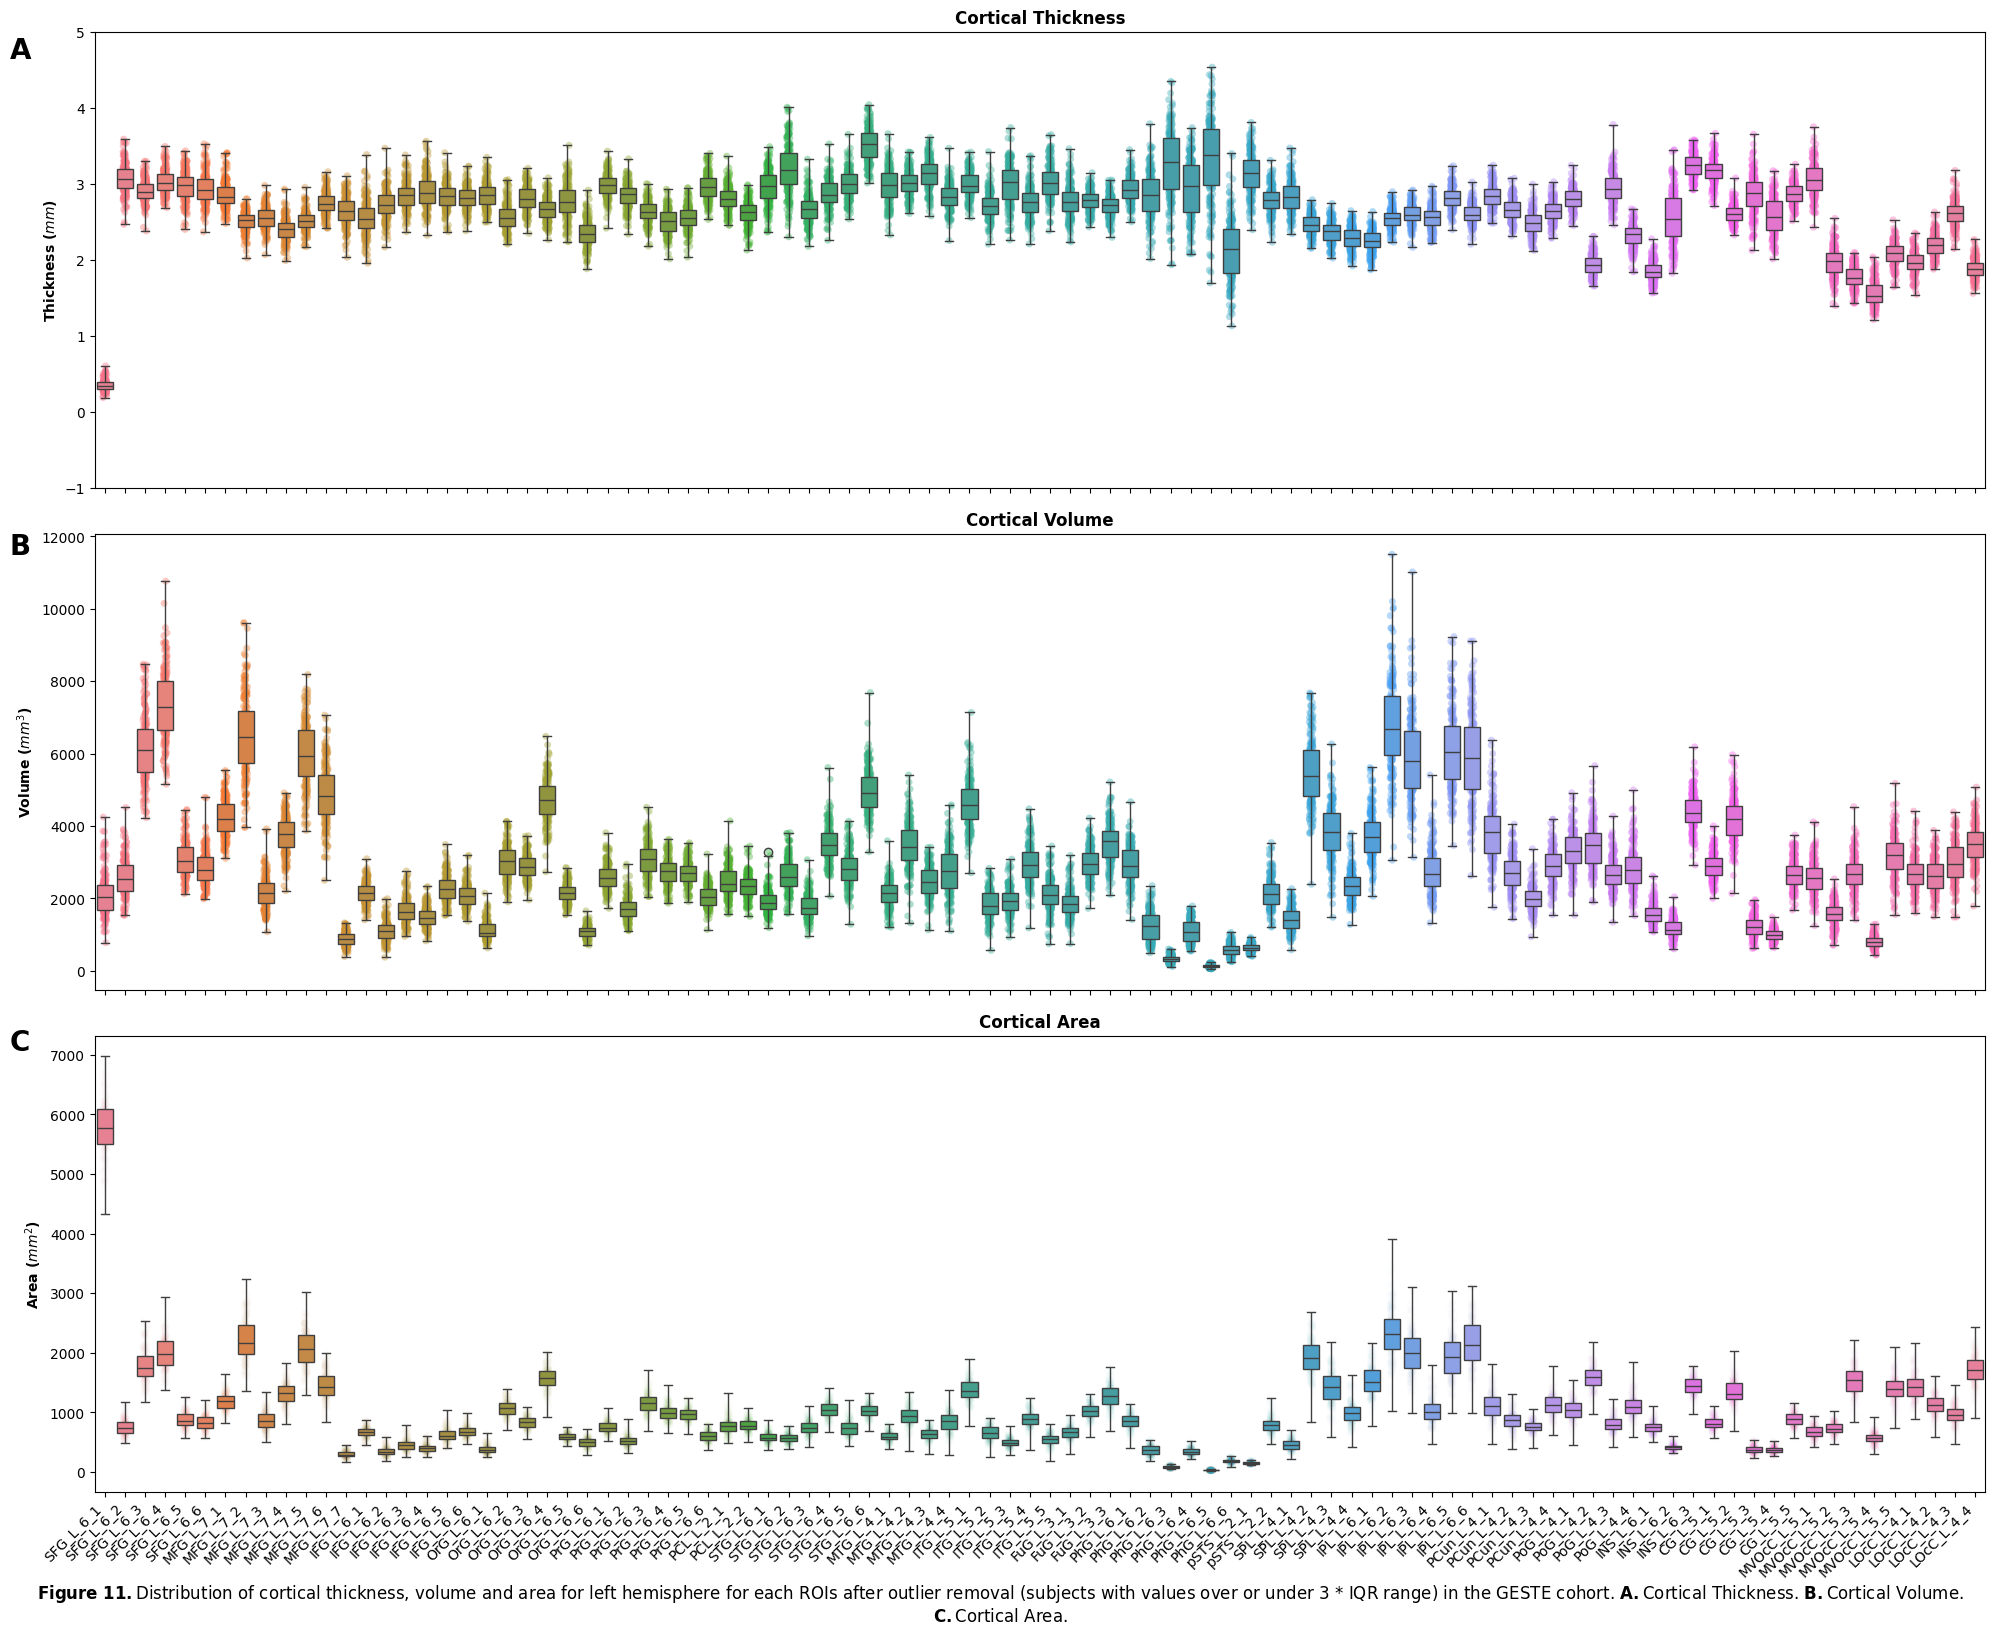

In [109]:
# Plotting the distribution of thickness, volume and area for left hemisphere using a boxplot after QC.

fig, ax = plt.subplots(3, 1, figsize=(20, 16))

# Thickness.
thicknessbox = sns.boxplot(data=thickness_df_QCed.iloc[:, 1:], ax=ax[0], whis=3, zorder=2)
sns.stripplot(data=thickness_df_QCed.iloc[:, 1:], ax=ax[0], alpha=0.4, palette="husl", zorder=1)
ax[0].set_title("Cortical Thickness", fontsize=12, fontweight='bold')
ax[0].set_ylabel("Thickness ($mm$)", fontsize=10, fontweight='bold')
ax[0].figure.autofmt_xdate(rotation=45, ha='right')
ax[0].set_ylim(-1, 5)

# Volume.
volumebox = sns.boxplot(data=volume_df_QCed.iloc[:, 1:], ax=ax[1], whis=3, zorder=2)
sns.stripplot(data=volume_df_QCed.iloc[:, 1:], ax=ax[1], alpha=0.4, palette="husl", zorder=1)
ax[1].set_title("Cortical Volume", fontsize=12, fontweight='bold')
ax[1].set_ylabel("Volume ($mm^3$)", fontsize=10, fontweight='bold')
ax[1].figure.autofmt_xdate(rotation=45, ha='right')

# Area.
areabox = sns.boxplot(data=area_df_QCed.iloc[:, 1:], ax=ax[2], whis=3, zorder=2)
sns.stripplot(data=area_df_QCed.iloc[:, 1:], ax=ax[2], alpha=0.01, palette="husl", zorder=1)
ax[2].set_title("Cortical Area", fontsize=12, fontweight='bold')
ax[2].set_ylabel("Area ($mm^2$)", fontsize=10, fontweight='bold')
ax[2].figure.autofmt_xdate(rotation=45, ha='right')

txt = r"$\bf{"+str("Figure\ 11.")+"}$" + "Distribution of cortical thickness, volume and area for left hemisphere for each ROIs after outlier removal (subjects with values over or under 3 * IQR range) in the GESTE cohort. " + \
        r"$\bf{"+"A."+"}$" + "Cortical Thickness. " + r"$\bf{"+"B."+"}$" + "Cortical Volume. " + r"$\bf{"+"C."+"}$" + "Cortical Area."

plt.figtext(0.5, -0.015, txt, wrap=True, horizontalalignment='center', fontsize=12)

# Add label to subplots.
plt.gcf().text(0.005, 0.96, "A", fontsize=20, fontweight='bold')
plt.gcf().text(0.005, 0.65, "B", fontsize=20, fontweight='bold')
plt.gcf().text(0.005, 0.34, "C", fontsize=20, fontweight='bold')

# Save the plot.
plt.tight_layout()
plt.savefig(f"{output_dir}/GESTE_cortical_thickness_volume_area_boxplot_left_hemi_QCed.png", dpi=900, bbox_inches='tight')

In [110]:
# Load cortical data for the right hemisphere.
thickness_df = load_df_in_any_format(f"{data_geste}/AnatomicalStats/GESTE_right_cortical_thickness.csv")
volume_df = load_df_in_any_format(f"{data_geste}/AnatomicalStats/GESTE_right_cortical_volume.csv")
area_df = load_df_in_any_format(f"{data_geste}/AnatomicalStats/GESTE_right_cortical_area.csv")

# Rename the subject ID column.
thickness_df = thickness_df.rename(columns={"rh.BN_child.thickness": "subjectkey"})
volume_df = volume_df.rename(columns={"rh.BN_child.volume": "subjectkey"})
area_df = area_df.rename(columns={"rh.BN_child.area": "subjectkey"})
thickness_df = thickness_df.drop(["eTIV", "rh_cluster94_thickness", "rh_MeanThickness_thickness", "BrainSegVolNotVent"], axis=1)
volume_df = volume_df.drop(["eTIV", "rh_cluster94_volume", "BrainSegVolNotVent"], axis=1)
area_df = area_df.drop(["eTIV", "rh_cluster94_area", "rh_WhiteSurfArea_area", "BrainSegVolNotVent"], axis=1)

# Filter out subjects with all 0 values for all ROIs and print their IDs.
zero_subs = thickness_df[thickness_df.iloc[:, 1:].sum(axis=1) == 0]
zero_subs_ids = zero_subs["subjectkey"].to_list()
print(f"Number of subjects with 0 values for all ROIs in thickness data: {len(zero_subs_ids)}")
print(f"IDs of subjects with 0 values for all ROIs in thickness data: {zero_subs_ids}")

zero_subs = volume_df[volume_df.iloc[:, 1:].sum(axis=1) == 0]
zero_subs_ids = zero_subs["subjectkey"].to_list()
print(f"Number of subjects with 0 values for all ROIs in volume data: {len(zero_subs_ids)}")
print(f"IDs of subjects with 0 values for all ROIs in volume data: {zero_subs_ids}")

zero_subs = area_df[area_df.iloc[:, 1:].sum(axis=1) == 0]
zero_subs_ids = zero_subs["subjectkey"].to_list()
print(f"Number of subjects with 0 values for all ROIs in area data: {len(zero_subs_ids)}")
print(f"IDs of subjects with 0 values for all ROIs in area data: {zero_subs_ids}")

# Drop subjects with all 0 values for all ROIs.
thickness_df = thickness_df[thickness_df.iloc[:, 1:].sum(axis=1) != 0]
thickness_df.reset_index(inplace=True, drop=True)

volume_df = volume_df[volume_df.iloc[:, 1:].sum(axis=1) != 0]
volume_df.reset_index(inplace=True, drop=True)

area_df = area_df[area_df.iloc[:, 1:].sum(axis=1) != 0]
area_df.reset_index(inplace=True, drop=True)

# Replace column names with clean ROI names.
rois = [roi.replace("rh_", "") for roi in thickness_df.columns[1:]]
rois = [roi.replace("_thickness", "") for roi in rois]

thickness_df.columns = ["subjectkey"] + rois
volume_df.columns = ["subjectkey"] + rois
area_df.columns = ["subjectkey"] + rois

# Print the number of subjects and number of ROIs.
subs, rois = thickness_df.shape
print(f"Number of subjects in thickness data: {subs}")
print(f"Number of ROIs in thickness data: {rois - 1}") # Excluding the subject ID column.

subs, rois = volume_df.shape
print(f"Number of subjects in volume data: {subs}")
print(f"Number of ROIs in volume data: {rois - 1}") # Excluding the subject ID column.

subs, rois = area_df.shape
print(f"Number of subjects in area data: {subs}")
print(f"Number of ROIs in area data: {rois - 1}") # Excluding the subject ID column.


Number of subjects with 0 values for all ROIs in thickness data: 0
IDs of subjects with 0 values for all ROIs in thickness data: []
Number of subjects with 0 values for all ROIs in volume data: 0
IDs of subjects with 0 values for all ROIs in volume data: []
Number of subjects with 0 values for all ROIs in area data: 0
IDs of subjects with 0 values for all ROIs in area data: []
Number of subjects in thickness data: 198
Number of ROIs in thickness data: 94
Number of subjects in volume data: 198
Number of ROIs in volume data: 94
Number of subjects in area data: 198
Number of ROIs in area data: 94


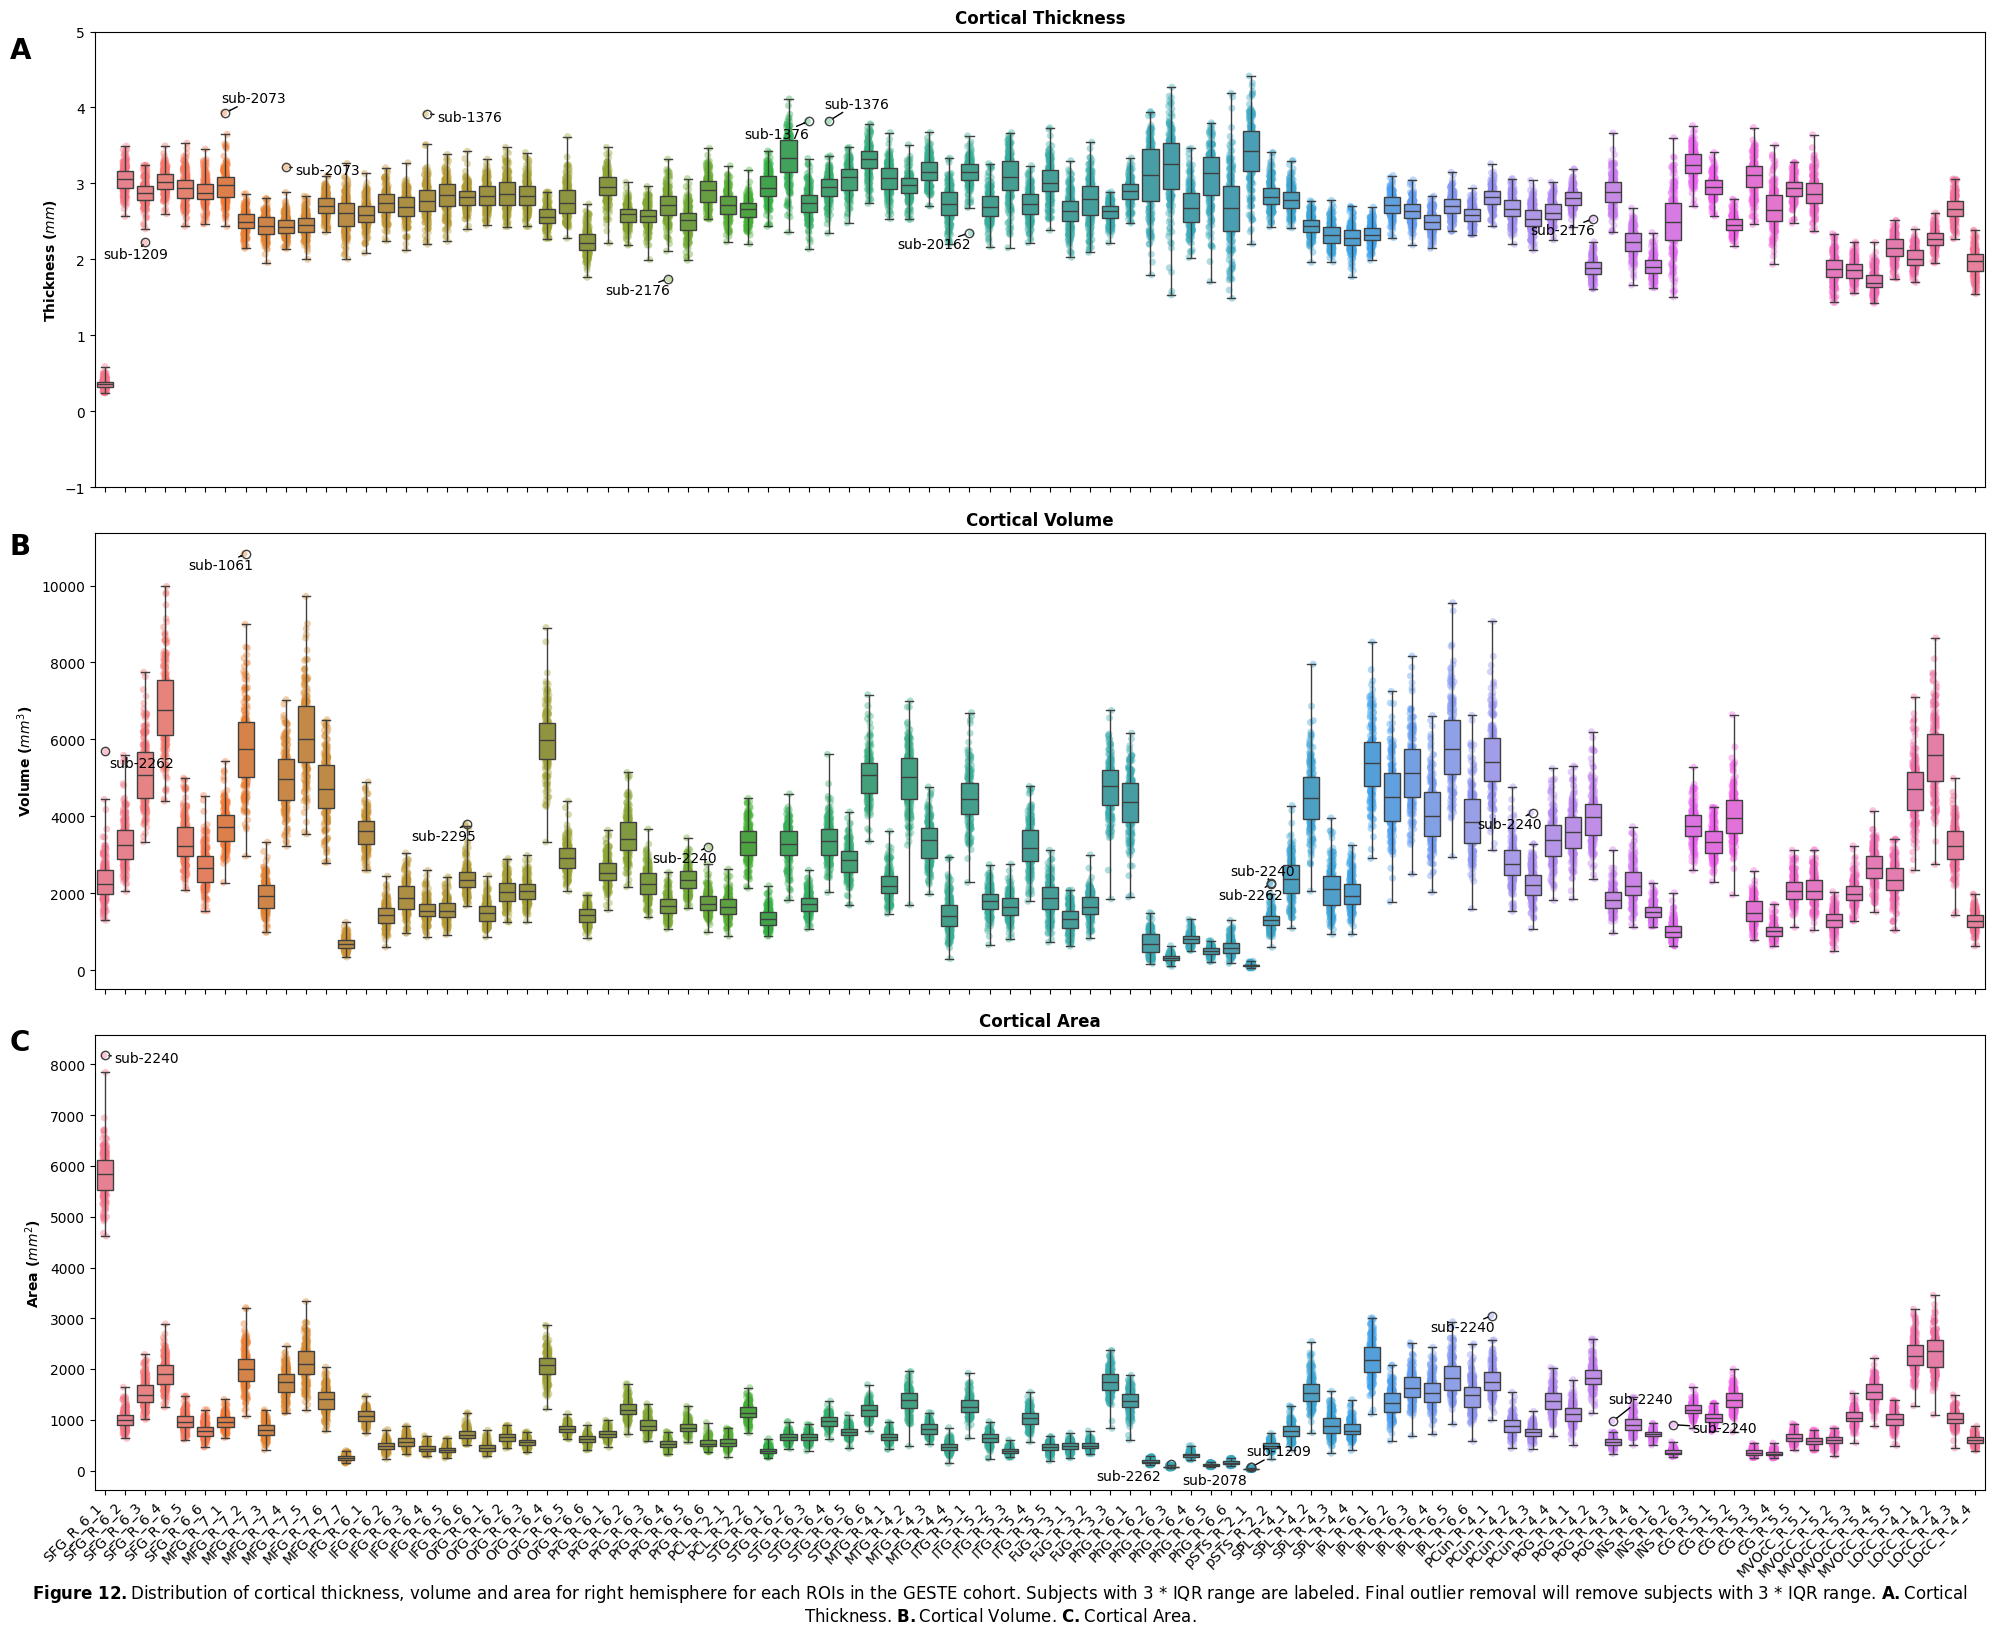

In [111]:
# Plotting the distribution of thickness, volume and area for right hemisphere using a boxplot.

fig, ax = plt.subplots(3, 1, figsize=(20, 16))

# Thickness.
thicknessbox = sns.boxplot(data=thickness_df.iloc[:, 1:], ax=ax[0], whis=3, zorder=2)
sns.stripplot(data=thickness_df.iloc[:, 1:], ax=ax[0], alpha=0.4, palette="husl", zorder=1)
ax[0].set_title("Cortical Thickness", fontsize=12, fontweight='bold')
ax[0].set_ylabel("Thickness ($mm$)", fontsize=10, fontweight='bold')
ax[0].figure.autofmt_xdate(rotation=45, ha='right')
ax[0].set_ylim(-1, 5)

# Add subject id to points outside the 5 * IQR range for the thickness data.
iqr = []
for roi in thickness_df.columns[1:]:
    q75, q25 = np.percentile(thickness_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

text = []
for i, roi in enumerate(thickness_df.columns[1:]):
    for j, val in enumerate(thickness_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            text.append(ax[0].text(i, val, thickness_df["subjectkey"][j], ha='center', va='center', fontsize=10, color='black'))
adjust_text(text, ax=ax[0], iter_lim=1000, arrowprops=dict(arrowstyle='->', color='black'))

# Volume.
volumebox = sns.boxplot(data=volume_df.iloc[:, 1:], ax=ax[1], whis=3, zorder=2)
sns.stripplot(data=volume_df.iloc[:, 1:], ax=ax[1], alpha=0.4, palette="husl", zorder=1)
ax[1].set_title("Cortical Volume", fontsize=12, fontweight='bold')
ax[1].set_ylabel("Volume ($mm^3$)", fontsize=10, fontweight='bold')
ax[1].figure.autofmt_xdate(rotation=45, ha='right')

# Add subject id to points outside the 5 * IQR range for the volume data.
iqr = []
for roi in volume_df.columns[1:]:
    q75, q25 = np.percentile(volume_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

text = []
for i, roi in enumerate(volume_df.columns[1:]):
    for j, val in enumerate(volume_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            text.append(ax[1].text(i, val, volume_df["subjectkey"][j], ha='center', va='center', fontsize=10, color='black'))
adjust_text(text, ax=ax[1], iter_lim=1000, arrowprops=dict(arrowstyle='->', color='black'))

# Area.
areabox = sns.boxplot(data=area_df.iloc[:, 1:], ax=ax[2], whis=3, zorder=2)
sns.stripplot(data=area_df.iloc[:, 1:], ax=ax[2], alpha=0.4, palette="husl", zorder=1)
ax[2].set_title("Cortical Area", fontsize=12, fontweight='bold')
ax[2].set_ylabel("Area ($mm^2$)", fontsize=10, fontweight='bold')
ax[2].figure.autofmt_xdate(rotation=45, ha='right')

# Add subject id to points outside the 5 * IQR range for the area data.
iqr = []
for roi in area_df.columns[1:]:
    q75, q25 = np.percentile(area_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

text = []
for i, roi in enumerate(area_df.columns[1:]):
    for j, val in enumerate(area_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            text.append(ax[2].text(i, val, area_df["subjectkey"][j], ha='center', va='center', fontsize=10, color='black'))
adjust_text(text, ax=ax[2], iter_lim=1000, arrowprops=dict(arrowstyle='->', color='black'))

txt = r"$\bf{"+str("Figure\ 12.")+"}$" + "Distribution of cortical thickness, volume and area for right hemisphere for each ROIs in the GESTE cohort. " + \
        "Subjects with 3 * IQR range are labeled. Final outlier removal will remove subjects with 3 * IQR range. " + \
        r"$\bf{"+"A."+"}$" + "Cortical Thickness. " + r"$\bf{"+"B."+"}$" + "Cortical Volume. " + r"$\bf{"+"C."+"}$" + "Cortical Area."

plt.figtext(0.5, -0.015, txt, wrap=True, horizontalalignment='center', fontsize=12)

# Add label to subplots.
plt.gcf().text(0.005, 0.96, "A", fontsize=20, fontweight='bold')
plt.gcf().text(0.005, 0.65, "B", fontsize=20, fontweight='bold')
plt.gcf().text(0.005, 0.34, "C", fontsize=20, fontweight='bold')

# Save the plot.
plt.tight_layout()
plt.savefig(f"{output_dir}/GESTE_cortical_thickness_volume_area_boxplot_right_hemi.png", dpi=900, bbox_inches='tight')

In [112]:
# Fetching the ID labels for the subjects with volumes outside the 3 * IQR range for all ROIs.
iqr = []
for roi in thickness_df.columns[1:]:
    q75, q25 = np.percentile(thickness_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

# Add subject id to points outside the 3 * IQR range for all ROIs.
thick_ids = []
for i, roi in enumerate(thickness_df.columns[1:]):
    for j, val in enumerate(thickness_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            thick_ids.append(thickness_df["subjectkey"][j])

# Print the IDs of the subjects with volumes outside the 3 * IQR range for all ROIs.
print(f"Number of subjects with volumes outside the 3 * IQR range for all ROIs in thickness data: {len(np.unique(thick_ids))}")

# Remove subjects with volumes outside the 3 * IQR range for all ROIs.
thickness_df_QCed = thickness_df[~thickness_df["subjectkey"].isin(thick_ids)]
thickness_df_QCed.reset_index(inplace=True, drop=True)
print(f"Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs in thickness data: {thickness_df_QCed.shape[0]}")

# Save the cleaned thickness data.
thickness_df_QCed.to_csv(f"{output_dir}/GESTE_right_cortical_thickness_QCed.csv", index=False, header=True)

# Fetching the ID labels for the subjects with volumes outside the 3 * IQR range for all ROIs.
iqr = []
for roi in volume_df.columns[1:]:
    q75, q25 = np.percentile(volume_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

# Add subject id to points outside the 3 * IQR range for all ROIs.
vol_ids = []
for i, roi in enumerate(volume_df.columns[1:]):
    for j, val in enumerate(volume_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            vol_ids.append(volume_df["subjectkey"][j])

# Print the IDs of the subjects with volumes outside the 3 * IQR range for all ROIs.
print(f"Number of subjects with volumes outside the 3 * IQR range for all ROIs in volume data: {len(np.unique(vol_ids))}")

# Remove subjects with volumes outside the 3 * IQR range for all ROIs.
volume_df_QCed = volume_df[~volume_df["subjectkey"].isin(vol_ids)]
volume_df_QCed.reset_index(inplace=True, drop=True)
print(f"Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs in volume data: {volume_df_QCed.shape[0]}")

# Save the cleaned volume data.
volume_df_QCed.to_csv(f"{output_dir}/GESTE_right_cortical_volume_QCed.csv", index=False, header=True)

# Fetching the ID labels for the subjects with volumes outside the 3 * IQR range for all ROIs.
iqr = []
for roi in area_df.columns[1:]:
    q75, q25 = np.percentile(area_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

# Add subject id to points outside the 3 * IQR range for all ROIs.
area_ids = []
for i, roi in enumerate(area_df.columns[1:]):
    for j, val in enumerate(area_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            area_ids.append(area_df["subjectkey"][j])

# Print the IDs of the subjects with volumes outside the 3 * IQR range for all ROIs.
print(f"Number of subjects with volumes outside the 3 * IQR range for all ROIs in area data: {len(np.unique(area_ids))}")

# Remove subjects with volumes outside the 3 * IQR range for all ROIs.
area_df_QCed = area_df[~area_df["subjectkey"].isin(area_ids)]
area_df_QCed.reset_index(inplace=True, drop=True)
print(f"Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs in area data: {area_df_QCed.shape[0]}")

# Save the cleaned area data.
area_df_QCed.to_csv(f"{output_dir}/GESTE_right_cortical_area_QCed.csv", index=False, header=True)

# Looking at similarities between the excluded subjects in thickness, volume and area data.
excluded_subs_right = set(thick_ids).union(set(vol_ids)).union(set(area_ids))
print(f"Number of subjects excluded in thickness, volume and area data: {len(excluded_subs_right)}")

Number of subjects with volumes outside the 3 * IQR range for all ROIs in thickness data: 5
Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs in thickness data: 193
Number of subjects with volumes outside the 3 * IQR range for all ROIs in volume data: 4
Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs in volume data: 194
Number of subjects with volumes outside the 3 * IQR range for all ROIs in area data: 4
Number of subjects after removing subjects with volumes outside the 3 * IQR range for all ROIs in area data: 194
Number of subjects excluded in thickness, volume and area data: 10


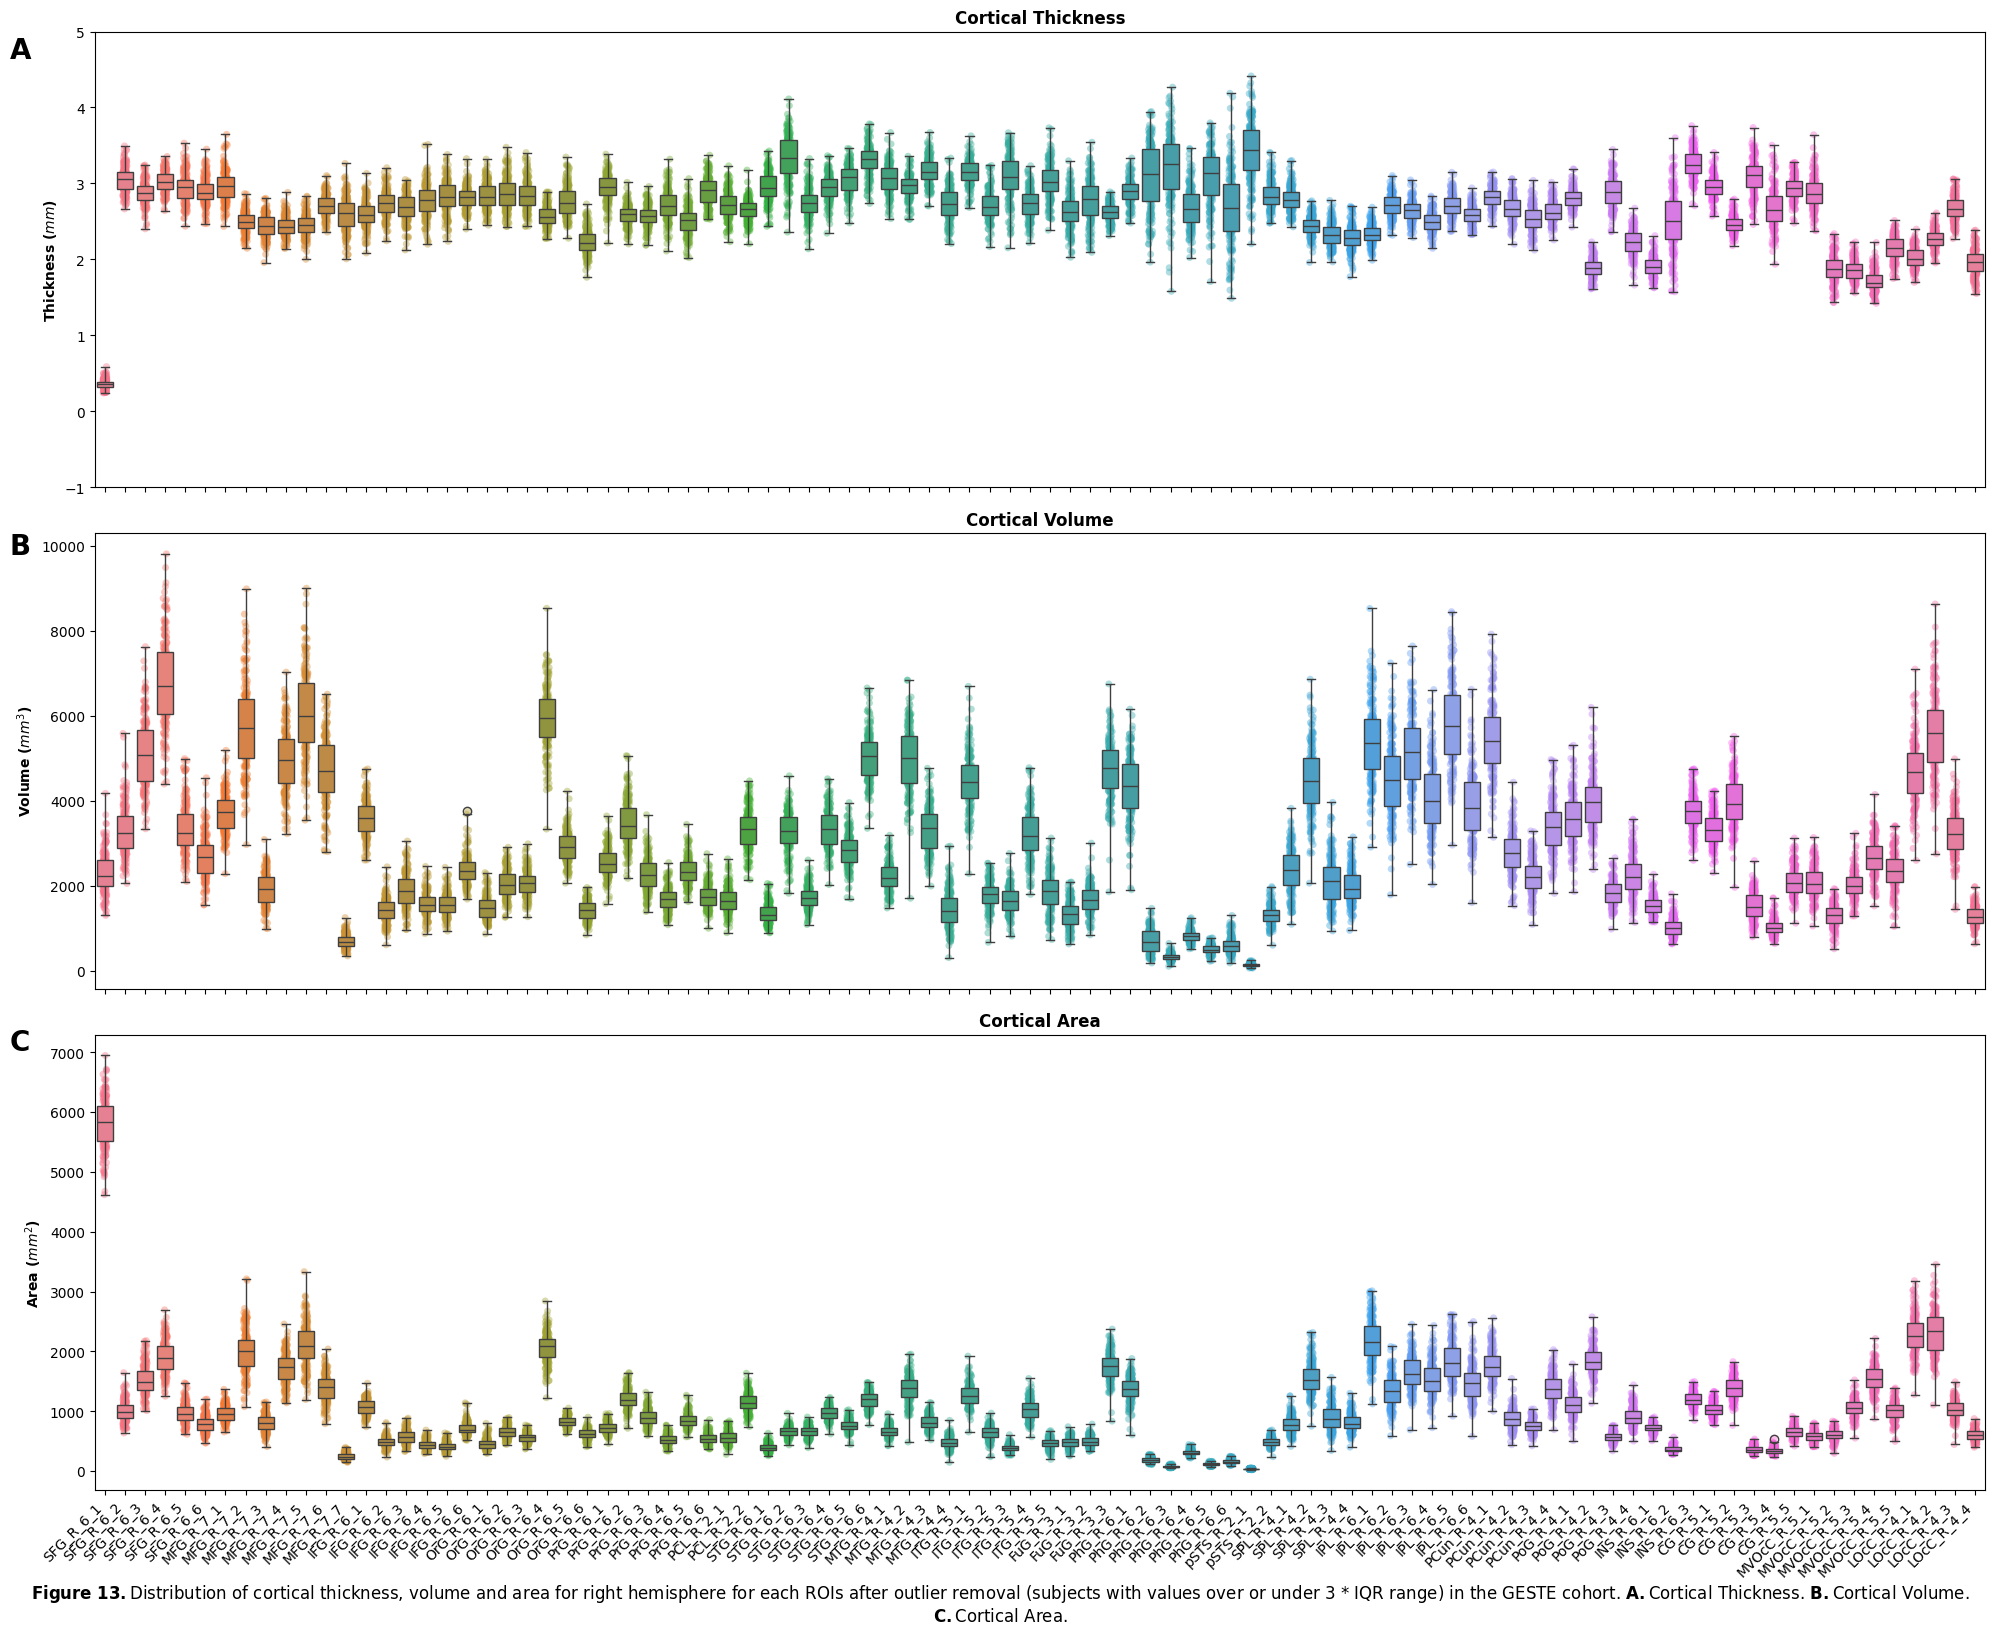

In [113]:
# Plotting the distribution of thickness, volume and area for right hemisphere using a boxplot after QC.

fig, ax = plt.subplots(3, 1, figsize=(20, 16))

# Thickness.
thicknessbox = sns.boxplot(data=thickness_df_QCed.iloc[:, 1:], ax=ax[0], whis=3, zorder=2)
sns.stripplot(data=thickness_df_QCed.iloc[:, 1:], ax=ax[0], alpha=0.4, palette="husl", zorder=1)
ax[0].set_title("Cortical Thickness", fontsize=12, fontweight='bold')
ax[0].set_ylabel("Thickness ($mm$)", fontsize=10, fontweight='bold')
ax[0].figure.autofmt_xdate(rotation=45, ha='right')
ax[0].set_ylim(-1, 5)

# Volume.
volumebox = sns.boxplot(data=volume_df_QCed.iloc[:, 1:], ax=ax[1], whis=3, zorder=2)
sns.stripplot(data=volume_df_QCed.iloc[:, 1:], ax=ax[1], alpha=0.4, palette="husl", zorder=1)
ax[1].set_title("Cortical Volume", fontsize=12, fontweight='bold')
ax[1].set_ylabel("Volume ($mm^3$)", fontsize=10, fontweight='bold')
ax[1].figure.autofmt_xdate(rotation=45, ha='right')

# Area.
areabox = sns.boxplot(data=area_df_QCed.iloc[:, 1:], ax=ax[2], whis=3, zorder=2)
sns.stripplot(data=area_df_QCed.iloc[:, 1:], ax=ax[2], alpha=0.4, palette="husl", zorder=1)
ax[2].set_title("Cortical Area", fontsize=12, fontweight='bold')
ax[2].set_ylabel("Area ($mm^2$)", fontsize=10, fontweight='bold')
ax[2].figure.autofmt_xdate(rotation=45, ha='right')

txt = r"$\bf{"+str("Figure\ 13.")+"}$" + "Distribution of cortical thickness, volume and area for right hemisphere for each ROIs after outlier removal (subjects with values over or under 3 * IQR range) in the GESTE cohort. " + \
        r"$\bf{"+"A."+"}$" + "Cortical Thickness. " + r"$\bf{"+"B."+"}$" + "Cortical Volume. " + r"$\bf{"+"C."+"}$" + "Cortical Area."

plt.figtext(0.5, -0.015, txt, wrap=True, horizontalalignment='center', fontsize=12)

# Add label to subplots.
plt.gcf().text(0.005, 0.96, "A", fontsize=20, fontweight='bold')
plt.gcf().text(0.005, 0.65, "B", fontsize=20, fontweight='bold')
plt.gcf().text(0.005, 0.34, "C", fontsize=20, fontweight='bold')

# Save the plot.
plt.tight_layout()
plt.savefig(f"{output_dir}/GESTE_cortical_thickness_volume_area_boxplot_right_hemi_QCed.png", dpi=900, bbox_inches='tight')

In [114]:
# Fetch all subjects that were excluded in both hemispheres and in subcortical data.
excluded_subs = excluded_subs_left.union(excluded_subs_right).union(ids)
print(f"Number of subjects excluded in both hemispheres and subcortical data: {len(excluded_subs)}")

Number of subjects excluded in both hemispheres and subcortical data: 13


#### **GESTE Cohort: QC and visualization of the streamline counts distribution and white matter (WM) coverage of the final filtered tractogram.**

The following cells will perform QC assessing the results of the dMRI processing. We assessed the streamline count as well as the WM coverage of the final tractogram. To quantitatively measure the coverage, we computed the DICE scores between a density mask of the tractogram (obtained by computing a tract density image, then binarizing the image by replacing all values > 0 by 1.) and the WM mask used as tracking mask. As higher coverage is better and desired, we only removed subject with values lower than 3 * IQR. However, we removed subjects with values over or under 3 * IQR for the streamline count.

Since the raw streamline count or DICE score are not in a dataframe, we provide helper scripts for an easy conversion into a usable format for subsequent QC analysis. You can find those script in the `scripts/` folder of this repository.

In [115]:
# Convert DICE scores from JSON files to a dataframe.
!python {repository_dir}/scripts/extract_dice_from_json.py --in-directory {data_geste}/DiceStats/DiceRaw \
    --out-file {data_geste}/DiceStats/GESTE_dice_stats.tar.gz -v -f

2024-10-08 14:09:08 Anthonys-MacBook-Pro.local root[15089] INFO Reading JSON files from /Volumes/T7/GESTE//DiceStats/DiceRaw
2024-10-08 14:09:08 Anthonys-MacBook-Pro.local root[15089] INFO Processing JSON files...
Processing JSON files: 100%|█████████████████| 198/198 [00:00<00:00, 771.36it/s]
2024-10-08 14:09:09 Anthonys-MacBook-Pro.local root[15089] INFO Saving dataframe to /Volumes/T7/GESTE//DiceStats/GESTE_dice_stats.tar.gz


In [117]:
# Converting streamline counts to a dataframe
os.makedirs(f"{data_geste}/ConnectivityStats/SC", exist_ok=True)

# Moving arrays to a new directory.
for sub in os.listdir(f"{data_geste}/ConnectivityStats/RawDirs"):
    shutil.copy(f"{data_geste}/ConnectivityStats/RawDirs/{sub}/CONNECTOMICS-COMPUTE_CONNECTIVITY/{sub}__sc.npy", f"{data_geste}/ConnectivityStats/SC/{sub}__sc.npy") 

In [119]:
# ** This is a long running process, go grab a coffee! **

# Convert into a dataframe (using CLI scripts)
!python {repository_dir}/scripts/convert_matrices_to_df.py --in-directory {data_geste}/ConnectivityStats/SC --out-file {data_geste}/ConnectivityStats/ABCD_sc_raw.tar.gz -v -f

2024-10-08 14:12:00 Anthonys-MacBook-Pro.local root[17502] INFO Loading matrices...
2024-10-08 14:12:00 Anthonys-MacBook-Pro.local root[17502] INFO Setting up dataframe...
2024-10-08 14:12:00 Anthonys-MacBook-Pro.local root[17502] INFO Converting...
100%|████████████████████████████████████████| 198/198 [00:01<00:00, 113.38it/s]
2024-10-08 14:12:02 Anthonys-MacBook-Pro.local root[17502] INFO Writing to file...


In [120]:
# Computing the total streamline count for each subject, append it to a dataframe, and plot the distribution in a boxplot.
sc_df = pd.read_csv(f"{data_geste}/ConnectivityStats/GESTE_sc_raw.tar.gz")

# Create total streamline count.
total_sc_count = pd.DataFrame()
total_sc_count["subjectkey"] = sc_df["subjectkey"]
total_sc_count["Total SC"] = sc_df.iloc[:, 1:].sum(axis=1)

# Fetch DICE scores.
dice_df = pd.read_csv(f"{data_geste}/DiceStats/GESTE_dice_stats.tar.gz")

Number of subjects with total streamline count outside the 3 * IQR range: 1
Number of subjects with DICE score under the 3 * IQR range: 1


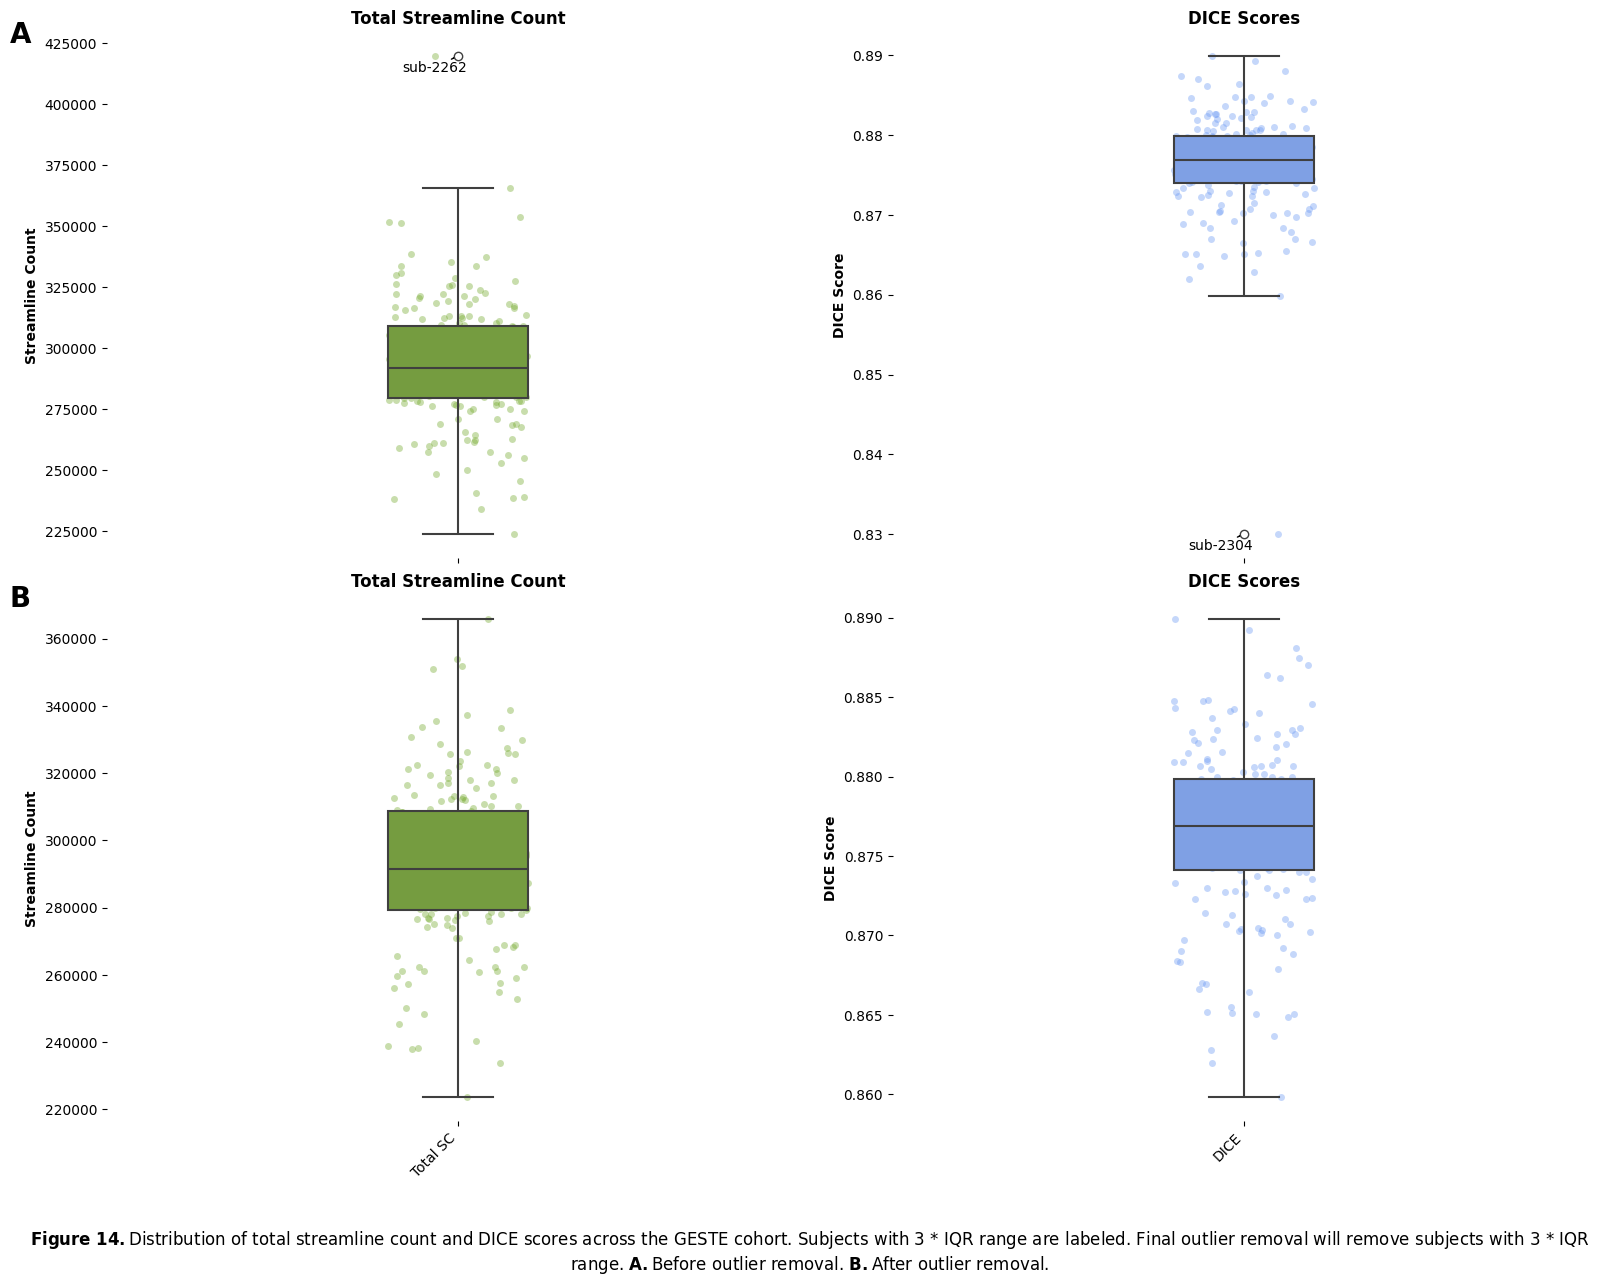

In [121]:
# Set color palette.
colors = sns.color_palette("husl", n_colors=10)

# Plot the distribution of total streamline count.
fig, ax = plt.subplots(2, 2, figsize=(16, 12))
sc_box = sns.boxplot(data=total_sc_count.iloc[:, 1:], ax=ax[0, 0], whis=3, color=colors[3],
                     width=0.2, linewidth=1.5, zorder=2)
sns.stripplot(data=total_sc_count.iloc[:, 1:], ax=ax[0, 0], alpha=0.4, color=colors[3],
              zorder=1)
ax[0, 0].set_title("Total Streamline Count", fontsize=12, fontweight='bold')
ax[0, 0].set_ylabel("Streamline Count", fontsize=10, fontweight='bold')
ax[0, 0].figure.autofmt_xdate(rotation=45, ha='right')
ax[0, 0].spines[["top", "right", "left", "bottom"]].set_visible(False)

# Add subject id to points outside the 3 * IQR range for the total streamline count data.
iqr = []
for roi in total_sc_count.columns[1:]:
    q75, q25 = np.percentile(total_sc_count[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

text = []
for i, roi in enumerate(total_sc_count.columns[1:]):
    for j, val in enumerate(total_sc_count[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            text.append(ax[0, 0].text(i, val, total_sc_count["subjectkey"][j], ha='center', va='center', fontsize=10, color='black'))
adjust_text(text, ax=ax[0, 0], iter_lim=1000, arrowprops=dict(arrowstyle='->', color='black'))

# Plot the distribution of DICE scores.
dice_box = sns.boxplot(data=dice_df.iloc[:, 1:], ax=ax[0, 1], whis=3, color=colors[7],
                       width=0.2, linewidth=1.5, zorder=2)
sns.stripplot(data=dice_df.iloc[:, 1:], ax=ax[0, 1], alpha=0.4, color=colors[7],
              zorder=1)
ax[0, 1].set_title("DICE Scores", fontsize=12, fontweight='bold')
ax[0, 1].set_ylabel("DICE Score", fontsize=10, fontweight='bold')
ax[0, 1].figure.autofmt_xdate(rotation=45, ha='right')
ax[0, 1].spines[["top", "right", "left", "bottom"]].set_visible(False)

# Add subject id to points outside the 3 * IQR range for the DICE score data.
iqr = []
for roi in dice_df.columns[1:]:
    q75, q25 = np.percentile(dice_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

text = []
for i, roi in enumerate(dice_df.columns[1:]):
    for j, val in enumerate(dice_df[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            text.append(ax[0, 1].text(i, val, dice_df["subjectkey"][j], ha='center', va='center', fontsize=10, color='black'))
adjust_text(text, ax=ax[0, 1], iter_lim=1000, arrowprops=dict(arrowstyle='->', color='black'))

# Removing subjects with total streamline count outside the 3 * IQR range.
iqr = []
for roi in total_sc_count.columns[1:]:
    q75, q25 = np.percentile(total_sc_count[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

# Removing subjects with total streamline count outside the 3 * IQR range.
sc_ids = []
for i, roi in enumerate(total_sc_count.columns[1:]):
    for j, val in enumerate(total_sc_count[roi]):
        if val < iqr[i][0] or val > iqr[i][1]:
            sc_ids.append(total_sc_count["subjectkey"][j])

# Print the IDs of the subjects with total streamline count outside the 3 * IQR range.
print(f"Number of subjects with total streamline count outside the 3 * IQR range: {len(np.unique(sc_ids))}")

# Remove subjects with total streamline count outside the 3 * IQR range.
total_sc_count_QCed = total_sc_count[~total_sc_count["subjectkey"].isin(sc_ids)]
total_sc_count_QCed.reset_index(inplace=True, drop=True)

# Remove subjects with DICE score under the 3 * IQR range.
iqr = []
for roi in dice_df.columns[1:]:
    q75, q25 = np.percentile(dice_df[roi], [75, 25])
    intr_qr = q75 - q25
    qmax = q75 + (3 * intr_qr)
    qmin = q25 - (3 * intr_qr)
    iqr.append([qmin, qmax])

# Removing subjects with DICE score outside the 3 * IQR range.
dice_ids = []
for i, roi in enumerate(dice_df.columns[1:]):
    for j, val in enumerate(dice_df[roi]):
        if val < iqr[i][0]: # ONLY UNDER THE 3 * IQR RANGE.
            dice_ids.append(dice_df["subjectkey"][j])

# Print the IDs of the subjects with DICE score under the 3 * IQR range.
print(f"Number of subjects with DICE score under the 3 * IQR range: {len(np.unique(dice_ids))}")

# Remove subjects with DICE score under the 3 * IQR range.
dice_df_QCed = dice_df[~dice_df["subjectkey"].isin(dice_ids)]
dice_df_QCed.reset_index(inplace=True, drop=True)

# Add QC distribution to the plot.
sc_box_QCed = sns.boxplot(data=total_sc_count_QCed.iloc[:, 1:], ax=ax[1, 0], whis=3, color=colors[3],
                          width=0.2, linewidth=1.5, zorder=2)
sns.stripplot(data=total_sc_count_QCed.iloc[:, 1:], ax=ax[1, 0], alpha=0.4, color=colors[3],
              zorder=1)
ax[1, 0].set_title("Total Streamline Count", fontsize=12, fontweight='bold')
ax[1, 0].set_ylabel("Streamline Count", fontsize=10, fontweight='bold')
ax[1, 0].figure.autofmt_xdate(rotation=45, ha='right')
ax[1, 0].spines[["top", "right", "left", "bottom"]].set_visible(False)

# Add DICE QCed distribution to the plot.
dice_box_QCed = sns.boxplot(data=dice_df_QCed.iloc[:, 1:], ax=ax[1, 1], whis=3, color=colors[7],
                            width=0.2, linewidth=1.5, zorder=2)
sns.stripplot(data=dice_df_QCed.iloc[:, 1:], ax=ax[1, 1], alpha=0.4, color=colors[7],
              zorder=1)
ax[1, 1].set_title("DICE Scores", fontsize=12, fontweight='bold')
ax[1, 1].set_ylabel("DICE Score", fontsize=10, fontweight='bold')
ax[1, 1].figure.autofmt_xdate(rotation=45, ha='right')
ax[1, 1].spines[["top", "right", "left", "bottom"]].set_visible(False)

# Add labels for upper and lower rows.
plt.gcf().text(0, 0.96, "A", fontsize=20, fontweight='bold')
plt.gcf().text(0, 0.49, "B", fontsize=20, fontweight='bold')

txt = r"$\bf{"+str("Figure\ 14.")+"}$" + "Distribution of total streamline count and DICE scores across the GESTE cohort. " + \
        "Subjects with 3 * IQR range are labeled. Final outlier removal will remove subjects with 3 * IQR range. " + \
        r"$\bf{"+"A."+"}$" + "Before outlier removal. " + r"$\bf{"+"B."+"}$" + "After outlier removal."

plt.figtext(0.5, -0.06, txt, wrap=True, horizontalalignment='center', fontsize=12)

# Save the plot.
plt.tight_layout()
plt.savefig(f"{output_dir}/GESTE_total_sc_DICE_score.png", dpi=900, bbox_inches='tight')

In [122]:
# Saving the QCed total streamline count and DICE scores.
total_sc_count_QCed.to_csv(f"{output_dir}/GESTE_total_sc_QCed.csv", index=False, header=True)
dice_df_QCed.to_csv(f"{output_dir}/GESTE_dice_scores_QCed.csv", index=False, header=True)

# Merging the removed subids from thickness, volume, area, total streamline count and DICE scores.
excluded_subs = excluded_subs.union(sc_ids).union(dice_ids)
print(f"Total number of subjects excluded from all data: {len(excluded_subs)}")

# Save the excluded subjects.
with open(f"{output_dir}/GESTE_excluded_subjects.txt", "w") as f:
    for sub in excluded_subs:
        f.write(f"{sub}\n")

Total number of subjects excluded from all data: 14
